# Import the dataset 

In [77]:
#To install libraries
# !pip install numpy
# !pip install pandas
# !pip install matplotlib
# !pip install DateTime
# !pip install requests
# !pip install opencv-python
# !pip install Pillow
# !pip install Shapely
# !pip install seaborn
# !pip install opencv-python

In [2]:
#Change it to your name 
PERSONAL_OUTPUT = "howard"

##Configurable for each camera
ROUTE_DIR = "b_PIE"
CAMERA_ID = "2705"
# ROUTE_DIR = "aye_jurong"
# CAMERA_ID = "4702"
#only this is to modified for april 2022
GOOGLE_DIR = "march_google_2022"
CNN_DIR = "march_cnn_2022"
MONTH = "3"

### Environment variables

In [3]:
# !conda install seaborn
import pandas as pd
from io import BytesIO
import numpy as np
import cv2,os,requests

import warnings
warnings.filterwarnings('ignore')

from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
from PIL import Image,ImageDraw

BASE_DIR = os.getcwd()
INPUT_DIR = "input"
OUTPUT_CSV = "output_csv_transformer_test"
OUTPUT_IMG = "output_img_transformer_test"


CNN_FORMATTED = "masked_cnn"
COMBINED_DIR = "combined_cnn_google"
GOOGLE_FORMATED  ="google_speed"

print(BASE_DIR)
#input
INPUT_DIR_PATH = os.path.join(BASE_DIR , INPUT_DIR)
print("INPUT_DIR_PATH :: ", INPUT_DIR_PATH)

GOOGLE_PATH = os.path.join(INPUT_DIR_PATH , GOOGLE_DIR)
print("GOOGLE_PATH :: ", GOOGLE_PATH)

CNN_PATH =  os.path.join(INPUT_DIR_PATH , CNN_DIR)
print("CNN_PATH :: ", CNN_PATH)

ROUTE_PATH = os.path.join(GOOGLE_PATH , ROUTE_DIR)
print("ROUTE_DIR :: ", ROUTE_PATH)

GOOGLE_CAMERA_PATH = os.path.join(ROUTE_PATH , CAMERA_ID)
print("GOOGLE_CAMERA_PATH :: ", GOOGLE_CAMERA_PATH)

CNN_CAMERA_PATH = os.path.join(CNN_PATH , CAMERA_ID)
print("CNN_CAMERA_PATH :: ", CNN_CAMERA_PATH)

print()
##Output
OUTPUT_CSV_PATH = os.path.join(BASE_DIR , OUTPUT_CSV)

if not os.path.exists(OUTPUT_CSV_PATH):
    os.mkdir(OUTPUT_CSV_PATH)
print("OUTPUT_CSV_PATH :: ", OUTPUT_CSV_PATH)
        
OUTPUT_IMG_PATH = os.path.join(BASE_DIR , OUTPUT_IMG)
print("OUTPUT_IMG_PATH :: ", OUTPUT_IMG_PATH)

if not os.path.exists(OUTPUT_IMG_PATH):
    os.mkdir(OUTPUT_IMG_PATH)
    
    
#output configurable
MASKED_IMG= os.path.join(OUTPUT_IMG_PATH , MONTH+"_"+ROUTE_DIR+"_"+str(CAMERA_ID)+".jpg")
print("MASKED_IMG :: ",MASKED_IMG)


OUTPUT_ROUTE_PATH = os.path.join(OUTPUT_CSV_PATH , ROUTE_DIR)
print("OUTPUT_ROUTE_PATH :: ", OUTPUT_ROUTE_PATH)

if not os.path.exists(OUTPUT_ROUTE_PATH):
    os.mkdir(OUTPUT_ROUTE_PATH)
    
OUTPUT_CAMERA_PATH = os.path.join(OUTPUT_ROUTE_PATH , CAMERA_ID)
print("OUTPUT_CAMERA_PATH :: ", OUTPUT_CAMERA_PATH)

if not os.path.exists(OUTPUT_CAMERA_PATH):
    os.mkdir(OUTPUT_CAMERA_PATH)
    

C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022\2705

OUTPUT_CSV_PATH ::  C:\Users\Padmapriya\Docum

In [4]:
def define_path(ROUTE_DIR,CAMERA_ID,GOOGLE_DIR,CNN_DIR,MONTH):
    INPUT_DIR_PATH = os.path.join(BASE_DIR , INPUT_DIR)
    print("INPUT_DIR_PATH :: ", INPUT_DIR_PATH)

    GOOGLE_PATH = os.path.join(INPUT_DIR_PATH , GOOGLE_DIR)
    print("GOOGLE_PATH :: ", GOOGLE_PATH)

    CNN_PATH =  os.path.join(INPUT_DIR_PATH , CNN_DIR)
    print("CNN_PATH :: ", CNN_PATH)

    ROUTE_PATH = os.path.join(GOOGLE_PATH , ROUTE_DIR)
    print("ROUTE_DIR :: ", ROUTE_PATH)

    GOOGLE_CAMERA_PATH = os.path.join(ROUTE_PATH , CAMERA_ID)
    print("GOOGLE_CAMERA_PATH :: ", GOOGLE_CAMERA_PATH)

    CNN_CAMERA_PATH = os.path.join(CNN_PATH , CAMERA_ID)
    print("CNN_CAMERA_PATH :: ", CNN_CAMERA_PATH)

    print()
    ##Output
    OUTPUT_PATH = os.path.join(BASE_DIR , OUTPUT_CSV)
    print("OUTPUT_PATH :: ", OUTPUT_PATH)
    
    if not os.path.exists(OUTPUT_PATH):
        os.mkdir(OUTPUT_PATH)
    
    OUTPUT_CSV_PATH = os.path.join(OUTPUT_PATH , MONTH)
    print("OUTPUT_CSV_PATH :: ", OUTPUT_CSV_PATH)
    
    if not os.path.exists(OUTPUT_CSV_PATH):
        os.mkdir(OUTPUT_CSV_PATH)

    OUTPUT_IMG_PATH = os.path.join(BASE_DIR , OUTPUT_IMG)
    print("OUTPUT_IMG_PATH :: ", OUTPUT_IMG_PATH)

    if not os.path.exists(OUTPUT_IMG_PATH):
        os.mkdir(OUTPUT_IMG_PATH)

    #output configurable
    MASKED_IMG= os.path.join(OUTPUT_IMG_PATH , MONTH+"_"+ROUTE_DIR+"_"+str(CAMERA_ID)+".png")
    print("MASKED_IMG :: ",MASKED_IMG)
    
    BB_IMG= os.path.join(OUTPUT_IMG_PATH , MONTH+"_"+ROUTE_DIR+"_"+str(CAMERA_ID)+"_boundingbox.png")
    print("BB_IMG :: ",BB_IMG)
    

    return INPUT_DIR_PATH,GOOGLE_PATH,CNN_PATH,ROUTE_PATH,GOOGLE_CAMERA_PATH,CNN_CAMERA_PATH,OUTPUT_CSV_PATH,OUTPUT_IMG_PATH,MASKED_IMG,BB_IMG
    

In [5]:
def get_google_cnn_file_list(GOOGLE_CAMERA_PATH):
    google_file_list = os.listdir(GOOGLE_CAMERA_PATH) #lists the names of all the files in the directory
    #print(google_file_list)

    cnn_file_list = []
    for i in range(len(google_file_list)):
        name_split= google_file_list[i].split('_') #splits the names into a list, delimiter '-'
#         print("file_name_split = ",name_split)


        if(name_split[2] == "wl" or  name_split[2] == "pie"): #some route names are 3 word instead of 2 word
            date_split = name_split[4].split("-")
            cnn_file_name = CAMERA_ID+ "_" + date_split[0] + "-" +MONTH+ "-" + date_split[2] +"_cnn.csv"
            print("cnn_file_name : ",cnn_file_name)

            cnn_file_list.append(cnn_file_name)
            #print("cnn_file_list from dir :: ",os.listdir(CNN_CAMERA_PATH))


        else:
            date_split = name_split[3].split("-")
            cnn_file_name = CAMERA_ID+ "_" + date_split[0] + "-" +MONTH+ "-" + date_split[2] +"_cnn.csv"
            print("cnn_file_name : ",cnn_file_name)

            cnn_file_list.append(cnn_file_name)
            #print("cnn_file_list from dir :: ",os.listdir(CNN_CAMERA_PATH))
    return google_file_list, cnn_file_list


### Read masking coordinates from CSV

In [6]:
#https://stackoverflow.com/questions/8490955/converting-a-string-to-a-list-of-tuples
def findMaskingCoordinates(ROUTE_DIR,CAMERA_ID):
    coord_df = pd.read_csv('masking - cam_masking_coordinates_complete_status.csv', sep = ',')

    coord_df[['Route','Cam_id' ]] = coord_df[['Route','Cam_id' ]].astype(str) #read the integers into strings
    coord_df  = coord_df.loc[(coord_df['Route']==ROUTE_DIR) & (coord_df['Cam_id']==CAMERA_ID)] 

    xy = coord_df['masking_xy_march 2022'].item()
    xy = list(eval(xy))
    print("Masking coordinate xy = ",xy)
    return xy


## Read RCNN csv data

In [7]:
def read_cnn_csv(cnn_csv_file):
    #Read as dataframe
    df = pd.read_csv(cnn_csv_file)
    print("Total of objects in the dataset:", len(df))
    df  = df.loc[ (df['Detection_Class']==3) | 
                  (df['Detection_Class']==6) | 
                  (df['Detection_Class']==8)]
    df  = df.loc[ (df['Cam_ID']== int(CAMERA_ID))  ] #Subset objects that are only vehicles from camera #honestly this line is not needed
    #df  = df.loc[ (df['Detection_Score']<0.3)] #only choose objects detected with <0.3 accruracy
    print("Total of objects that are vehicles in camera", CAMERA_ID ,":", len(df))

    #print(df.columns)
    return df


### Check the size of the image

In [8]:
def check_img_size(df):
    
    photo_indices=[400, 800, 1000]
    for photo_index in photo_indices:
        # Check if photo_index is within the valid range
        if photo_index < 0 or photo_index >= len(df):
            print(f"Invalid photo_index: {photo_index}. It should be between 0 and {len(df) - 1}.")
            continue

        # Plot the specified photo
        photo_url = df['URL'].values[photo_index]
        response = requests.get(photo_url)

        try:
            img = Image.open(BytesIO(response.content))
            
            plt.figure(figsize=(10, 10))
            plt.imshow(img)
            plt.title("Sample Image from the camera", fontsize=20)
            plt.grid()
            plt.show()
            
            first_pic_time = df['Timestamp_sg_time'].values[photo_index]
            print(f"Camera {CAMERA_ID} at {first_pic_time}")

            return img,photo_url
            
        except Exception as e:
            print(f"Error loading image at index {photo_index}: {e}")
            continue


### Plot bounding boxes

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_bounding_boxes(ax,df, url, line_width=0.75, edgecolor='r'):
    
    selected_df = df[df['URL'] == url]
    ymins = selected_df['ymin']
    xmins = selected_df['xmin']
    ymaxs = selected_df['ymax']
    xmaxs = selected_df['xmax']
    
    for y_min, x_min, y_max, x_max in zip(ymins, xmins, ymaxs, xmaxs):
        # Convert coordinates to integers
        y_min, x_min, y_max, x_max = int(y_min), int(x_min), int(y_max), int(x_max)

        # Create a Rectangle patch with reduced line width
        rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth=line_width, edgecolor=edgecolor, facecolor='none')

        # Add the patch to the Axes
        ax.add_patch(rect)
        
def plot_bounding_boxes_w_original_image(df, image, url):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))

    # Original image
    ax1.imshow(image)
    ax1.set_title("Original Image")

    # Image with bounding boxes
    image_with_boxes = image.copy()  # Create a copy of the original image
    ax2.imshow(image_with_boxes)
    ax2.set_title("Image with Bounding Boxes")

    draw_bounding_boxes(ax2,df, url)

    plt.show()
    
    
def plot_bounding_boxes(df, image, url,BB_IMG):
    plt.figure(figsize=(10, 10))

    # Image with bounding boxes
    image_with_boxes = image.copy()  # Create a copy of the original image
    plt.imshow(image_with_boxes)
    #plt.title("Image with Bounding Boxes")

    draw_bounding_boxes(plt.gca(),df, url)
    
    plt.savefig(BB_IMG, format='png',bbox_inches='tight', dpi=300)

    plt.show()

### Data Preprocessing

#### Create masks to drop undesired objects

In [10]:
#https://flutterq.com/how-to-draw-polygons-with-python/
#https://stackoverflow.com/questions/17109608/change-figure-size-and-figure-format-in-matplotlib
#https://stackoverflow.com/questions/42818361/how-to-make-two-plots-side-by-side-using-python

def create_mask_w_original_image(df, img, xy,url):
    
    df['x0'] = df['xmin']
    df['y0'] = df['ymin']
    df['width'] = df['xmax'] - df['xmin']
    df['height'] = df['ymax'] - df['ymin']

    try:
        original = img
        plt.figure(figsize=(20,22))
        plt.subplot(1, 2, 1) # row 1, col 2 index 1
        mask = Image.new("L", original.size, 0) #mode = L (8-bit pixels, black and white)
        draw = ImageDraw.Draw(mask) 
        draw.polygon(xy, fill=55, outline=None) #make the mask in the shape of the mask as defined in xy with colour is 55,55,55 which is white i think
        black =  Image.new("L", original.size, 0) #create a black and white pixel image of size=original.size with colour 0 (black)
        result = Image.composite(original, black, mask) #combine the images
        plt.title("Image without mask ", fontsize = 20)
        plt.imshow(img)
        ax = plt.gca()   
        
        #key error cause, original was df.at[0,'x0'], reads row 0, column 'x0' of df but we have filtered df in above function read_cnn_csv
        #this means row 0 may be filtered out from the df, which causes key error since row 0 does not exist anymore
        #use df.iloc[0]['y0'] to access first non-empty row of current df and column y0
        plt.grid()
        
        plt.subplot(1, 2, 2) # index 2

        ##Black mask
        plt.title("Masked ", fontsize = 20)
        plt.imshow(result) 
        draw_bounding_boxes(plt.gca(),df, url)
        result.save(MASKED_IMG)
        plt.grid()
        plt.show()

        return MASKED_IMG
    
    except Exception as e:
        print(str(e))
        

In [11]:
def create_mask(df, img, xy,url):
    
    df['x0'] = df['xmin']
    df['y0'] = df['ymin']
    df['width'] = df['xmax'] - df['xmin']
    df['height'] = df['ymax'] - df['ymin']

    try:
        original = img
        plt.figure(figsize=(10,10))
        
        draw_bounding_boxes(plt.gca(),df, url)
        
        mask = Image.new("L", original.size, 0) #mode = L (8-bit pixels, black and white)
        draw = ImageDraw.Draw(mask) 
        draw.polygon(xy, fill=55, outline=None) #make the mask in the shape of the mask as defined in xy with colour is 55,55,55 which is white i think
        black =  Image.new("L", original.size, 0) #create a black and white pixel image of size=original.size with colour 0 (black)
        result = Image.composite(original, black, mask) #combine the images
      
        ##Black mask
        plt.title("Masked ", fontsize = 20)
        plt.imshow(result) 
        plt.savefig(MASKED_IMG)
        plt.grid()
        plt.show()

        return MASKED_IMG
    
    except Exception as e:
        print(str(e))
        

We have created a mask that will block the area of the image that we don't want to consider in our analysis. This area has been computed manually using `xy = [(100,360),(350,150),(370,100),(430,50),(430,0),(500,0), (500,360)]`. You can always draw more complicated polygons by entering x,y vertices using the appropriate coordinates. 

#### To find the area in pixels of the image that are not masked

In [12]:
#https://stackoverflow.com/questions/57830697/calculating-the-area-covered-by-the-objects-of-irregular-shapes-in-an-image
#https://stackoverflow.com/questions/52676020/imread-returns-none-violating-assertion-src-empty-in-function-cvtcolor-er
def find_total_area(masked_img): #masked image is black with the non-masked part being some non-black colour
    try: 
        img = cv2.imread(masked_img) #read image
        gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) #grayscale the image
        ret, thresh = cv2.threshold(gray,0,255,cv2.THRESH_BINARY) #every pixel that isnt black is white(1), every black pixel stays black
        #cv2.imshow("Mask", thresh)
        #cv2.waitKey(0)
        #cv2.destroyAllWindows()
        total_area = cv2.countNonZero(thresh) #count the number of white pixels (since pixels are either 1(white) or 0(black))
        print("total_area = ", total_area)#, 'thresh=',thresh)
        
        return total_area
    
    except Exception as e:
        print(str(e))
    


#### Identify vehicles that are outside the 'black' mask

In [13]:
from shapely.geometry import Point
from shapely.geometry.polygon import Polygon

def check_masked_List(df,xy):
    try:
        polygon = Polygon(xy)

        maskedList = []

        for i in range(0,len(df)):
            points = Point((df['xmin'].iloc[i],  df['ymin'].iloc[i] ))  #only check the vertix (xmin,ymin)
            maskedList.append(polygon.intersects(points)) #returns a boolean 
        print("maskedList :: ",maskedList[0:2])

        return maskedList
    except Exception as e:
        print(str(e))


We have only verified the vertix `(xmin,ymin)`. Our result is correct, for instance, the first object (i.e., the car in the red bounding box) is contaned in the are outise the black mask (i.e., `True`) whereas the second object lies inside the black mask (i.e., `False`). 

#### Keep vehicles in the desired direction

Aggregate the total number of vehicles per minute

In [14]:
def keep_desired_vehicles(df, maskedList):
    df['desired'] = maskedList

    df2 = df
    df2['ones'] = 1            #Ones to sum up the total number of vehicles
    df2  = df.loc[ (df['desired']==True)  ] 
    
    #https://stackoverflow.com/questions/33810980/date-time-split-in-python
    df2['Timestamp_sg_time']= pd.to_datetime(df2['Timestamp_sg_time']) #Convert to datetime object
    df2['hour']=df2.Timestamp_sg_time.dt.hour

    df2['minute']=df2.Timestamp_sg_time.dt.minute
    #print(df2.hour, " " , df2.minute)

    return df2



### Hour vs No.of Vehicles

In [15]:
import seaborn as sns

def plot_hr_vs_totalvehicles(df2):
    plt.figure(figsize=(18,7))
    b = sns.countplot(x='hour', hue="Detection_Class", data=df2)
    b.axes.set_title("Count of different vehicles at each Hour",fontsize=25)
    b.set_xlabel("Hour",fontsize=20)
    b.set_ylabel("Vehicles",fontsize=20)
    plt.show()
    

### Time vs No.of Vehicles

In [16]:
  %%javascript
    IPython.OutputArea.auto_scroll_threshold = 9999

<IPython.core.display.Javascript object>

In [17]:
def plot_time_vs_totalvehicles(df2):
    df2_agg = df2.groupby('Timestamp_sg_time')['ones'].agg([('vehicles','sum')]) #add the values in the one's column for each row with the same timestamp   
    df2_agg['Timestamp_sg_time'] = df2_agg.index
    df2_agg['Timestamp_sg_time']= pd.to_datetime(df2_agg['Timestamp_sg_time'])
    
    print("Vehicle count and Timestamp")
    print(df2_agg.head)
    plt.figure(figsize=(50,12))
    plt.plot(df2_agg['Timestamp_sg_time'], df2_agg['vehicles'], "-o", label="Vehicles", linewidth=6)
    plt.title("Number of vechicles at each timestamp", fontsize = 35)
    plt.xlabel("Time", fontsize = 35)
    plt.ylabel("vehicles", fontsize = 35)
    plt.legend(loc='best' , prop={'size': 40})
    plt.xticks(fontsize=38)
    plt.yticks(fontsize=38)
    plt.show()
    return df2_agg


### Counting the objects identified based on the accuracy

In [18]:
def aggregate_cnn_data(df2):
    time_grouped = df2.groupby('Timestamp_sg_time')
    total_vehicles=[]
    acc_more_than_30=[]
    
    total_bounding_box_area=[]
    bounding_box_area_30=[]
    
    total_bb_area_ratio=[]
    bbratio_more_than_30=[]
    
    total_car_count =[]
    total_truck_count =[]
    total_bus_count =[]

    # iterate over each group
    for group_name, df_group in time_grouped:
        #print('TimeStamp {}'.format(group_name))

        #initialize
        count_more_30=0
        count_total=0
      
        bounding_box_area=0
        bb_more_30=0
        
        total_car_count.append(df_group['Detection_Class'].apply(lambda x: 1 if x == 3 else 0).sum())
        total_truck_count.append(df_group['Detection_Class'].apply(lambda x: 1 if x == 8 else 0).sum())
        total_bus_count.append(df_group['Detection_Class'].apply(lambda x: 1 if x == 6 else 0).sum())
 
        #iterate over each timestamp
        for row_index, row in df_group.iterrows():
            bounding_box_area+=row['Bounding_box_area']
            count_total+=1
            
            if(row['Detection_Score'] >.3):    
                count_more_30+=1
                bb_more_30+=row['Bounding_box_area']

        total_vehicles.append(count_total)
        acc_more_than_30.append(count_more_30)

        #For bounding box
        total_bounding_box_area.append(bounding_box_area)
        bounding_box_area_30.append(bb_more_30)

        total_ratio=(bounding_box_area/total_area)*100
        total_bb_area_ratio.append(total_ratio)

        #For bounding box by detection score
        ratio =(bb_more_30/total_area)*100
        bbratio_more_than_30.append(ratio)

    
    df2_agg['Vehicles_no_filer'] =total_vehicles
    df2_agg['Vehicles_acc_more_than_30'] =acc_more_than_30
 
    df2_agg['total_bounding_box_area_no filter']=total_bounding_box_area
    df2_agg['total_bounding_box_area_acc_more_than_30']=bounding_box_area_30
    
    #bounding_box_area_ratio
    df2_agg['bbratio_no_filter']=total_bb_area_ratio
    df2_agg['bbratio_acc_more_than_30']=bbratio_more_than_30
    df2_agg['road_area'] = total_area
    
    df2_agg['car'] =total_car_count
    df2_agg['truck'] =total_truck_count
    df2_agg['bus'] =total_bus_count
    
    
    return df2_agg

## Read google speed csv file

In [19]:
def read_google_csv(google_csv_file):
    google_df = pd.read_csv(google_csv_file)
    google_df.head
    return google_df


### Compute Speed km per hr

In [20]:
def compute_speed(google_df):
    google_df["avg_speed"] = google_df["Distance_value"]/google_df["Duration_value"]

    #print("Speed sample :: ",google_df["avg_speed"][0])
    
    ##Rounding off the speed to 2 decimal points
    google_df['avg_speed']=google_df['avg_speed'].apply(lambda x:round(x,2))

    print("Min, Max speed :: ",google_df['avg_speed'].min(),google_df['avg_speed'].max())
    
    google_df['Timestamp_sg_time']= pd.to_datetime(google_df['TimeStamp']) #Convert to datetime object
    speed_df = google_df[['Route','Camera_id','Timestamp_sg_time','avg_speed']].copy()
    return speed_df

### Time vs Speed

In [21]:
def generate_time_vs_speed(speed_df):
    plt.figure(figsize=(30,12))
    plt.plot(speed_df['Timestamp_sg_time'], speed_df['avg_speed'], "-o" , label = 'speed', linewidth=4)
    plt.title("Speed at each timestamp", fontsize = 30)
    plt.xlabel("Time", fontsize = 25)
    plt.ylabel("speed of vehicles", fontsize =30)
    plt.legend(loc='best' , prop={'size': 30})
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    plt.show()


In [22]:
def combine_google_lta(df2_agg,speed_df):
    masked_cnn=df2_agg.reset_index(drop=True)
    #print(len(masked_cnn))
    
    combined_df=pd.merge(speed_df,masked_cnn, how='left', on='Timestamp_sg_time')
    #print(combined_df.columns)
    print("len(combined_df) :: ",len(combined_df))
    print("*****************************************************************")
    combined_df.shape
    return combined_df


### Running for all the cameras in the folder at one shot

In [23]:
GOOGLE_DIR = "march_google_2022"
CNN_DIR = "march_cnn_2022_transformer"
MONTH = "3"

coord_df = pd.read_csv('masking - cam_masking_coordinates_complete_status.csv', sep = ',')
coord_df[['Route','Cam_id' ]] = coord_df[['Route','Cam_id' ]].astype(str) #read the integers into strings
all_route = coord_df['Route'].unique();

In [24]:
unique_route= ['b_PIE','b_Woodlands']

In [25]:
def create_mask(df, img, xy, url,MASKED_IMG):
    df['x0'] = df['xmin']
    df['y0'] = df['ymin']
    df['width'] = df['xmax'] - df['xmin']
    df['height'] = df['ymax'] - df['ymin']

    try:
        original = img
        plt.figure(figsize=(10, 10))

        # Create a black mask
        black_mask = Image.new("L", original.size, 0)  # mode = L (8-bit pixels, black and white)
        draw_black_mask = ImageDraw.Draw(black_mask)
        draw_black_mask.polygon(xy, fill=255, outline=None)  # fill with white

        # Apply the black mask to the original image
        masked_image = Image.composite(original, black_mask, black_mask)

        # Create an Axes object
        ax = plt.gca()
        ax.imshow(masked_image, zorder=1)  # Set zorder for the image

        #plt.title("Masked ", fontsize=20)
        plt.grid()

        #draw_bounding_boxes(ax, df, url)

        plt.savefig(MASKED_IMG, format='png',bbox_inches='tight', dpi=300)
        plt.show()

        return MASKED_IMG

    except Exception as e:
        print(str(e))

b_PIE 2705
[(500, 10000), (500, 0), (10000, 5000)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705

OUTPUT_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehi

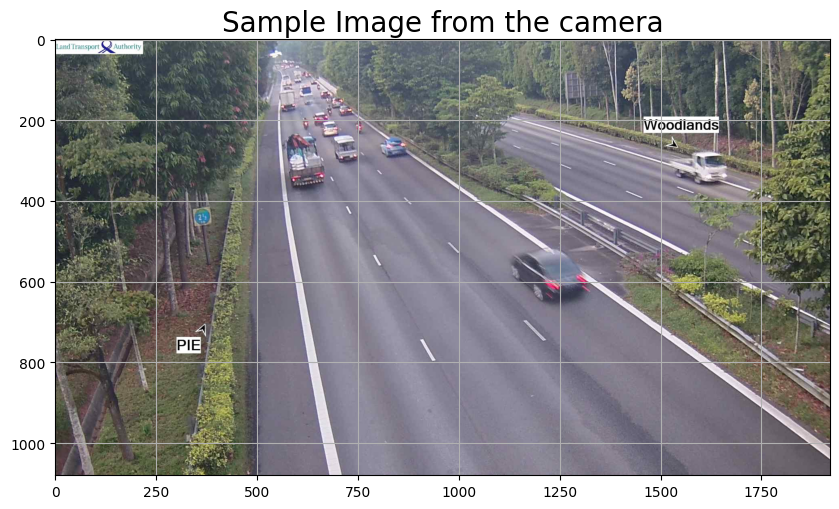

Camera 2705 at 2022-03-15 07:20:00


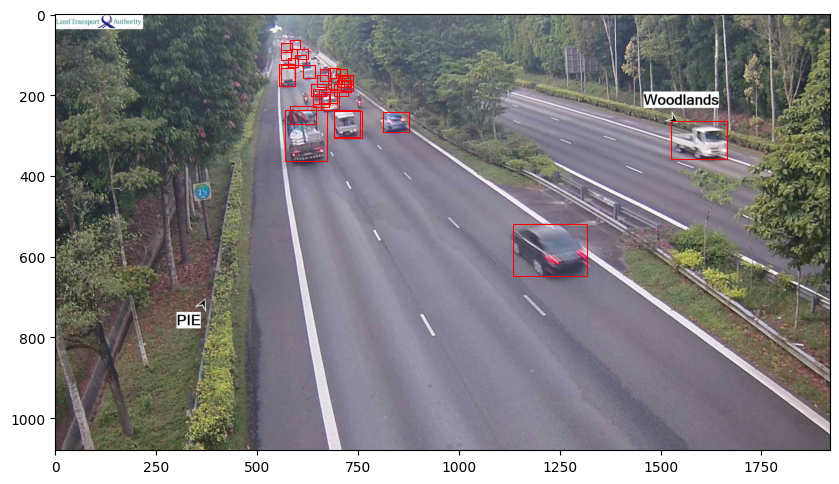

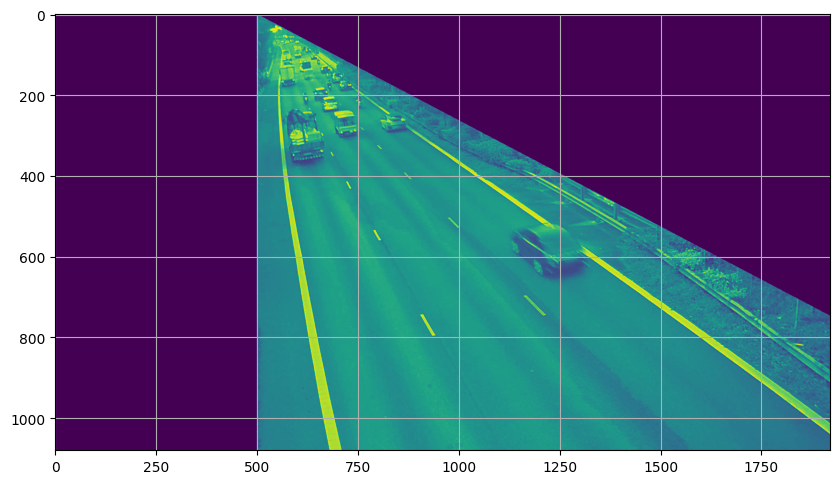

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 04:50:00         3 2022-03-15 04:50:00
2022-03-15 04:55:00         3 2022-03-15 04:55:00
2022-03-15 05:00:00         1 2022-03-15 05:00:00
2022-03-15 05:05:00         3 2022-03-15 05:05:00
2022-03-15 05:15:00         1 2022-03-15 05:15:00
...                       ...                 ...
2022-03-15 23:20:00         5 2022-03-15 23:20:00
2022-03-15 23:25:00         5 2022-03-15 23:25:00
2022-03-15 23:30:00         3 2022-03-15 23:30:00
2022-03-15 23:35:00         3 2022-03-15 23:35:00
2022-03-15 23:40:00         3 2022-03-15 23:40:00

[222 rows x 2 columns]>


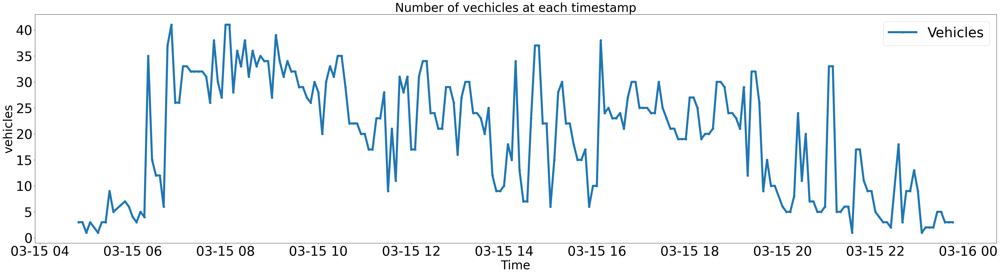

Min, Max speed ::  8.39 25.64


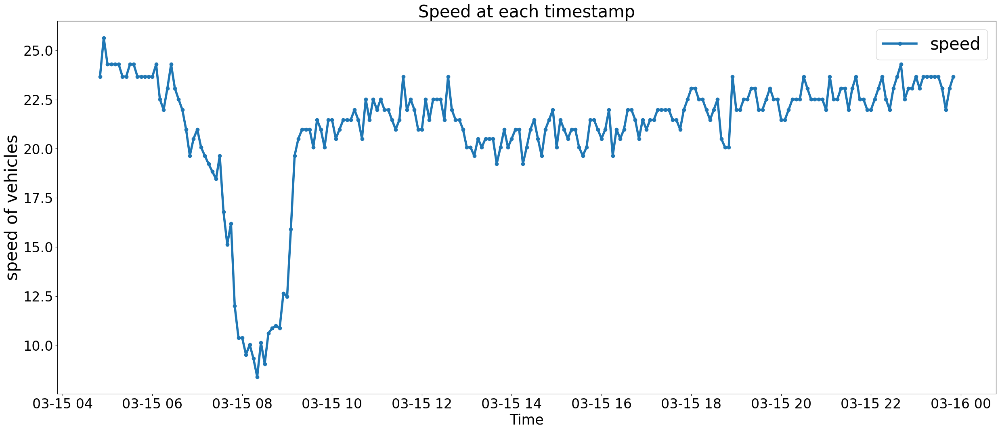

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705\2705_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705\b_PIE_2705_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2705_2022-03-16_Fullday.csv
Total of objects in the dataset: 5554
Total of objects that are vehicles in camera 2705 : 5441
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 05:00:00         1 2022-03-16 05:00:00
2022-03-16 05

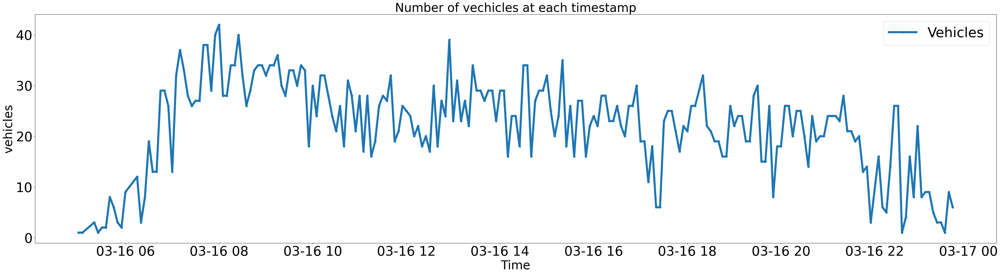

Min, Max speed ::  8.96 24.95


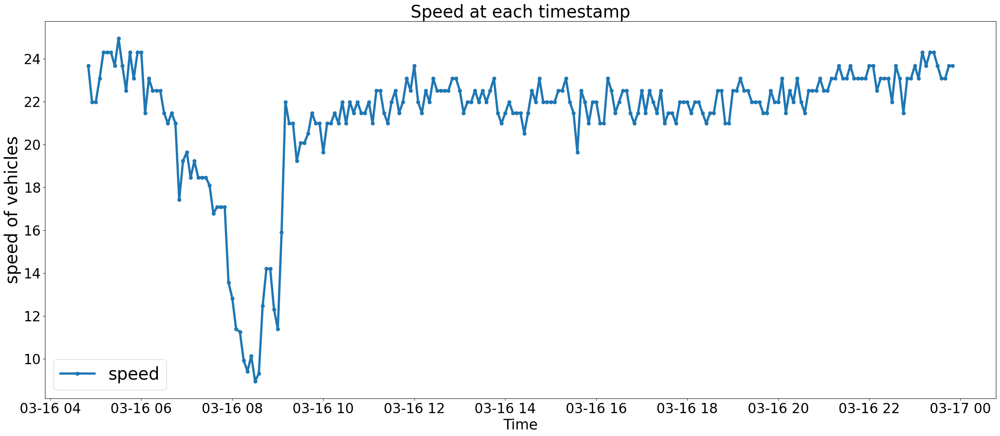

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705\2705_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705\b_PIE_2705_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2705_2022-03-17_Fullday.csv
Total of objects in the dataset: 5447
Total of objects that are vehicles in camera 2705 : 5297


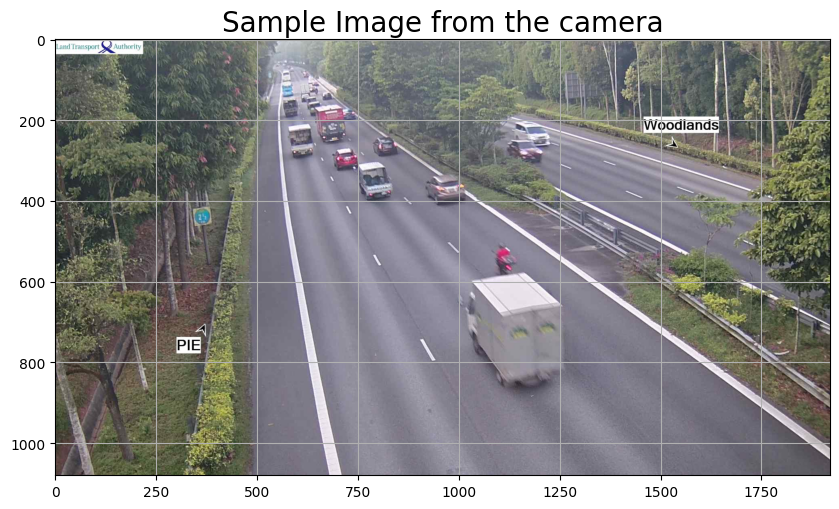

Camera 2705 at 2022-03-17 07:25:00


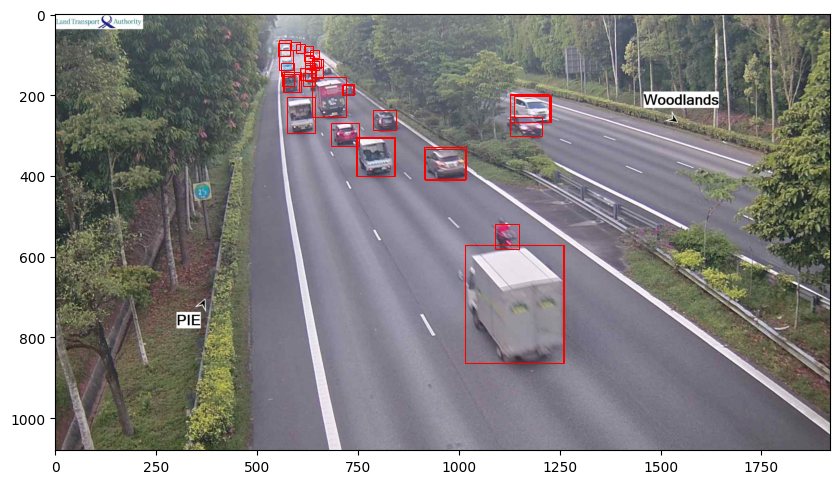

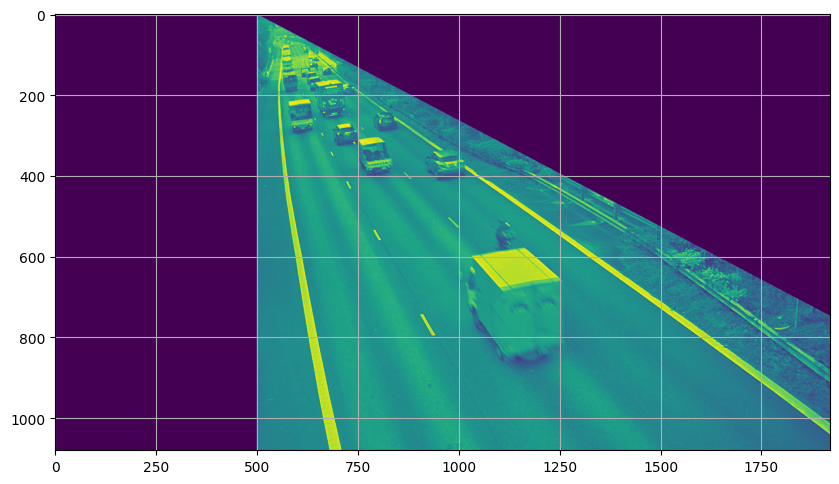

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 04:50:00         1 2022-03-17 04:50:00
2022-03-17 05:00:00         5 2022-03-17 05:00:00
2022-03-17 05:05:00         2 2022-03-17 05:05:00
2022-03-17 05:10:00         3 2022-03-17 05:10:00
2022-03-17 05:15:00         4 2022-03-17 05:15:00
...                       ...                 ...
2022-03-17 23:10:00        22 2022-03-17 23:10:00
2022-03-17 23:15:00        12 2022-03-17 23:15:00
2022-03-17 23:20:00        12 2022-03-17 23:20:00
2022-03-17 23:25:00        11 2022-03-17 23:25:00
2022-03-17 23:30:00         7 2022-03-17 23:30:00

[220 rows x 2 columns]>


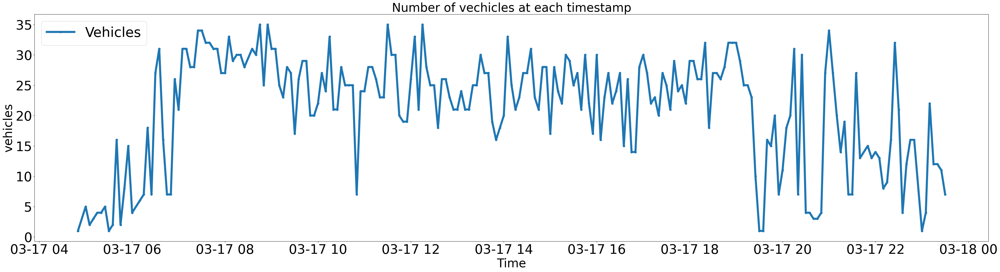

Min, Max speed ::  8.96 24.95


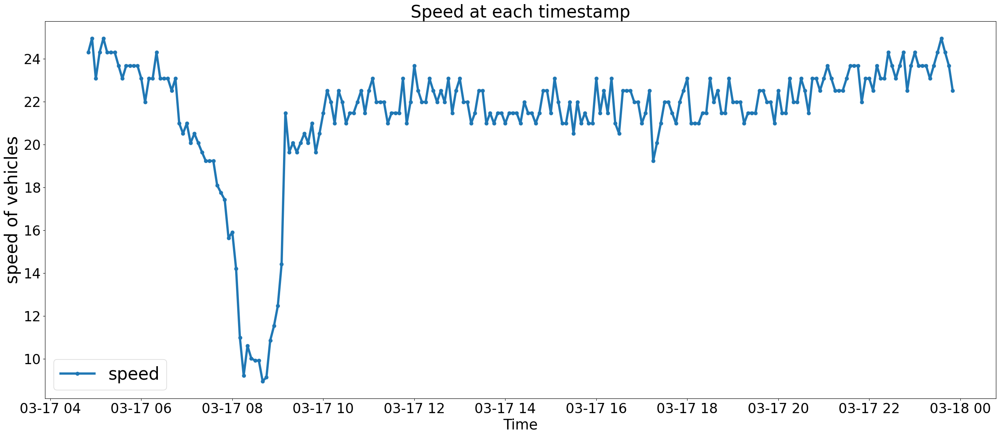

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705\2705_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705\b_PIE_2705_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2705_2022-03-18_Fullday.csv
Total of objects in the dataset: 5921
Total of objects that are vehicles in camera 2705 : 5783
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 05:00:00         4 2022-03-18 05:00:00
2022-03-18 05

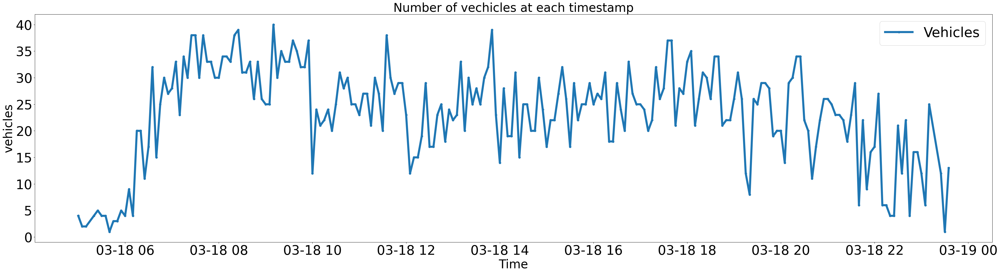

Min, Max speed ::  3.25 24.95


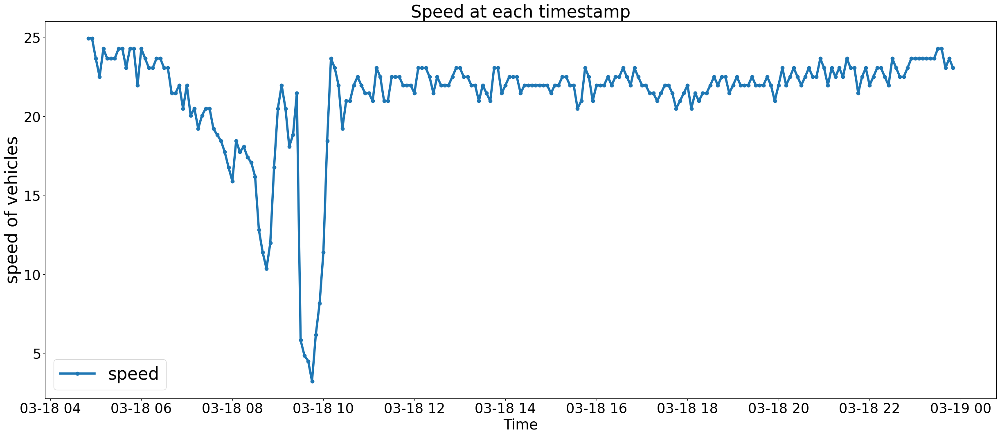

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705\2705_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705\b_PIE_2705_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2705_2022-03-19_Fullday.csv
Total of objects in the dataset: 5438
Total of objects that are vehicles in camera 2705 : 5346
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 04:50:00         2 2022-03-19 04:50:00
2022-03-19 05

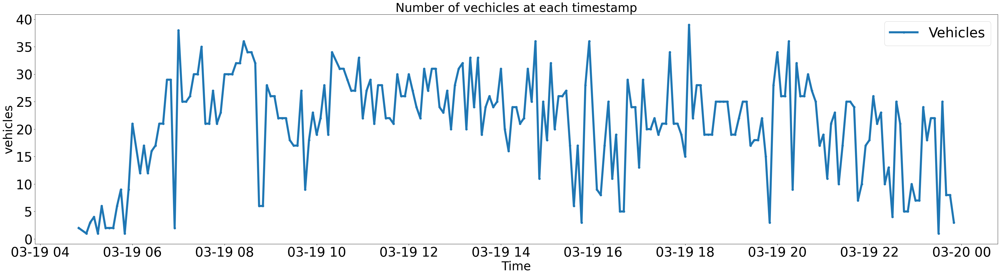

Min, Max speed ::  19.64 24.95


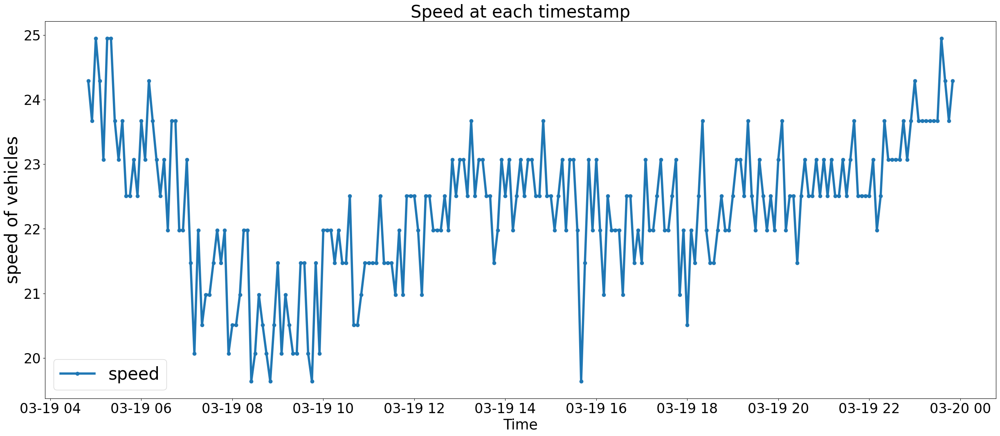

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705\2705_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705\b_PIE_2705_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2705_2022-03-20_Fullday.csv
Total of objects in the dataset: 5159
Total of objects that are vehicles in camera 2705 : 5034
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:50:00         5 2022-03-20 04:50:00
2022-03-20 05

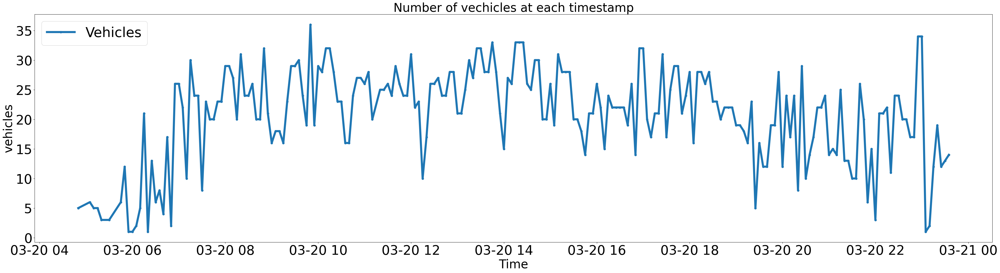

Min, Max speed ::  21.47 25.64


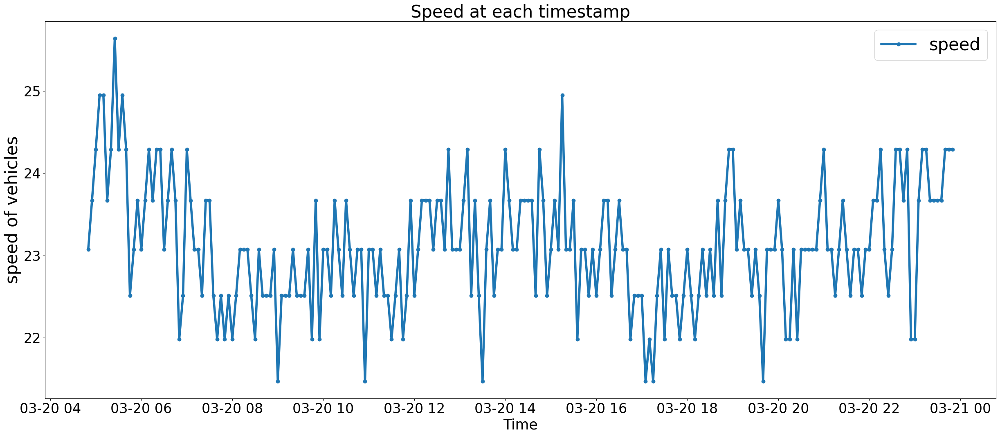

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2705\2705_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705\b_PIE_2705_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2705_2022-03-21_Fullday.csv
Total of objects in the dataset: 5693
Total of objects that are vehicles in camera 2705 : 5541
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 04:50:00         3 2022-03-21 04:50:00
2022-03-21 05

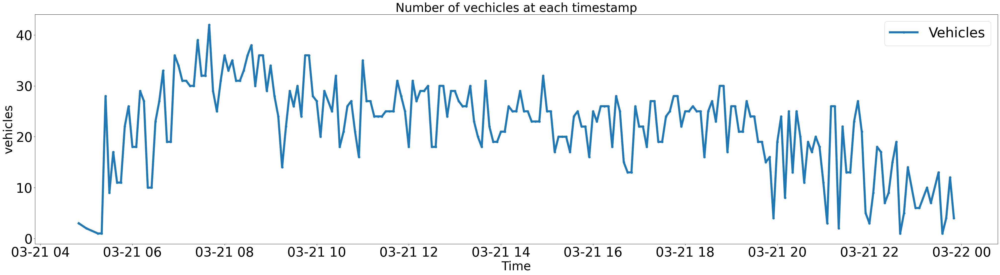

Min, Max speed ::  9.72 24.95


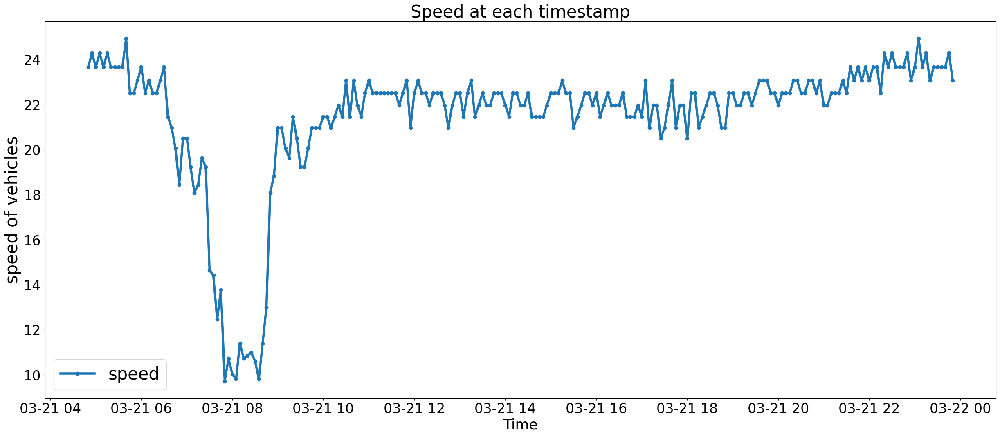

len(combined_df) ::  229
*****************************************************************
b_PIE 2706
[(750, 300), (750, 350), (2000, 1200), (3000, 1100)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\

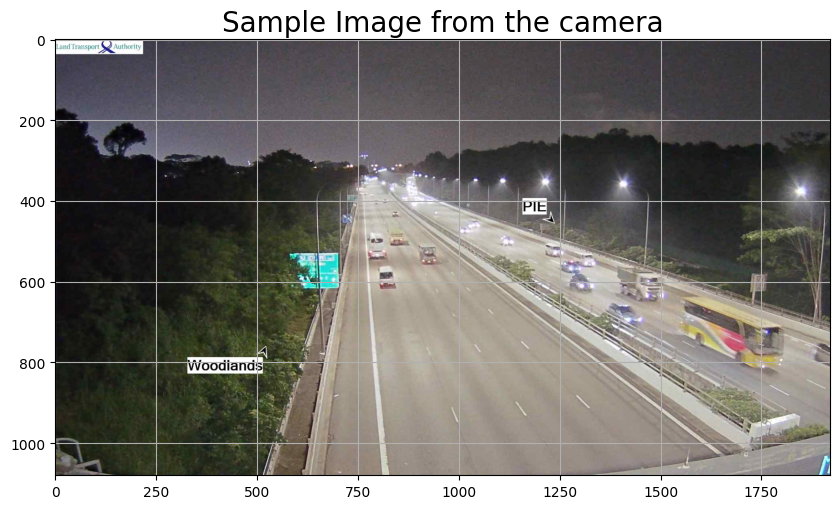

Camera 2706 at 2022-03-15 06:40:00


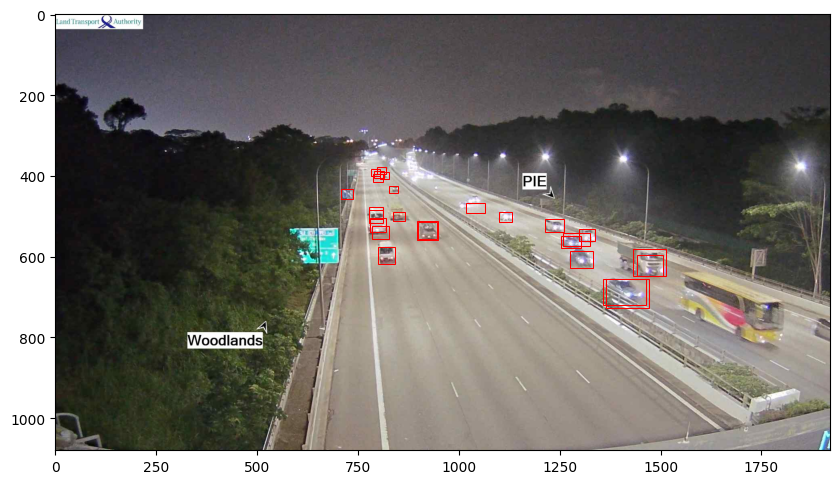

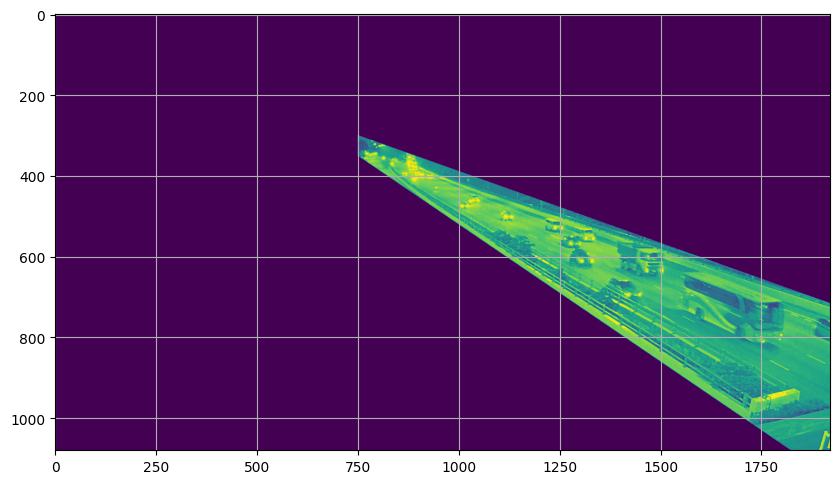

total_area =  3633691
maskedList ::  [False, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 04:50:00         2 2022-03-15 04:50:00
2022-03-15 05:00:00         5 2022-03-15 05:00:00
2022-03-15 05:05:00         7 2022-03-15 05:05:00
2022-03-15 05:10:00         4 2022-03-15 05:10:00
2022-03-15 05:15:00         6 2022-03-15 05:15:00
...                       ...                 ...
2022-03-15 23:10:00         1 2022-03-15 23:10:00
2022-03-15 23:15:00        20 2022-03-15 23:15:00
2022-03-15 23:20:00         1 2022-03-15 23:20:00
2022-03-15 23:25:00         1 2022-03-15 23:25:00
2022-03-15 23:40:00         6 2022-03-15 23:40:00

[224 rows x 2 columns]>


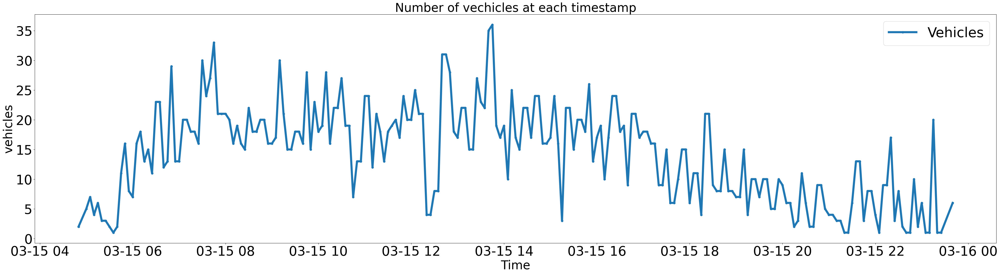

Min, Max speed ::  16.65 24.74


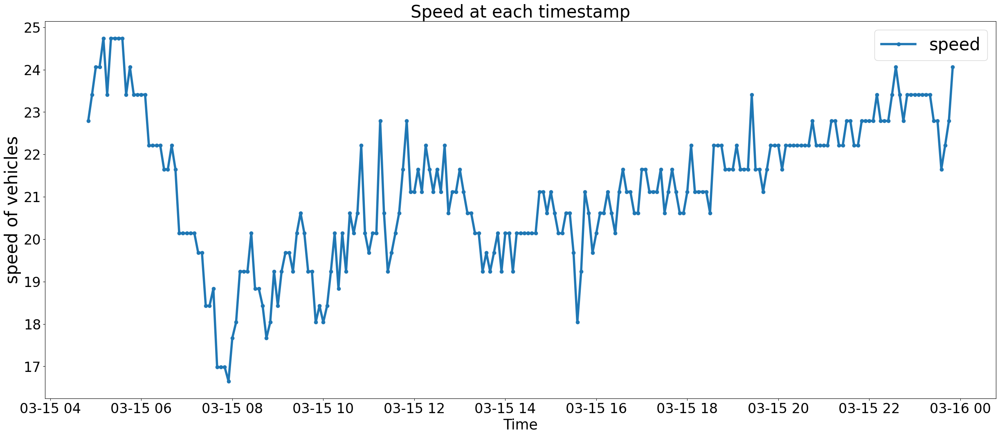

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706\b_PIE_2706_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2706_2022-03-16_Fullday.csv
Total of objects in the dataset: 7897
Total of objects that are vehicles in camera 2706 : 7765
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 05:00:00         1 2022-03-16 05:00:00
2022-03-16 

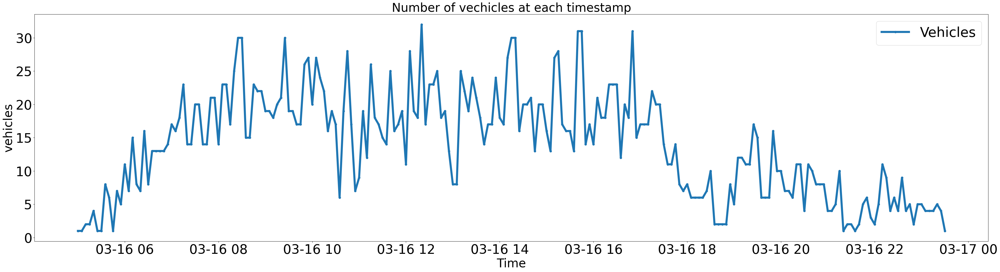

Min, Max speed ::  5.62 24.74


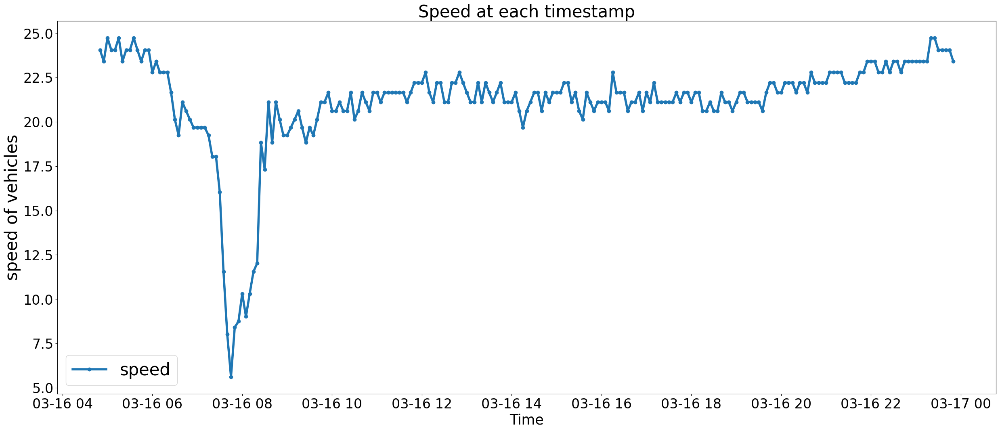

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706\b_PIE_2706_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2706_2022-03-17_Fullday.csv
Total of objects in the dataset: 8197
Total of objects that are vehicles in camera 2706 : 8017


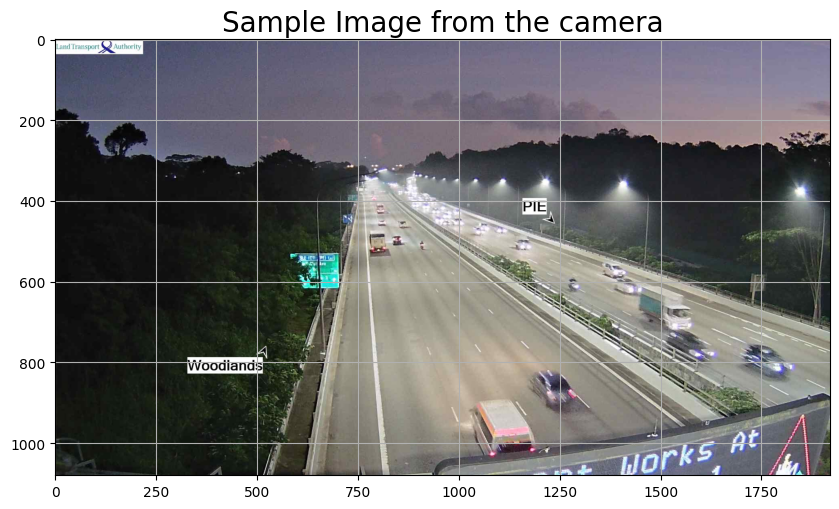

Camera 2706 at 2022-03-17 06:55:00


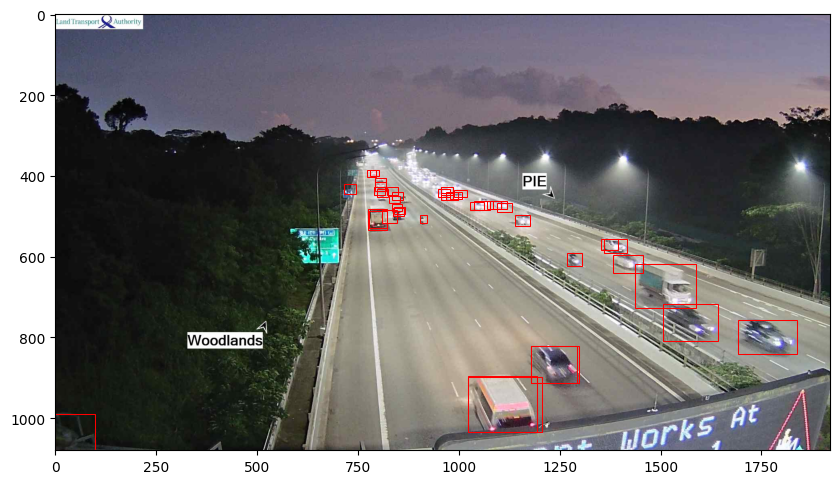

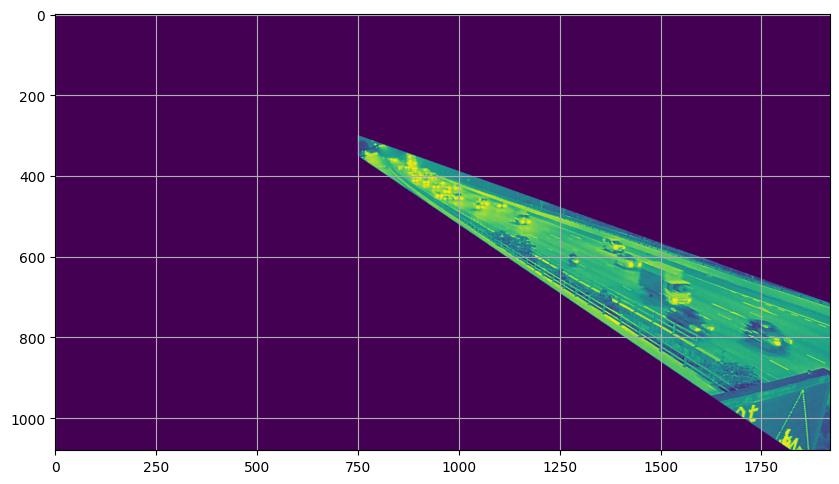

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 04:50:00         3 2022-03-17 04:50:00
2022-03-17 04:55:00         3 2022-03-17 04:55:00
2022-03-17 05:10:00         2 2022-03-17 05:10:00
2022-03-17 05:15:00         3 2022-03-17 05:15:00
2022-03-17 05:20:00         3 2022-03-17 05:20:00
...                       ...                 ...
2022-03-17 23:30:00         5 2022-03-17 23:30:00
2022-03-17 23:35:00         2 2022-03-17 23:35:00
2022-03-17 23:40:00         2 2022-03-17 23:40:00
2022-03-17 23:45:00         5 2022-03-17 23:45:00
2022-03-17 23:50:00         7 2022-03-17 23:50:00

[227 rows x 2 columns]>


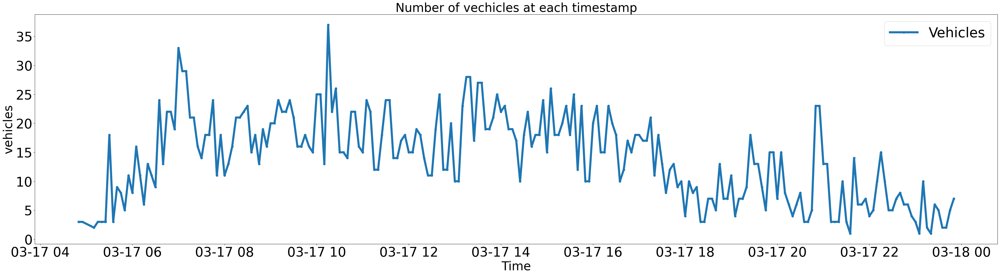

Min, Max speed ::  18.04 24.74


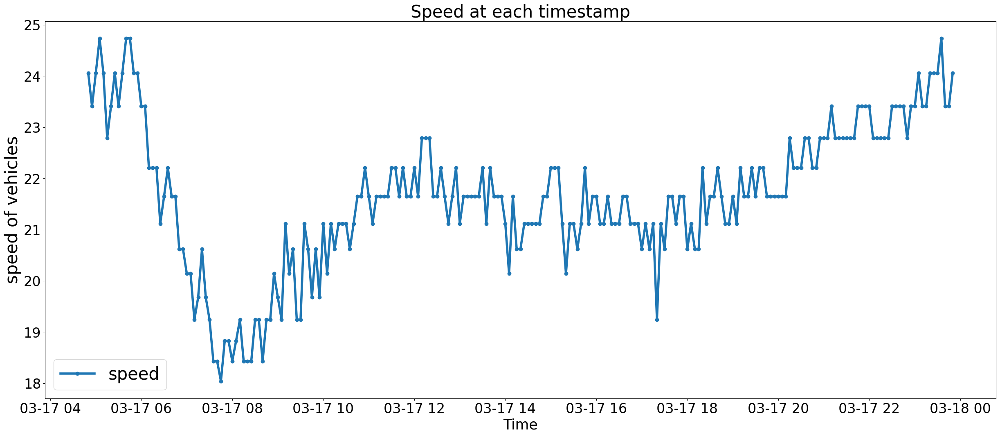

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706\b_PIE_2706_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2706_2022-03-18_Fullday.csv
Total of objects in the dataset: 8628
Total of objects that are vehicles in camera 2706 : 8475
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 04:50:00         7 2022-03-18 04:50:00
2022-03-18 04

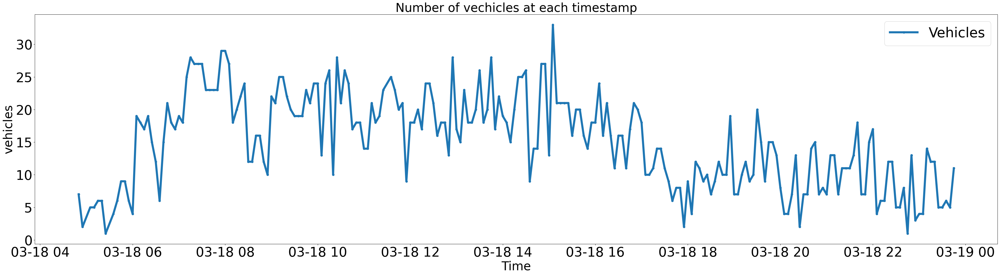

Min, Max speed ::  18.43 25.47


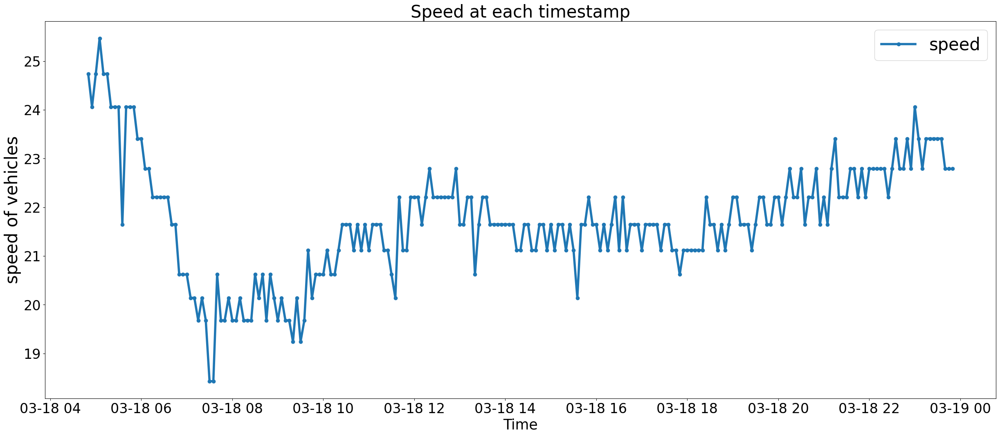

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706\b_PIE_2706_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2706_2022-03-19_Fullday.csv
Total of objects in the dataset: 8027
Total of objects that are vehicles in camera 2706 : 7866
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 04:50:00         9 2022-03-19 04:50:00
2022-03-19 04

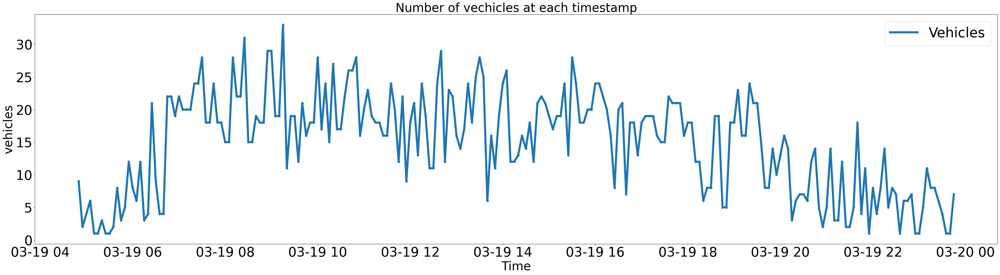

Min, Max speed ::  20.62 24.74


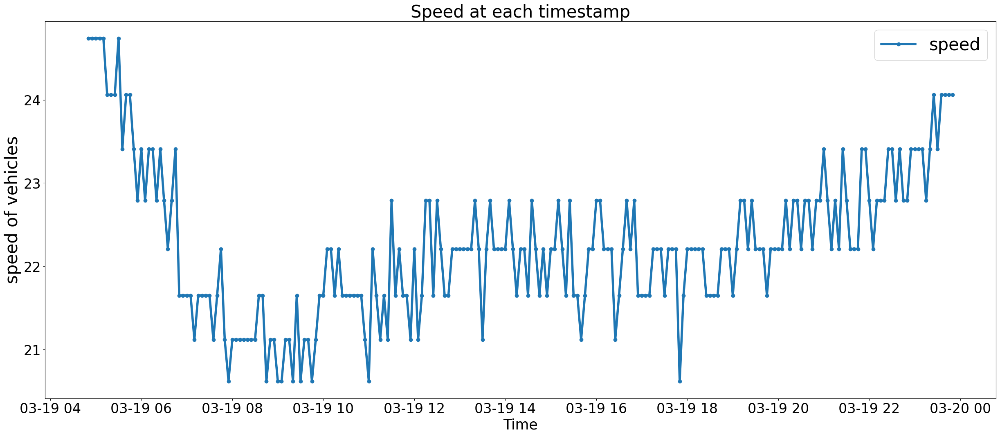

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706\b_PIE_2706_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2706_2022-03-20_Fullday.csv
Total of objects in the dataset: 7049
Total of objects that are vehicles in camera 2706 : 6938
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:50:00         1 2022-03-20 04:50:00
2022-03-20 

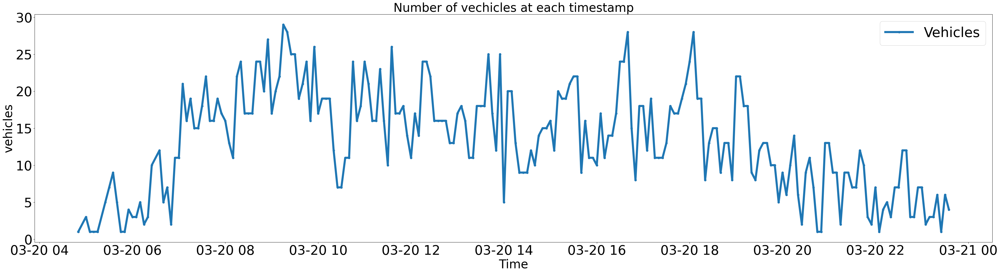

Min, Max speed ::  21.65 24.74


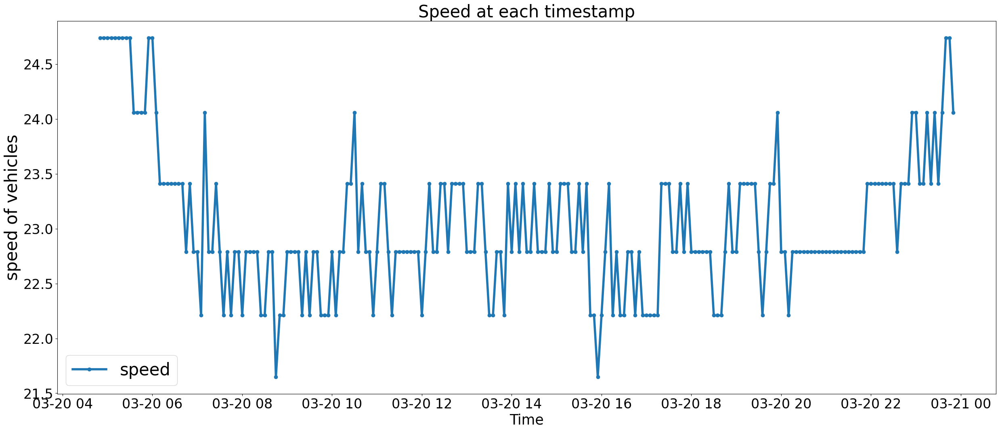

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2706\b_PIE_2706_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2706_2022-03-21_Fullday.csv
Total of objects in the dataset: 8333
Total of objects that are vehicles in camera 2706 : 8152
maskedList ::  [True, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 04:50:00         3 2022-03-21 04:50:00
2022-03-21 0

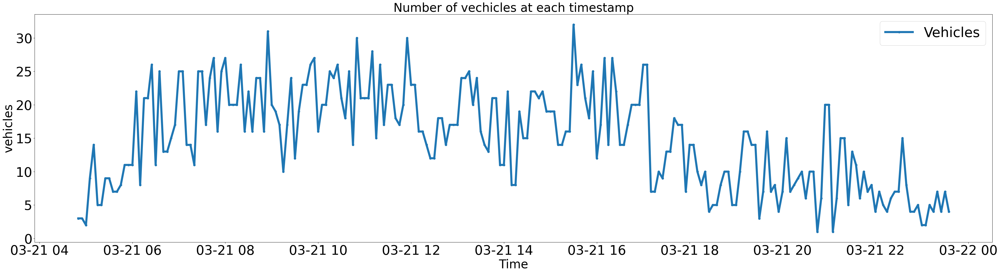

Min, Max speed ::  9.95 24.74


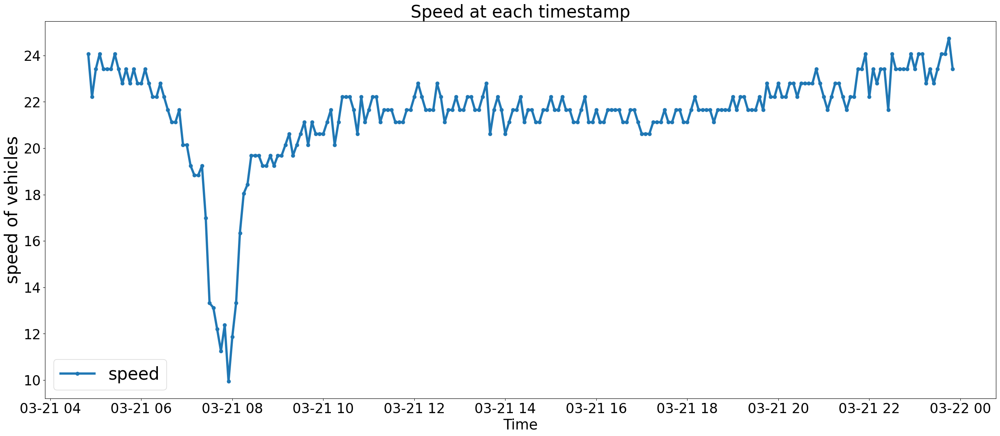

len(combined_df) ::  229
*****************************************************************
b_PIE 2707
[(0, 1000), (1250, 100), (1250, 0), (1500, 100), (2000, 1200), (0, 1200)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicle

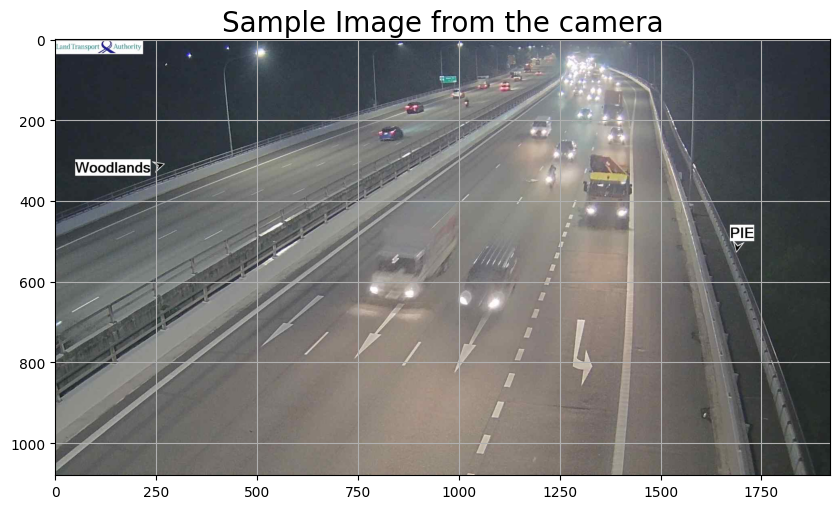

Camera 2707 at 2022-03-15 06:55:00


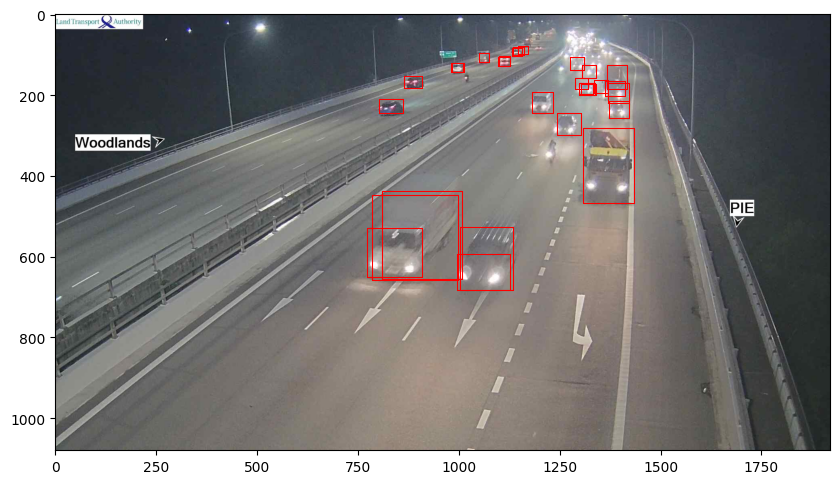

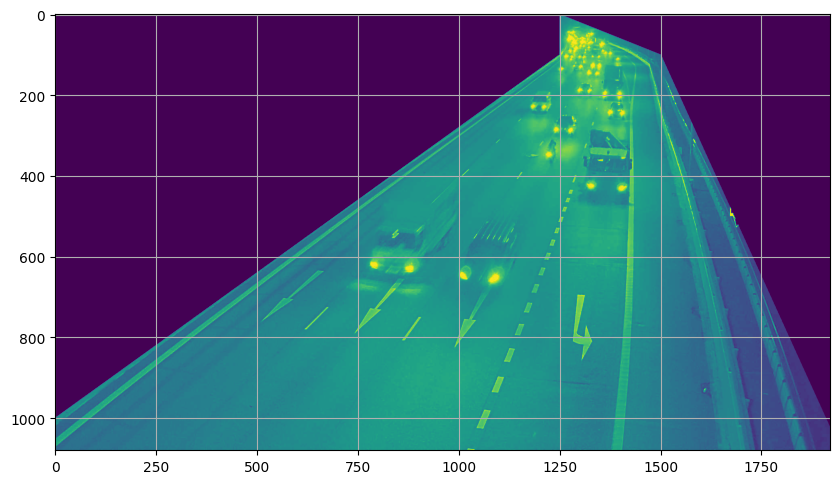

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 04:50:00         2 2022-03-15 04:50:00
2022-03-15 04:55:00         3 2022-03-15 04:55:00
2022-03-15 05:00:00        13 2022-03-15 05:00:00
2022-03-15 05:05:00         6 2022-03-15 05:05:00
2022-03-15 05:10:00        12 2022-03-15 05:10:00
...                       ...                 ...
2022-03-15 23:20:00         3 2022-03-15 23:20:00
2022-03-15 23:25:00         3 2022-03-15 23:25:00
2022-03-15 23:30:00         5 2022-03-15 23:30:00
2022-03-15 23:35:00         5 2022-03-15 23:35:00
2022-03-15 23:40:00         3 2022-03-15 23:40:00

[226 rows x 2 columns]>


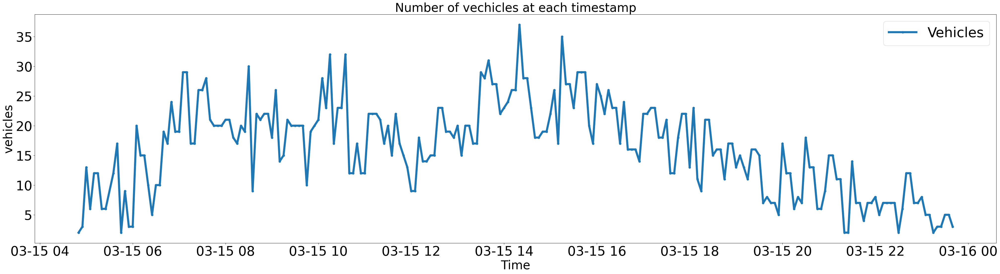

Min, Max speed ::  3.9 24.88


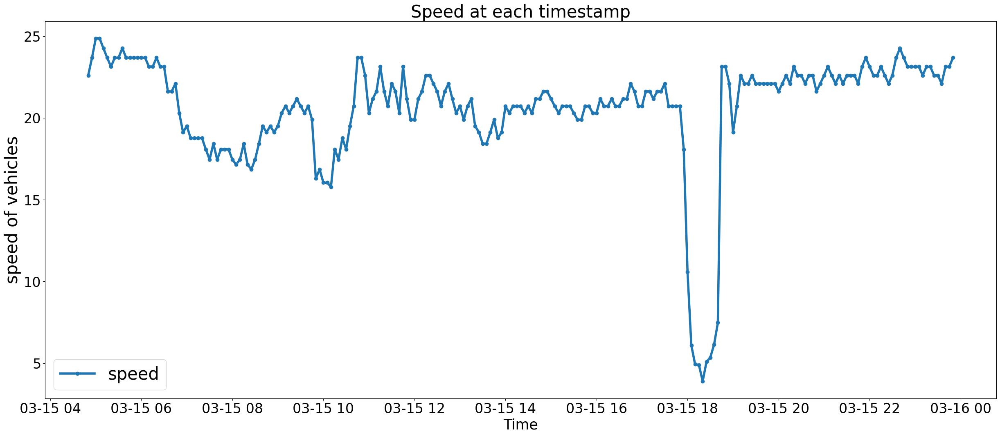

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707\b_PIE_2707_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2707_2022-03-16_Fullday.csv
Total of objects in the dataset: 7039
Total of objects that are vehicles in camera 2707 : 6842
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 04:50:00         1 2022-03-16 04:50:00
2022-03-16 

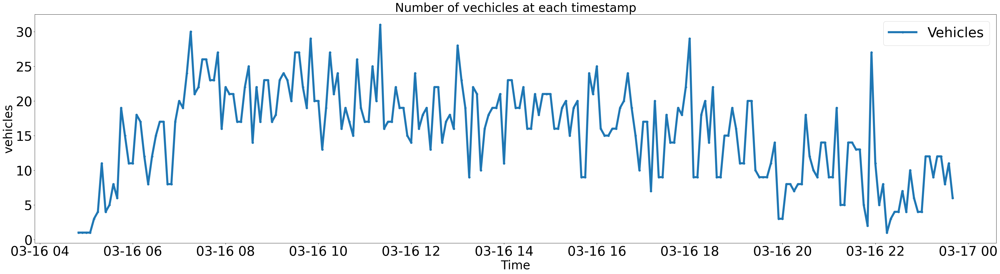

Min, Max speed ::  10.82 24.88


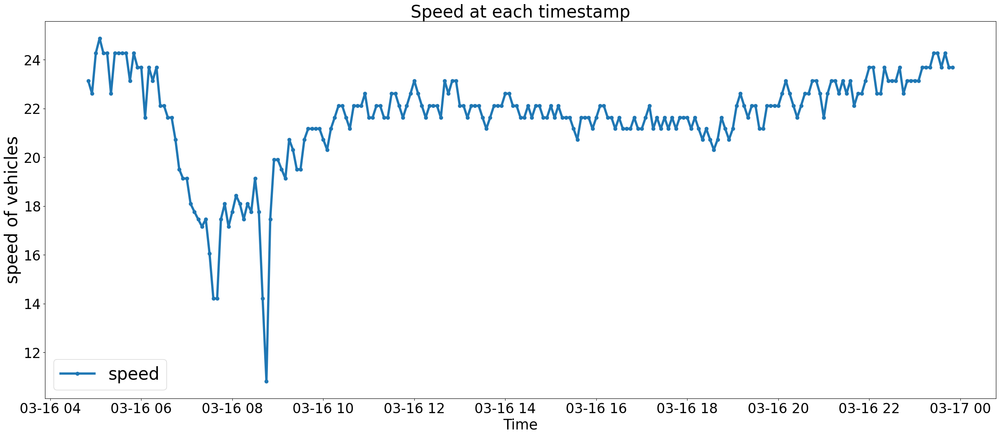

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707\b_PIE_2707_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2707_2022-03-17_Fullday.csv
Total of objects in the dataset: 7052
Total of objects that are vehicles in camera 2707 : 6847


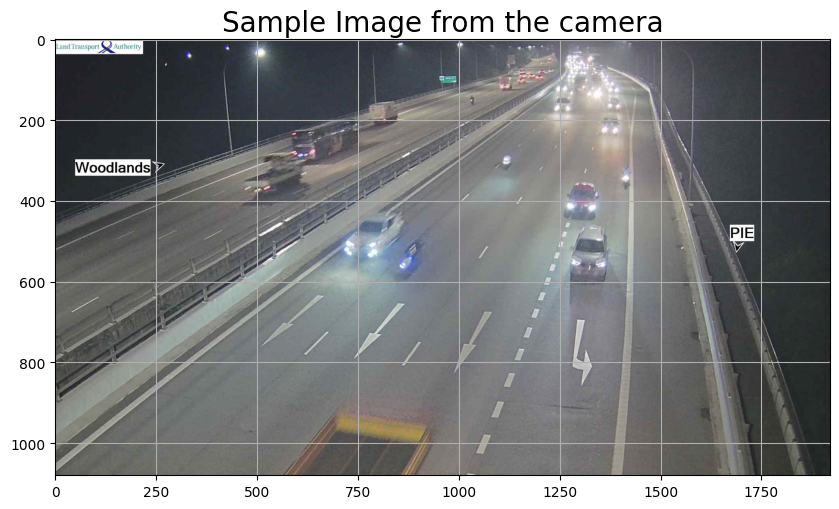

Camera 2707 at 2022-03-17 06:50:00


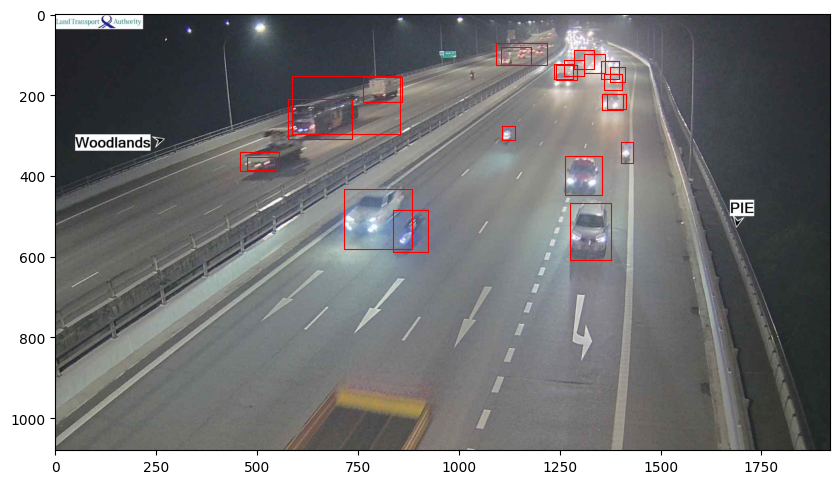

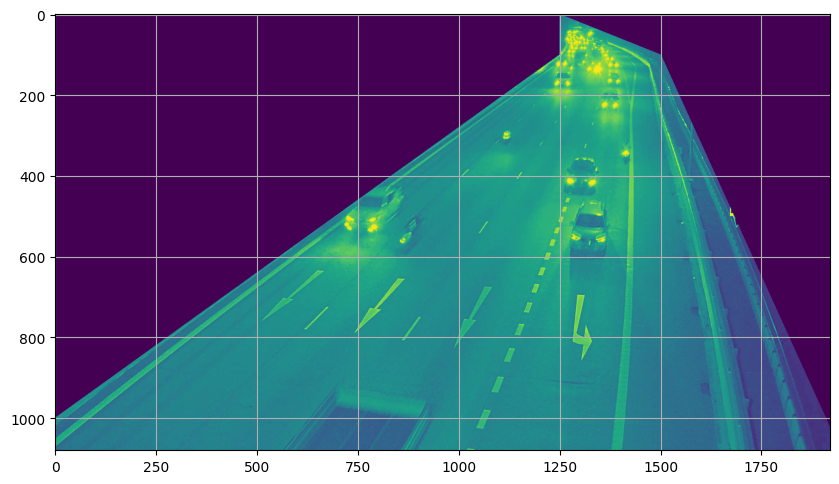

total_area =  3633691
maskedList ::  [True, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 04:50:00        11 2022-03-17 04:50:00
2022-03-17 04:55:00         3 2022-03-17 04:55:00
2022-03-17 05:00:00         5 2022-03-17 05:00:00
2022-03-17 05:05:00         6 2022-03-17 05:05:00
2022-03-17 05:10:00         5 2022-03-17 05:10:00
...                       ...                 ...
2022-03-17 23:10:00         5 2022-03-17 23:10:00
2022-03-17 23:15:00         1 2022-03-17 23:15:00
2022-03-17 23:20:00         1 2022-03-17 23:20:00
2022-03-17 23:25:00         3 2022-03-17 23:25:00
2022-03-17 23:30:00         3 2022-03-17 23:30:00

[223 rows x 2 columns]>


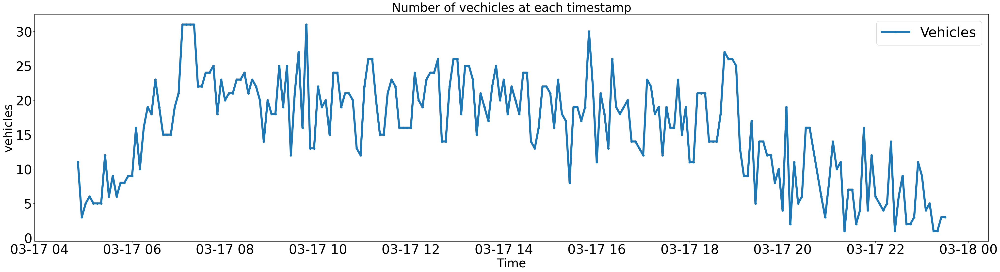

Min, Max speed ::  18.09 24.27


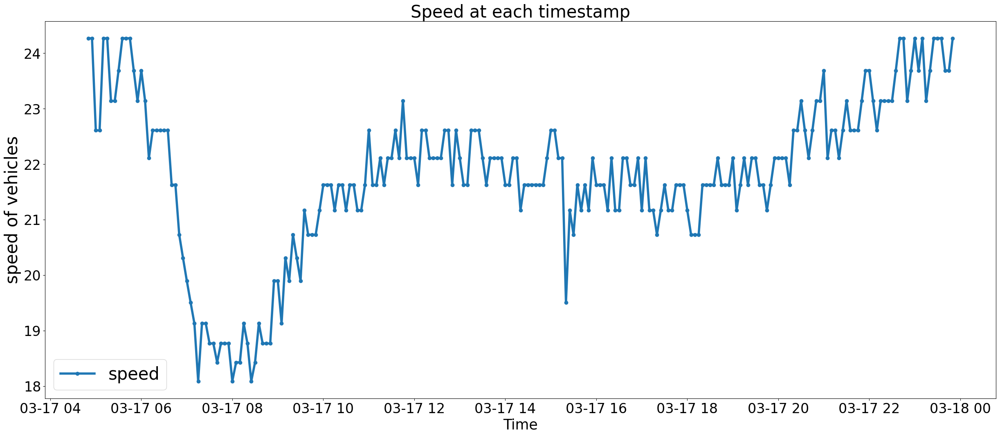

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707\b_PIE_2707_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2707_2022-03-18_Fullday.csv
Total of objects in the dataset: 7285
Total of objects that are vehicles in camera 2707 : 7074
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 04:50:00         2 2022-03-18 04:50:00
2022-03-18 

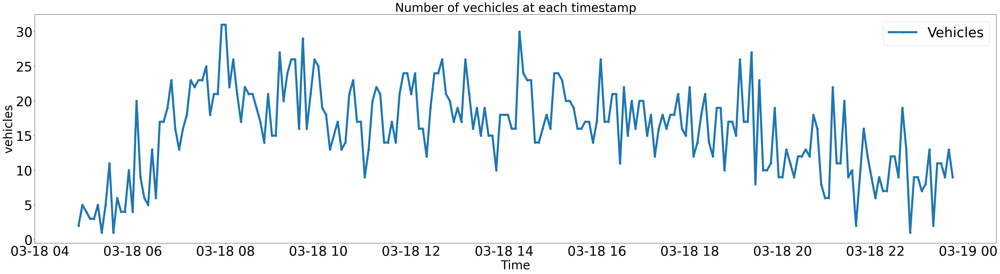

Min, Max speed ::  18.09 24.27


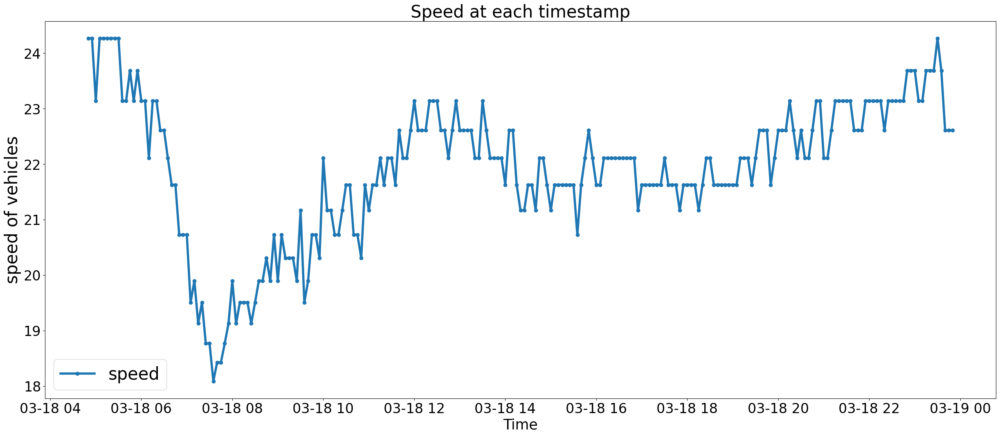

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707\b_PIE_2707_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2707_2022-03-19_Fullday.csv
Total of objects in the dataset: 7188
Total of objects that are vehicles in camera 2707 : 7027
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 04:50:00         6 2022-03-19 04:50:00
2022-03-19 04

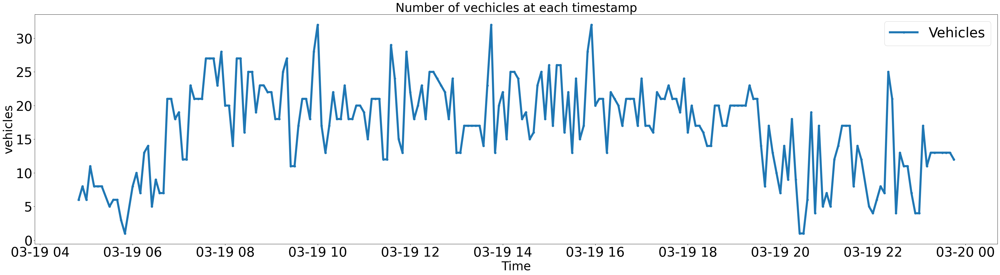

Min, Max speed ::  20.73 24.27


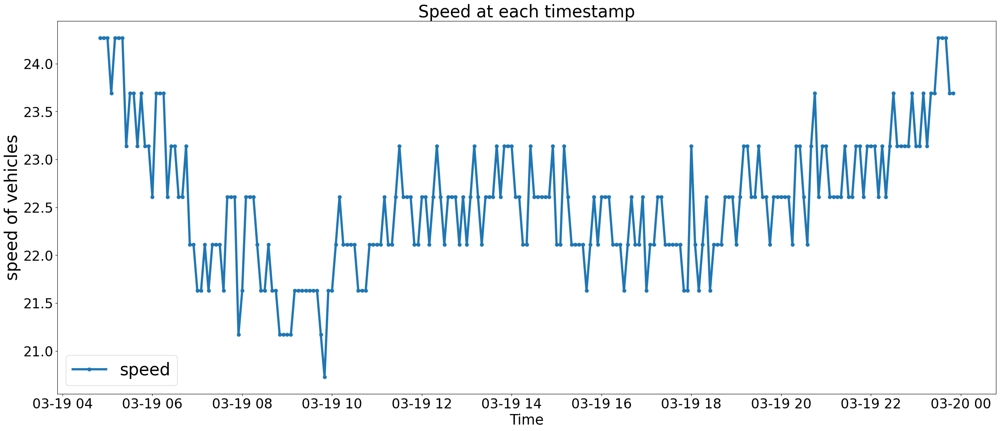

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707\b_PIE_2707_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2707_2022-03-20_Fullday.csv
Total of objects in the dataset: 6824
Total of objects that are vehicles in camera 2707 : 6674
maskedList ::  [False, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:55:00         2 2022-03-20 04:55:00
2022-03-20 0

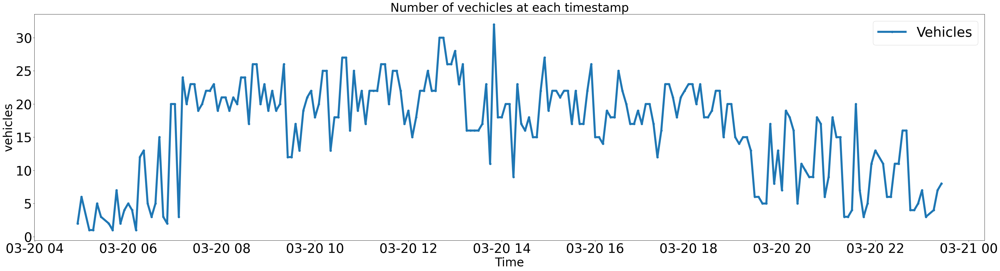

Min, Max speed ::  22.11 24.88


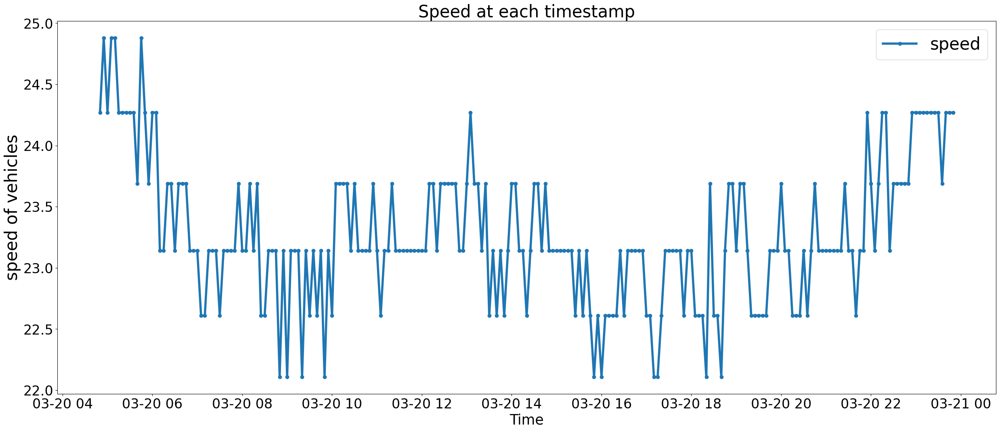

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2707\b_PIE_2707_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_PIE_2707_2022-03-21_Fullday.csv
Total of objects in the dataset: 7223
Total of objects that are vehicles in camera 2707 : 7016
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 05:00:00         1 2022-03-21 05:00:00
2022-03-21 05

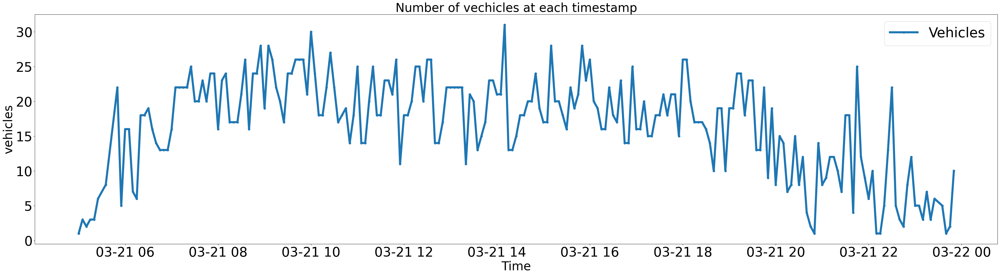

Min, Max speed ::  16.58 24.27


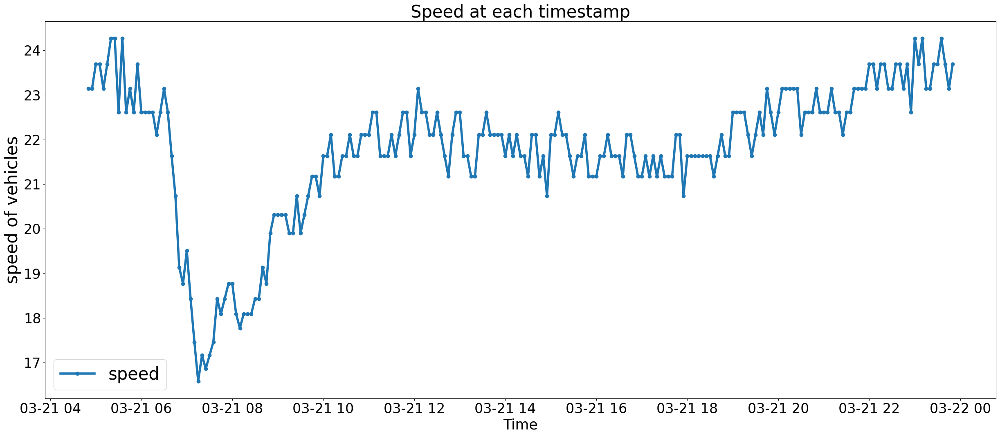

len(combined_df) ::  229
*****************************************************************
b_Woodlands 2703
[(800, 100), (600, 100), (0, 500), (0, 1200), (250, 1200)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehi

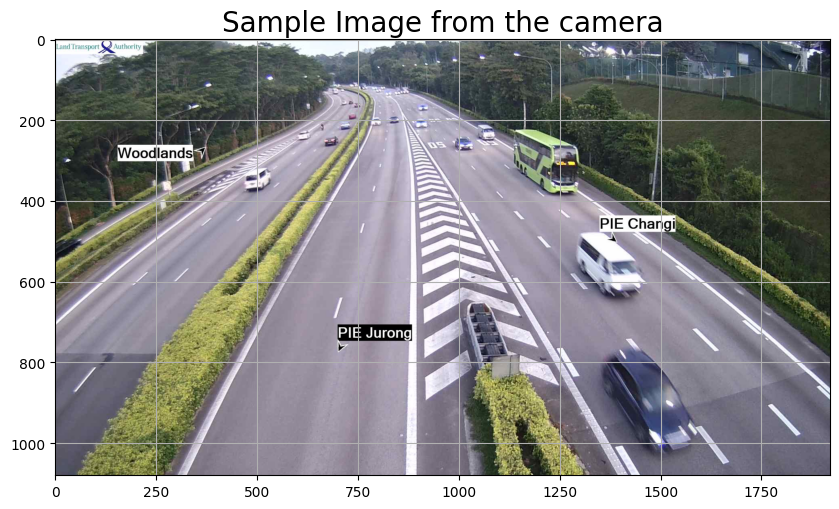

Camera 2703 at 2022-03-15 07:20:00


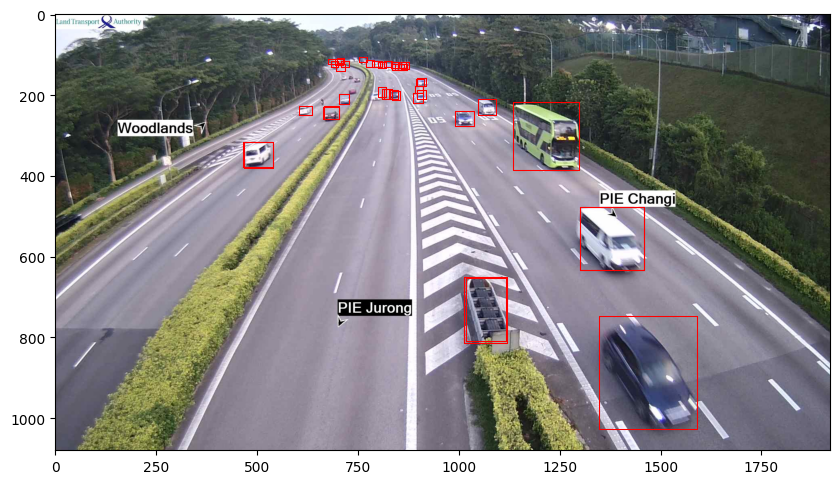

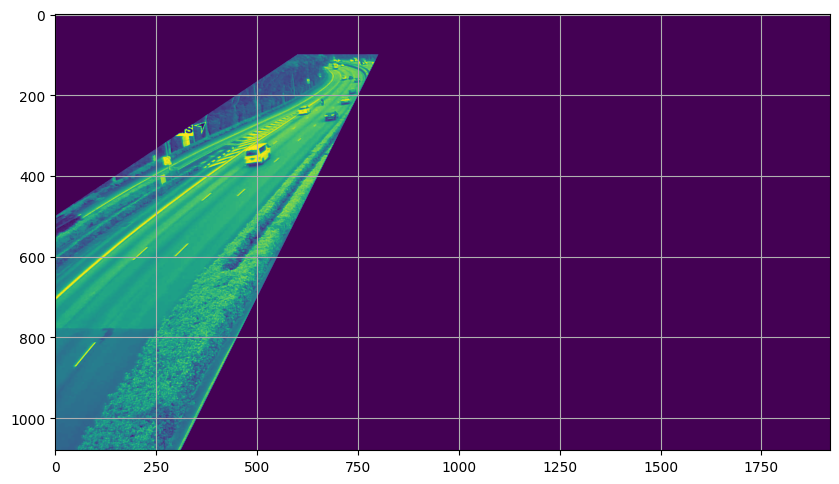

total_area =  3633691
maskedList ::  [False, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 04:50:00         7 2022-03-15 04:50:00
2022-03-15 05:00:00        10 2022-03-15 05:00:00
2022-03-15 05:15:00        11 2022-03-15 05:15:00
2022-03-15 05:20:00         1 2022-03-15 05:20:00
2022-03-15 05:25:00         1 2022-03-15 05:25:00
...                       ...                 ...
2022-03-15 23:15:00        19 2022-03-15 23:15:00
2022-03-15 23:20:00        19 2022-03-15 23:20:00
2022-03-15 23:25:00         3 2022-03-15 23:25:00
2022-03-15 23:30:00         3 2022-03-15 23:30:00
2022-03-15 23:35:00         9 2022-03-15 23:35:00

[220 rows x 2 columns]>


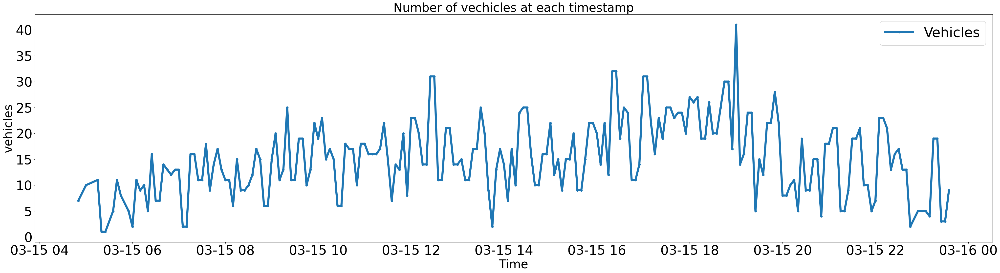

Min, Max speed ::  13.34 23.87


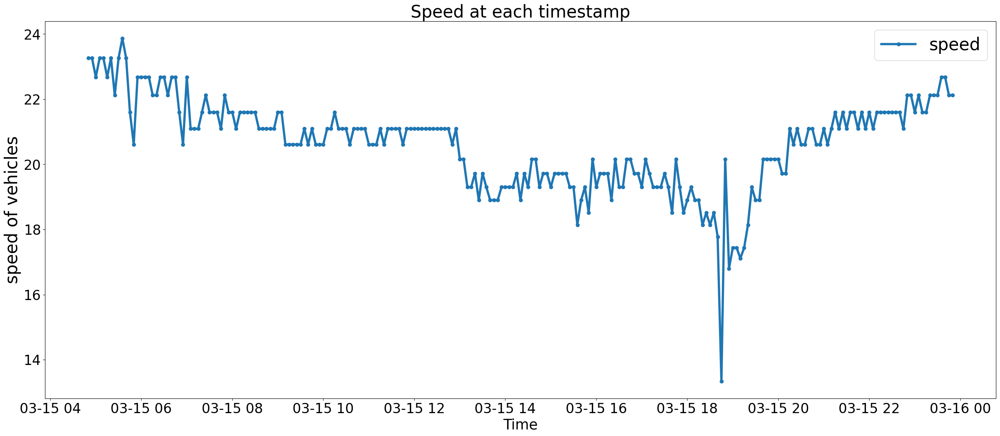

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2703\2703_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2703_2022-03-16_Fullday.csv
Total of objects in the dataset: 7466
Total of objects that are vehicles in camera 2703 : 7332
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 04:50:00         7 2022-03-16 04:5

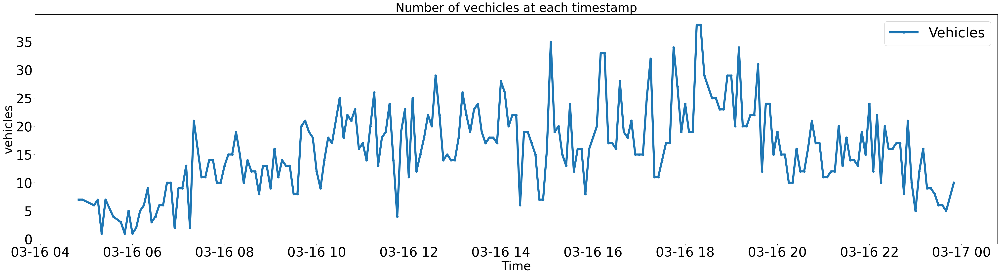

Min, Max speed ::  15.12 23.26


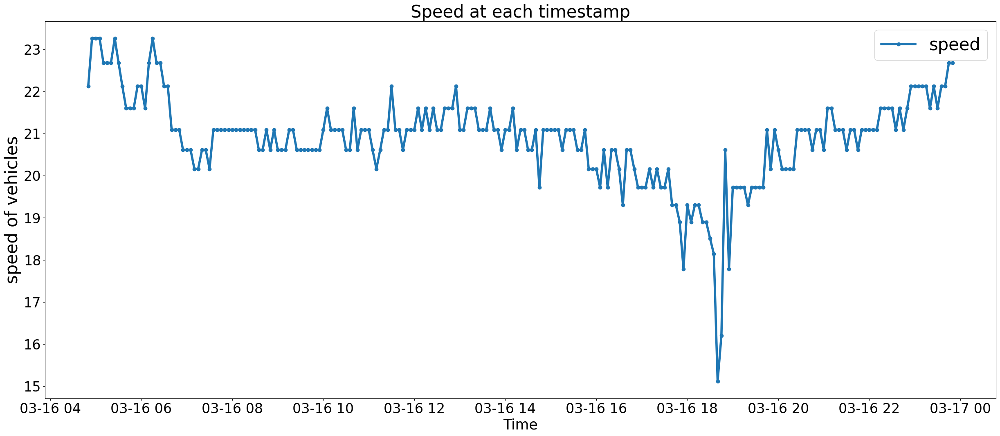

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2703\2703_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2703_2022-03-17_Fullday.csv
Total of objects in the dataset: 6894
Total of objects that are vehicles in camera 2703 : 6764


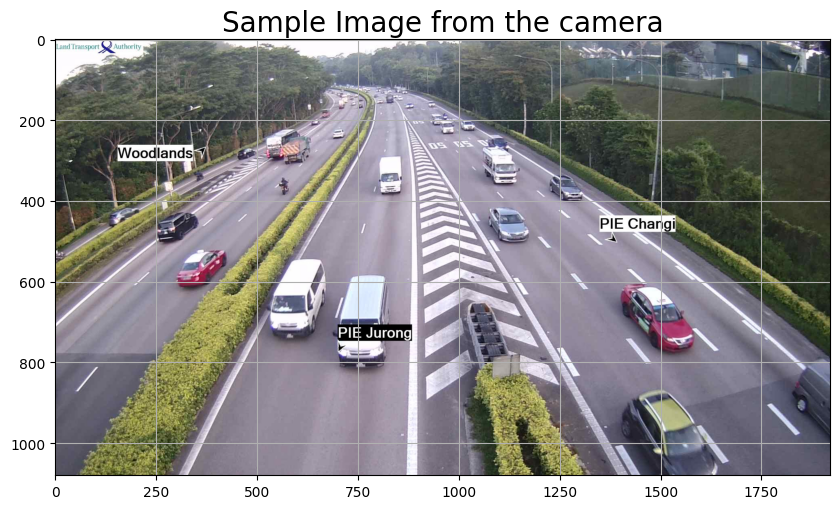

Camera 2703 at 2022-03-17 07:25:00


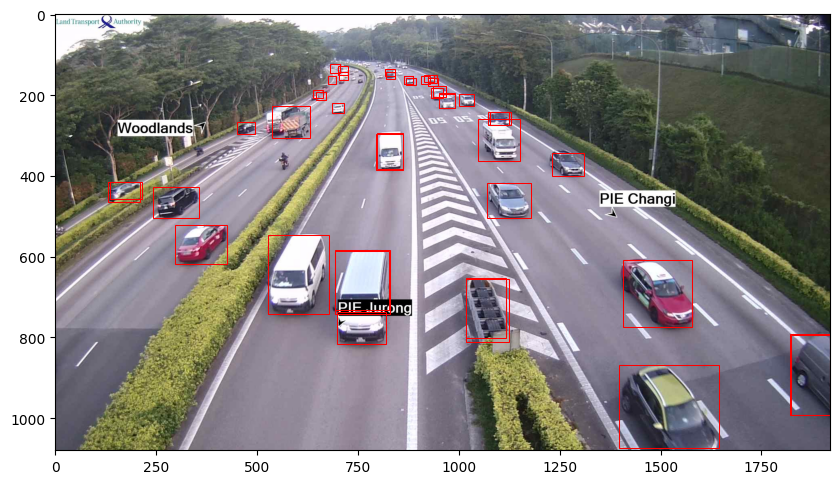

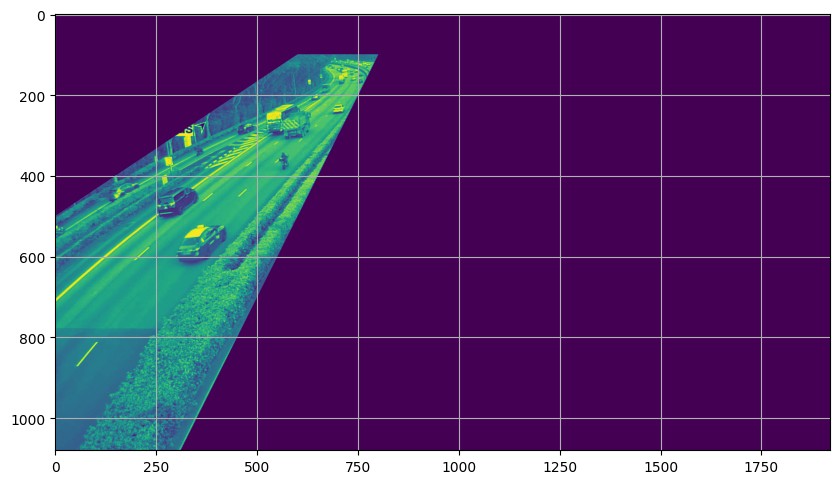

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 04:50:00         2 2022-03-17 04:50:00
2022-03-17 05:00:00         7 2022-03-17 05:00:00
2022-03-17 05:05:00         4 2022-03-17 05:05:00
2022-03-17 05:10:00         2 2022-03-17 05:10:00
2022-03-17 05:35:00         4 2022-03-17 05:35:00
...                       ...                 ...
2022-03-17 23:05:00         9 2022-03-17 23:05:00
2022-03-17 23:10:00        13 2022-03-17 23:10:00
2022-03-17 23:15:00         8 2022-03-17 23:15:00
2022-03-17 23:20:00         8 2022-03-17 23:20:00
2022-03-17 23:25:00        11 2022-03-17 23:25:00

[217 rows x 2 columns]>


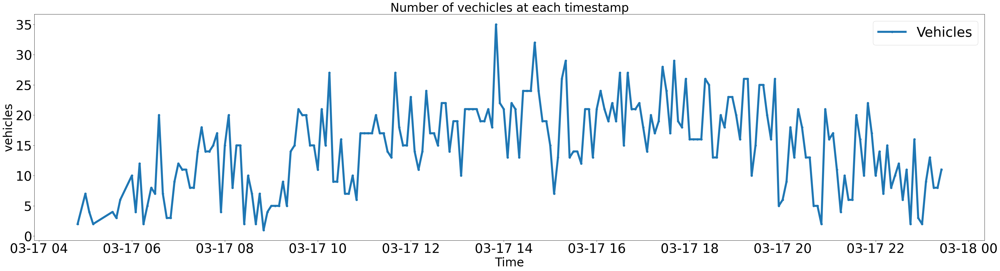

Min, Max speed ::  17.44 23.87


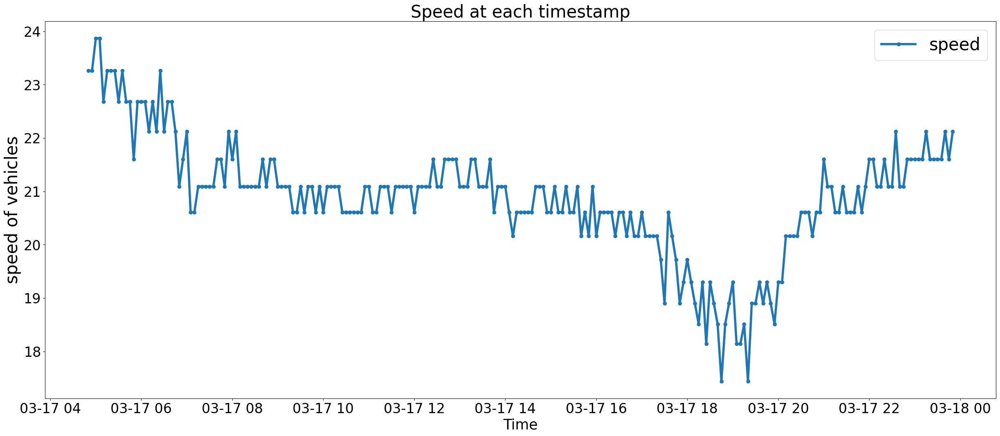

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2703\2703_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2703_2022-03-18_Fullday.csv
Total of objects in the dataset: 7241
Total of objects that are vehicles in camera 2703 : 7133
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 04:50:00         1 2022-03-18 04:5

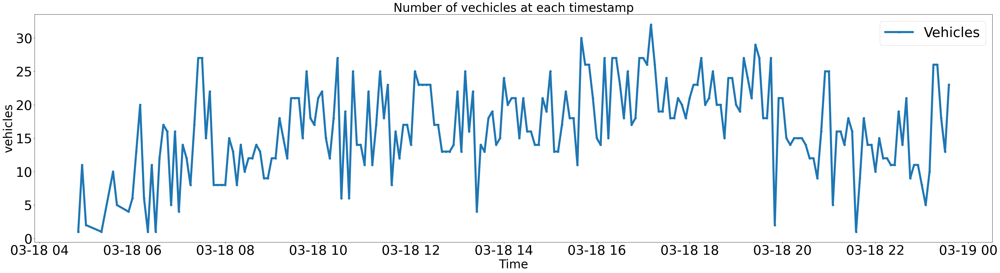

Min, Max speed ::  18.14 23.87


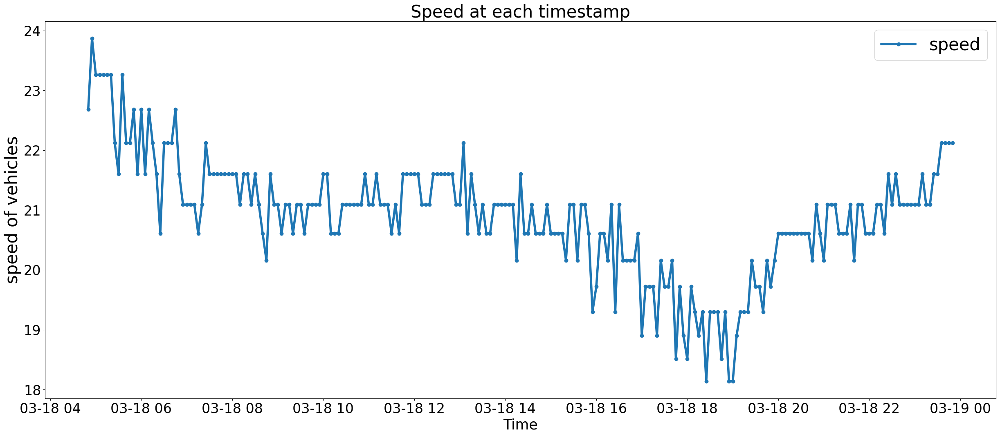

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2703\2703_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2703_2022-03-19_Fullday.csv
Total of objects in the dataset: 7076
Total of objects that are vehicles in camera 2703 : 6950
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 04:50:00         5 2022-03-19 04:5

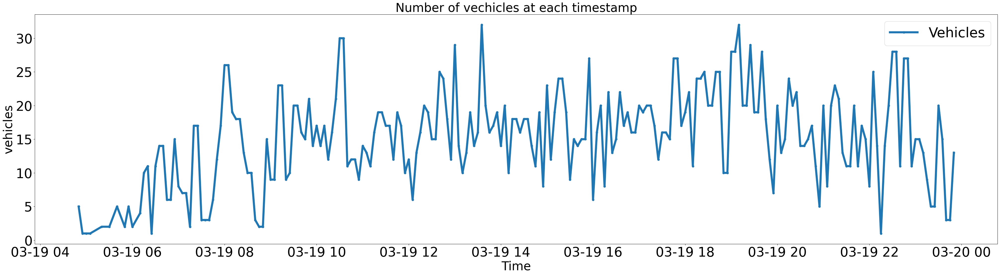

Min, Max speed ::  19.72 23.87


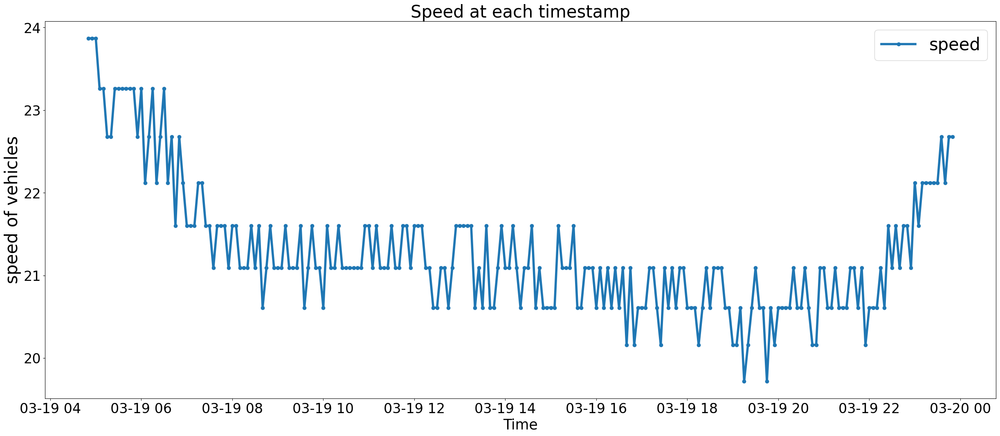

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2703\2703_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2703_2022-03-20_Fullday.csv
Total of objects in the dataset: 6709
Total of objects that are vehicles in camera 2703 : 6648
maskedList ::  [True, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:55:00         1 2022-03-20 04:

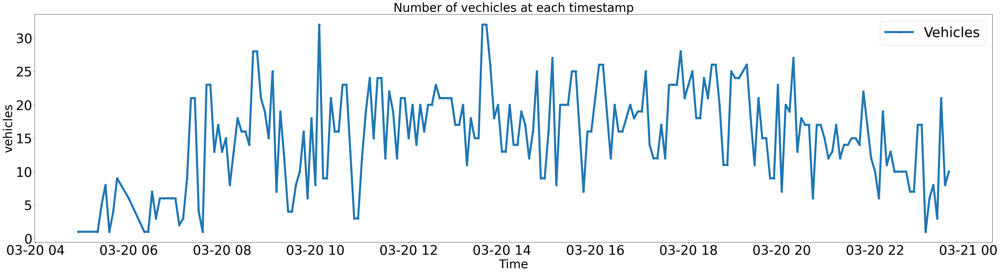

Min, Max speed ::  19.3 23.87


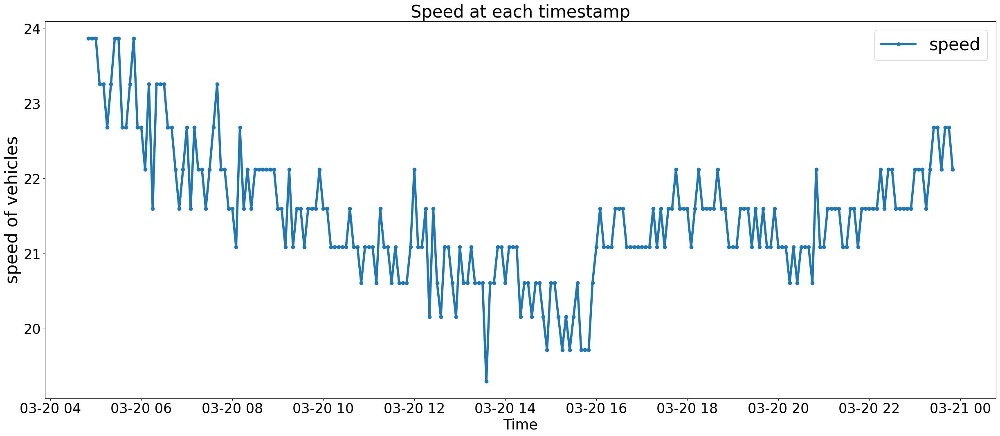

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2703\2703_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2703_2022-03-21_Fullday.csv
Total of objects in the dataset: 7358
Total of objects that are vehicles in camera 2703 : 7247
maskedList ::  [False, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 05:15:00        14 2022-03-21 05:

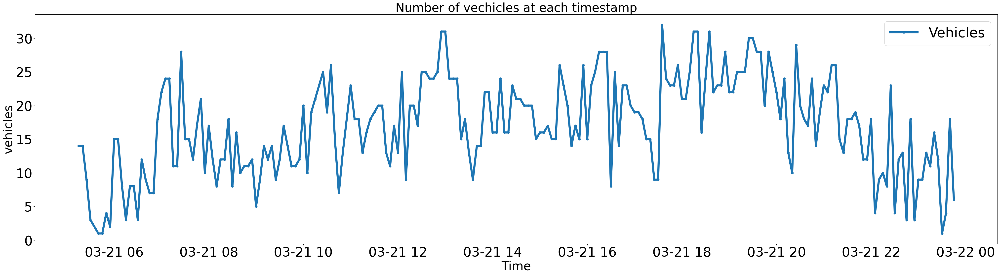

Min, Max speed ::  15.91 23.26


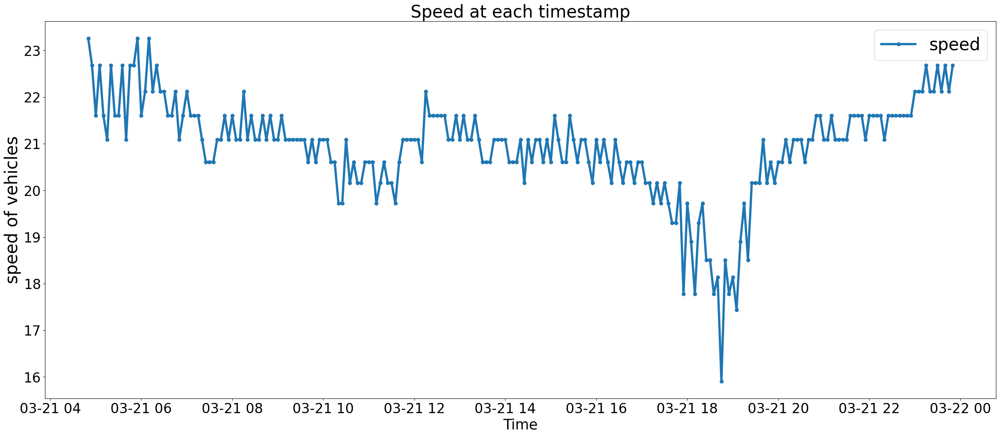

len(combined_df) ::  229
*****************************************************************
b_Woodlands 2706
[(500, 1200), (750, 300), (1750, 1100)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\i

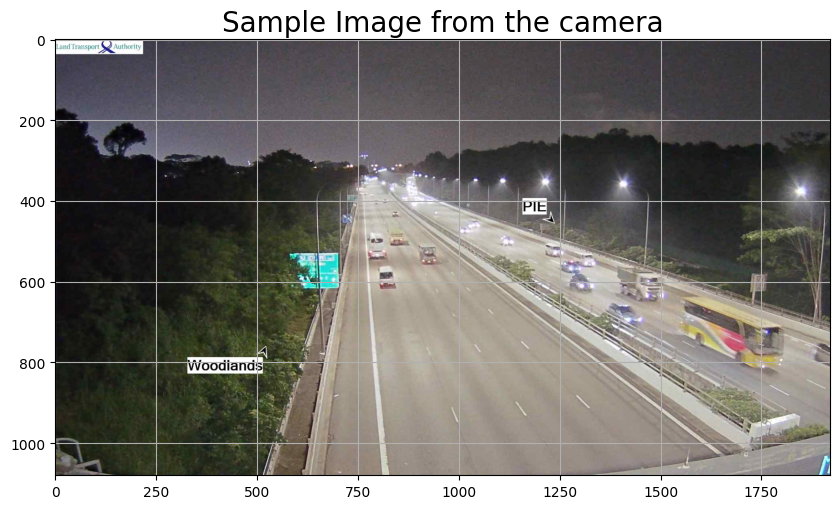

Camera 2706 at 2022-03-15 06:40:00


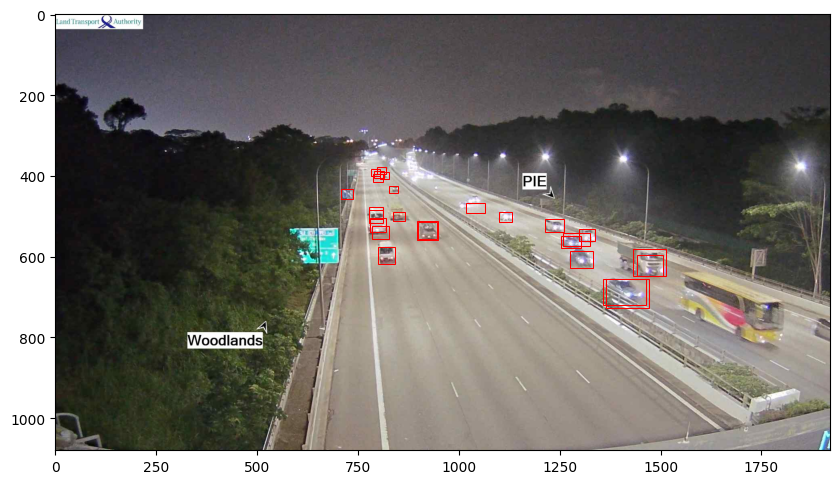

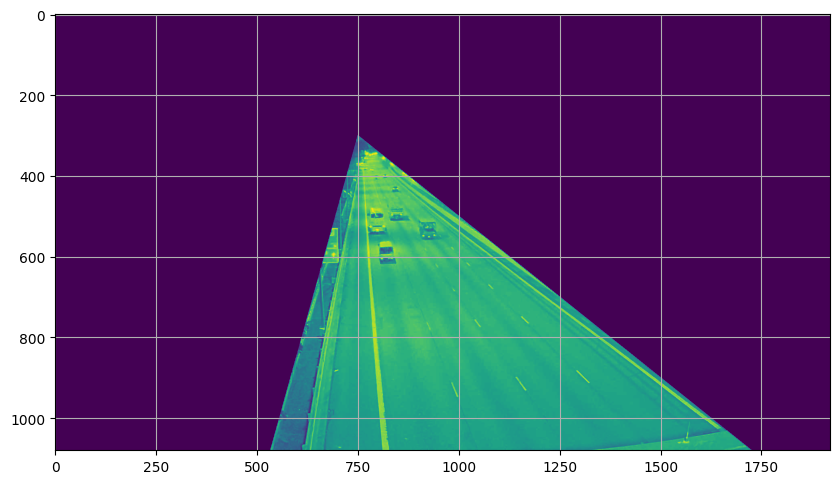

total_area =  3633691
maskedList ::  [True, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 04:50:00         1 2022-03-15 04:50:00
2022-03-15 04:55:00         3 2022-03-15 04:55:00
2022-03-15 05:00:00         4 2022-03-15 05:00:00
2022-03-15 05:05:00         4 2022-03-15 05:05:00
2022-03-15 05:10:00         8 2022-03-15 05:10:00
...                       ...                 ...
2022-03-15 23:20:00        13 2022-03-15 23:20:00
2022-03-15 23:25:00        13 2022-03-15 23:25:00
2022-03-15 23:30:00         7 2022-03-15 23:30:00
2022-03-15 23:35:00         7 2022-03-15 23:35:00
2022-03-15 23:40:00         3 2022-03-15 23:40:00

[223 rows x 2 columns]>


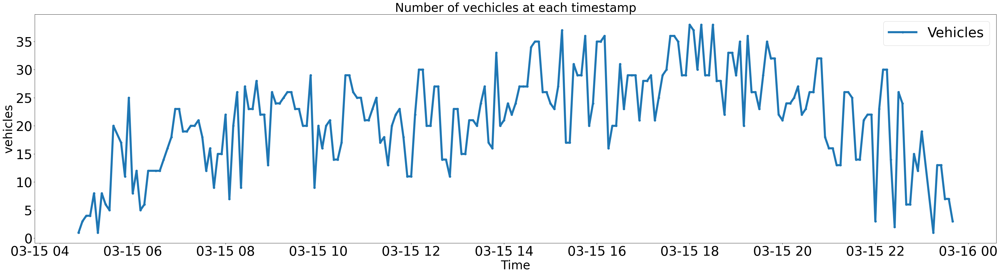

Min, Max speed ::  11.7 24.74


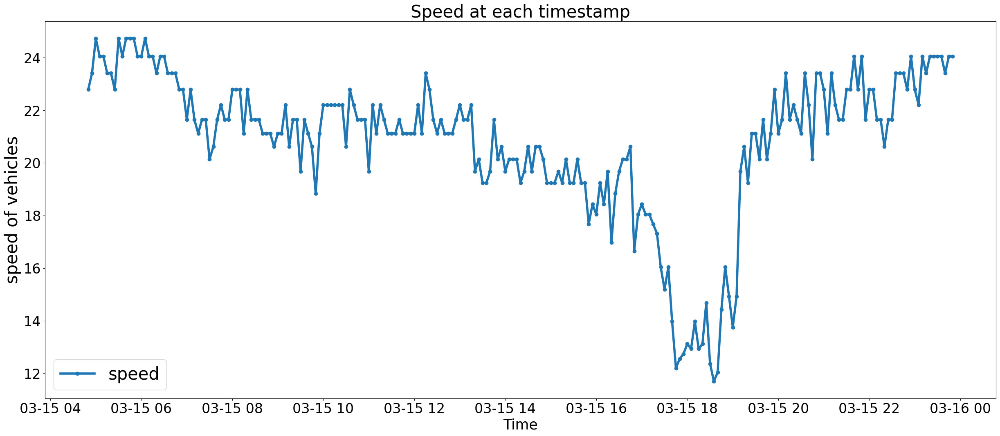

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2706_2022-03-16_Fullday.csv
Total of objects in the dataset: 7897
Total of objects that are vehicles in camera 2706 : 7765
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 05:00:00        12 2022-03-16 05:0

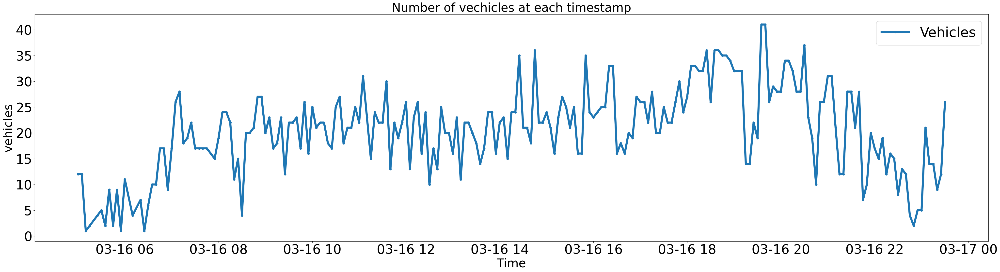

Min, Max speed ::  10.82 24.74


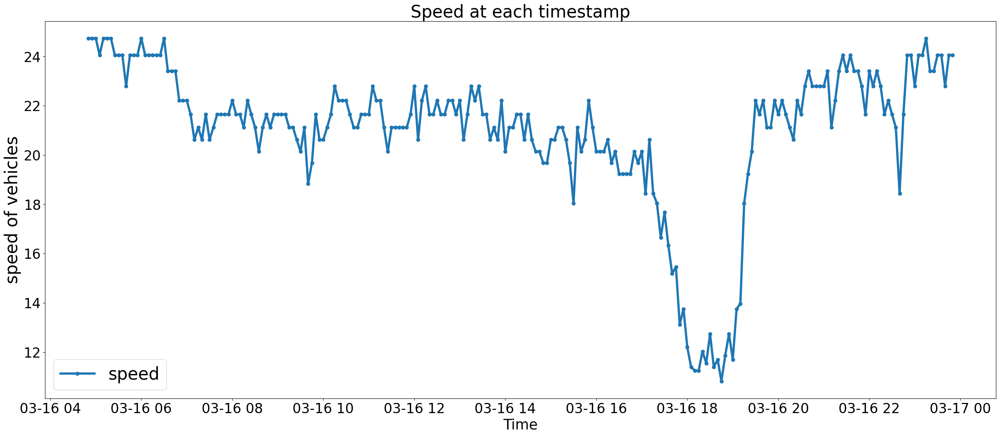

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2706_2022-03-17_Fullday.csv
Total of objects in the dataset: 8197
Total of objects that are vehicles in camera 2706 : 8017


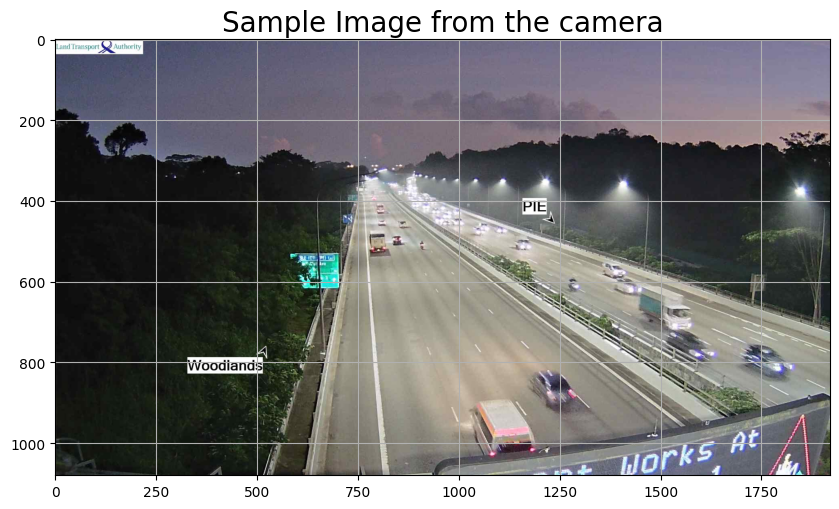

Camera 2706 at 2022-03-17 06:55:00


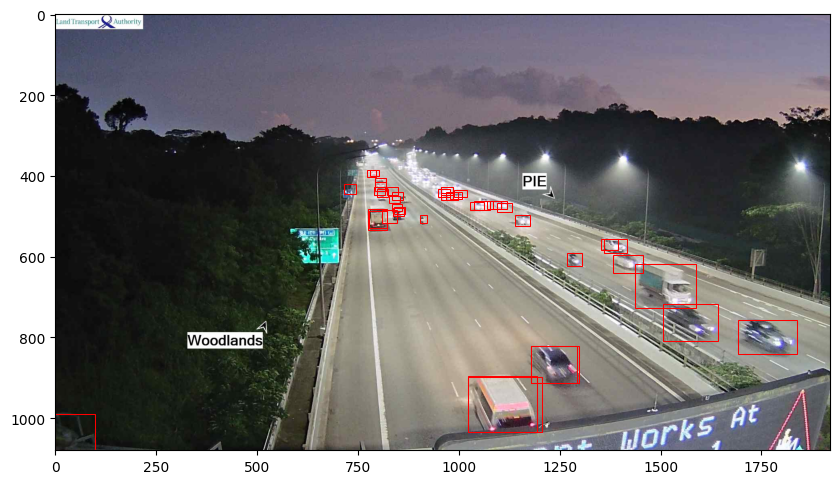

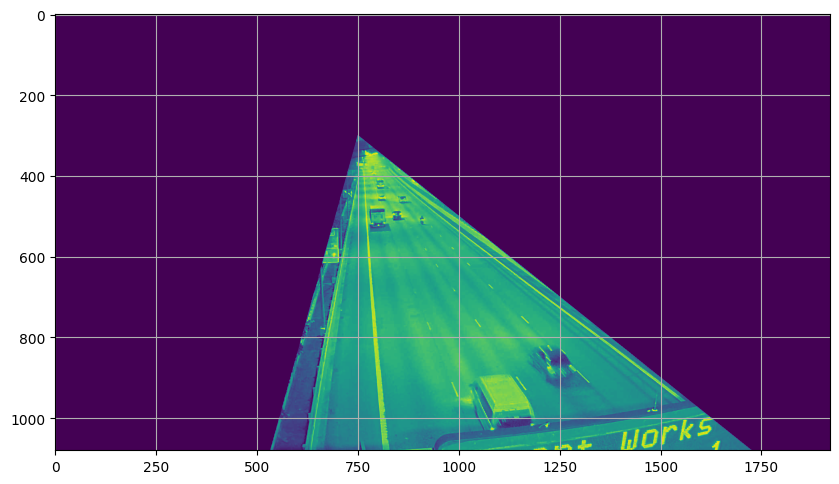

total_area =  3633691
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 05:00:00         7 2022-03-17 05:00:00
2022-03-17 05:05:00         3 2022-03-17 05:05:00
2022-03-17 05:25:00         7 2022-03-17 05:25:00
2022-03-17 05:30:00         3 2022-03-17 05:30:00
2022-03-17 05:35:00         3 2022-03-17 05:35:00
...                       ...                 ...
2022-03-17 23:30:00        10 2022-03-17 23:30:00
2022-03-17 23:35:00         6 2022-03-17 23:35:00
2022-03-17 23:40:00         6 2022-03-17 23:40:00
2022-03-17 23:45:00        33 2022-03-17 23:45:00
2022-03-17 23:50:00         4 2022-03-17 23:50:00

[224 rows x 2 columns]>


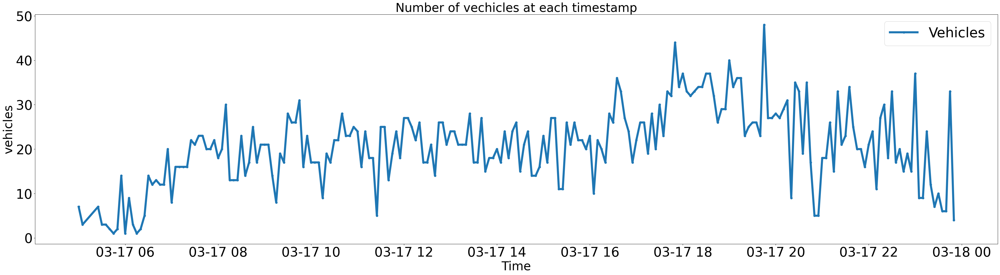

Min, Max speed ::  10.43 25.47


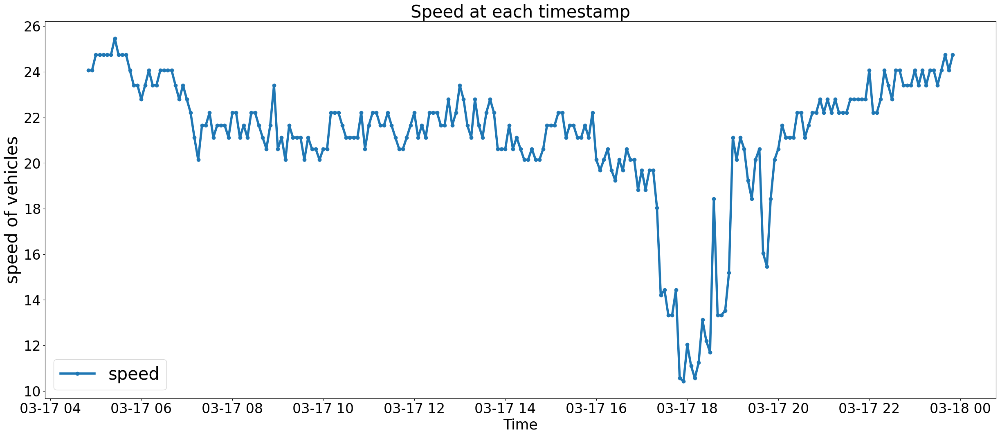

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2706_2022-03-18_Fullday.csv
Total of objects in the dataset: 8628
Total of objects that are vehicles in camera 2706 : 8475
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 04:50:00         1 2022-03-18 04

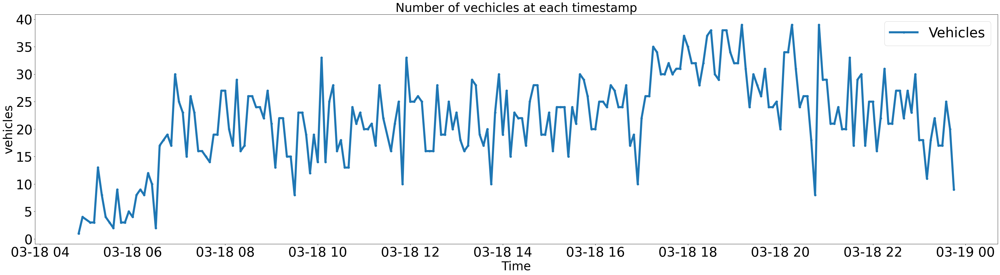

Min, Max speed ::  10.56 24.74


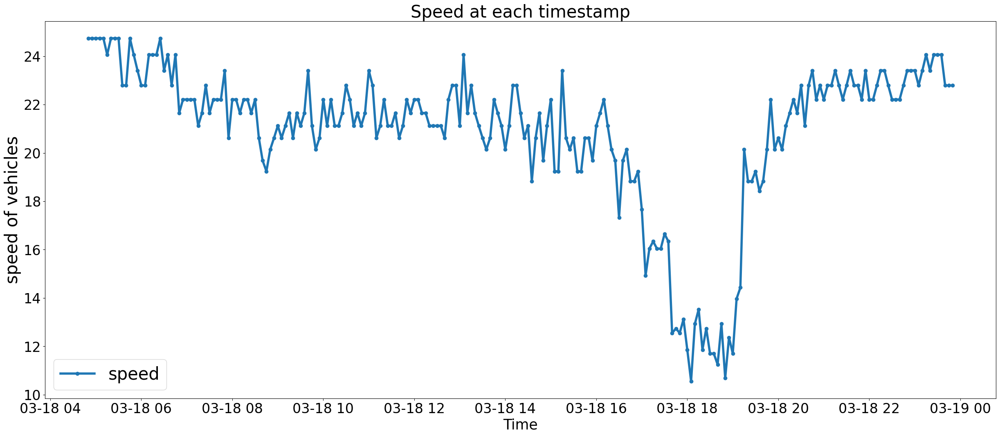

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2706_2022-03-19_Fullday.csv
Total of objects in the dataset: 8027
Total of objects that are vehicles in camera 2706 : 7866
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 04:50:00         1 2022-03-19 04

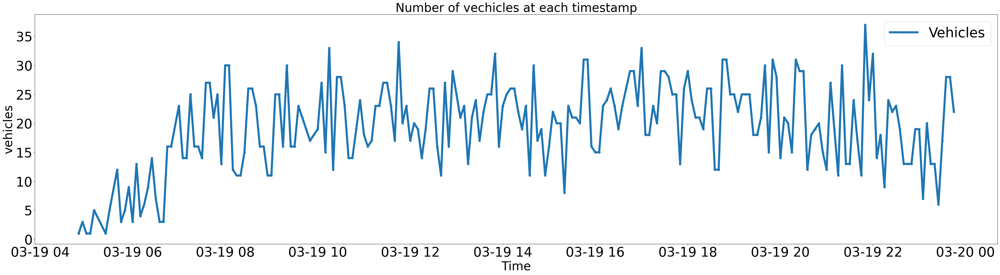

Min, Max speed ::  19.68 24.74


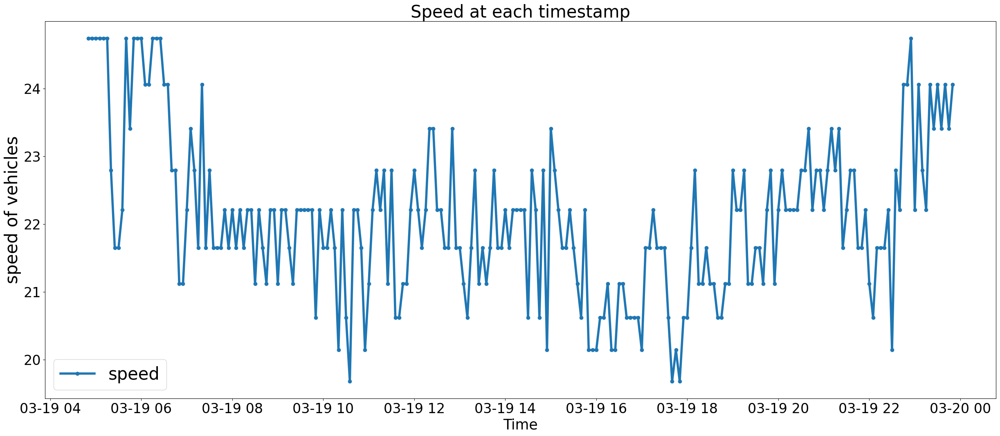

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2706_2022-03-20_Fullday.csv
Total of objects in the dataset: 7049
Total of objects that are vehicles in camera 2706 : 6938
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:50:00        12 2022-03-20 04:5

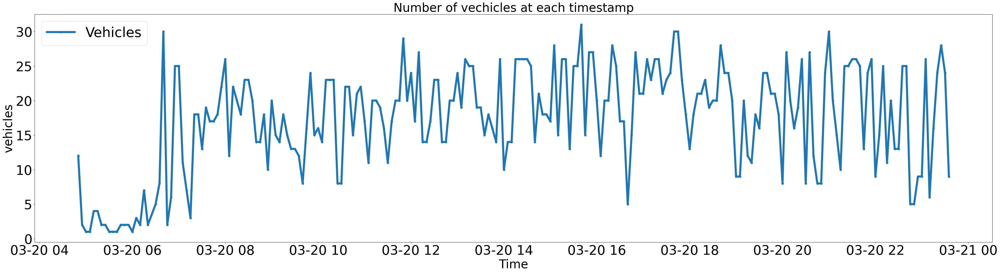

Min, Max speed ::  21.12 25.47


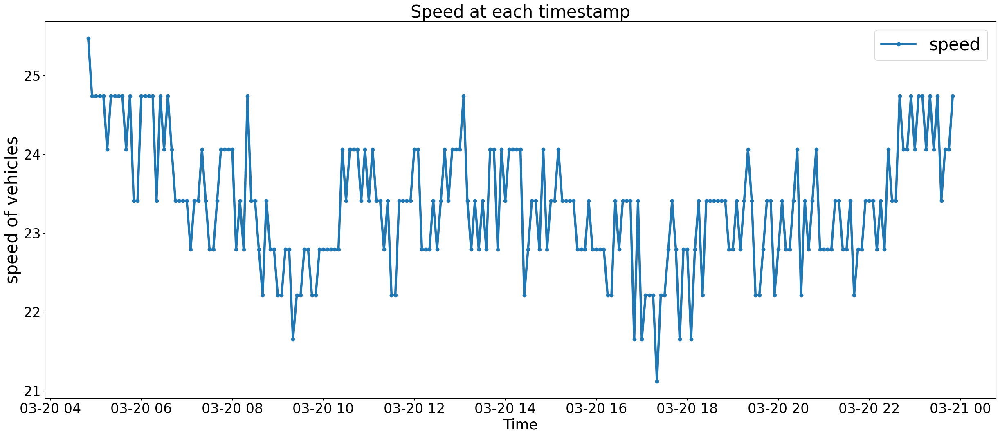

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2706\2706_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2706_2022-03-21_Fullday.csv
Total of objects in the dataset: 8333
Total of objects that are vehicles in camera 2706 : 8152
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 04:50:00         2 2022-03-21 04

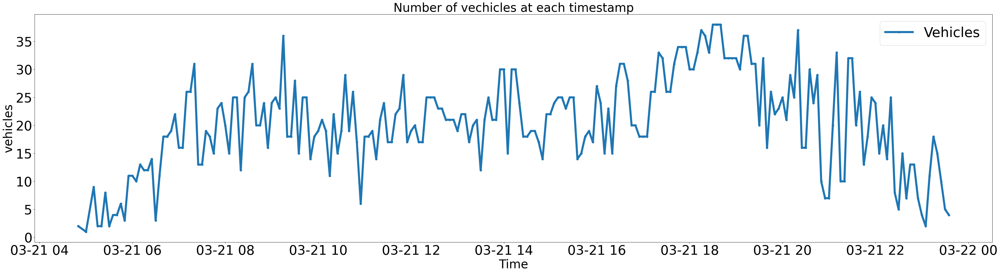

Min, Max speed ::  10.56 24.74


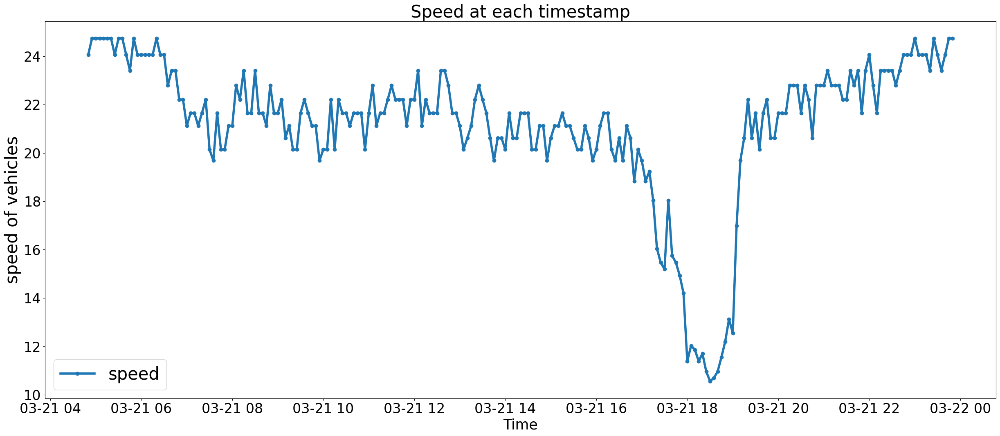

len(combined_df) ::  229
*****************************************************************
b_Woodlands 2707
[(0, 1000), (0, 400), (1125, 0), (1250, 0), (1250, 100)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicl

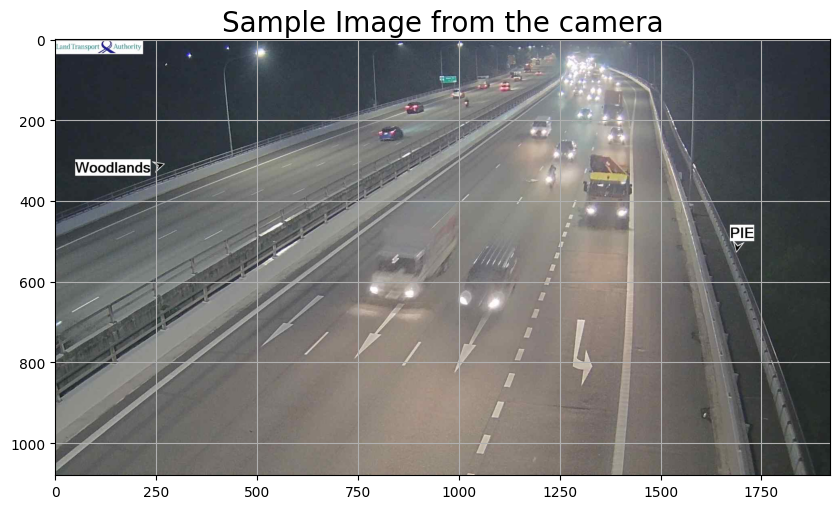

Camera 2707 at 2022-03-15 06:55:00


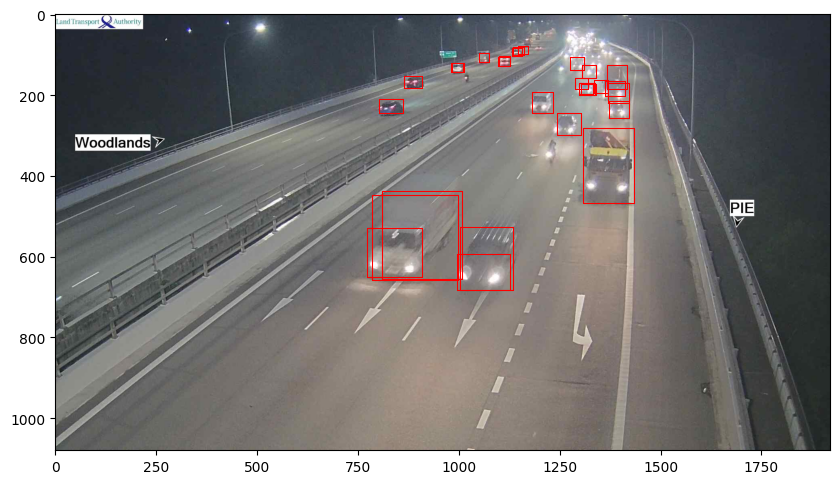

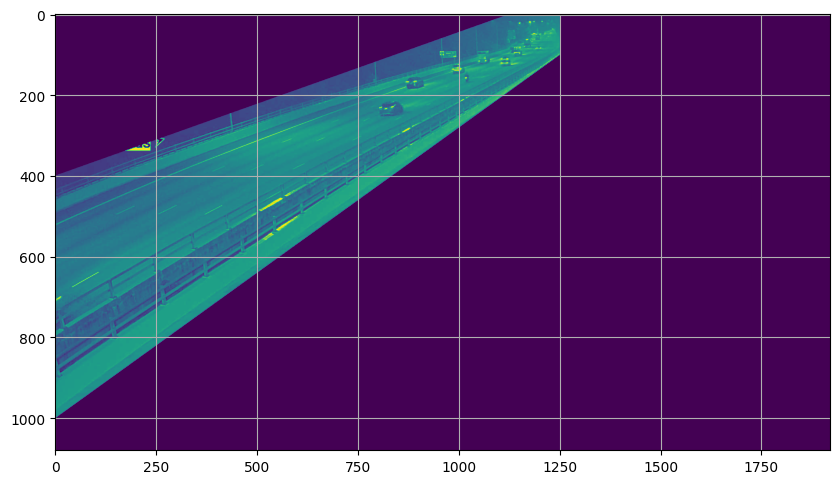

total_area =  3633691
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 04:55:00         1 2022-03-15 04:55:00
2022-03-15 05:00:00         3 2022-03-15 05:00:00
2022-03-15 05:05:00         1 2022-03-15 05:05:00
2022-03-15 05:10:00         2 2022-03-15 05:10:00
2022-03-15 05:15:00         2 2022-03-15 05:15:00
...                       ...                 ...
2022-03-15 23:20:00         9 2022-03-15 23:20:00
2022-03-15 23:25:00         9 2022-03-15 23:25:00
2022-03-15 23:30:00         8 2022-03-15 23:30:00
2022-03-15 23:35:00         8 2022-03-15 23:35:00
2022-03-15 23:40:00         8 2022-03-15 23:40:00

[226 rows x 2 columns]>


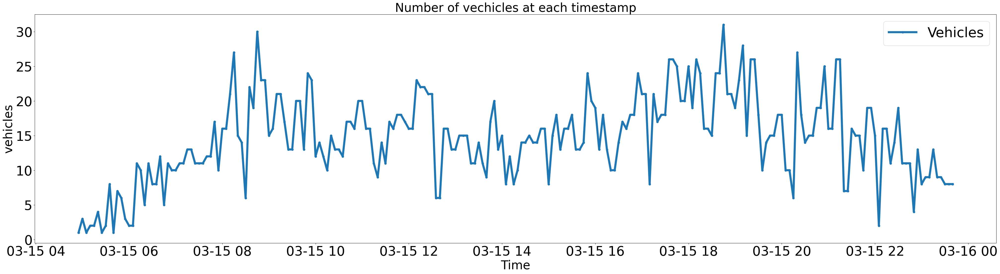

Min, Max speed ::  11.53 23.07


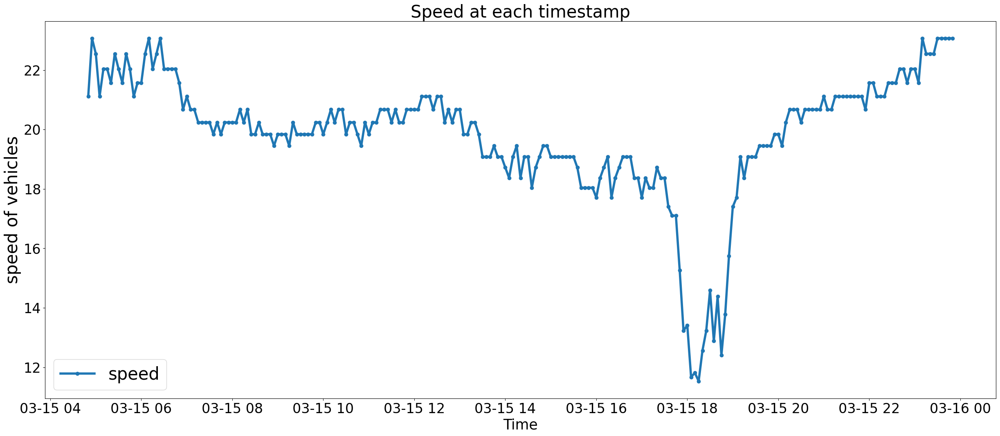

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2707_2022-03-16_Fullday.csv
Total of objects in the dataset: 7039
Total of objects that are vehicles in camera 2707 : 6842
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 04:50:00        16 2022-03-16 04:5

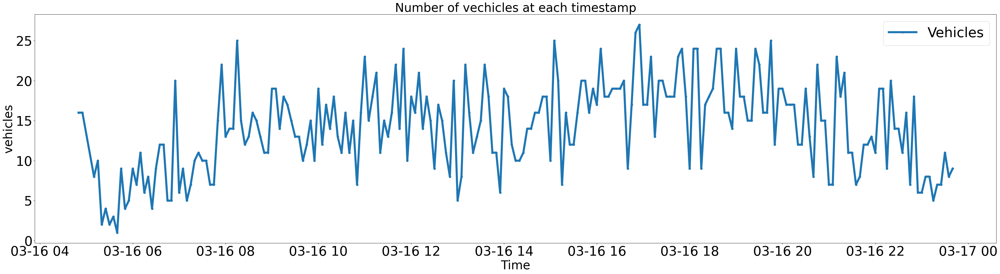

Min, Max speed ::  16.0 23.07


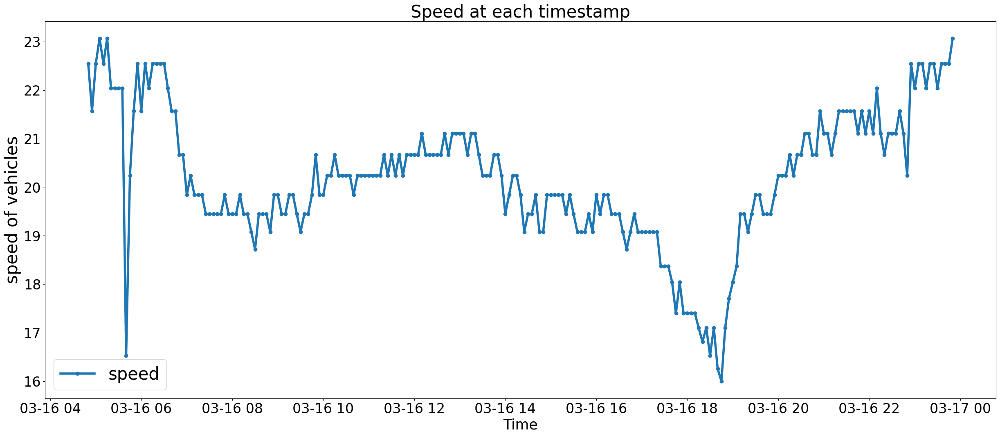

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2707_2022-03-17_Fullday.csv
Total of objects in the dataset: 7052
Total of objects that are vehicles in camera 2707 : 6847


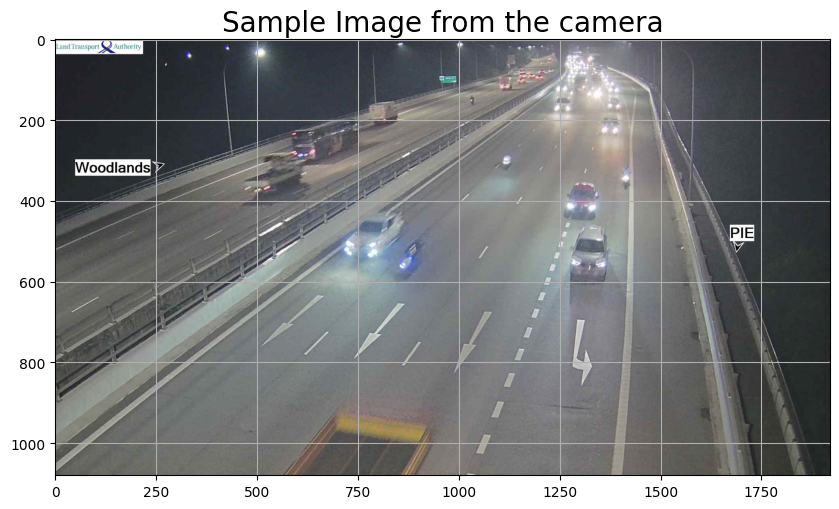

Camera 2707 at 2022-03-17 06:50:00


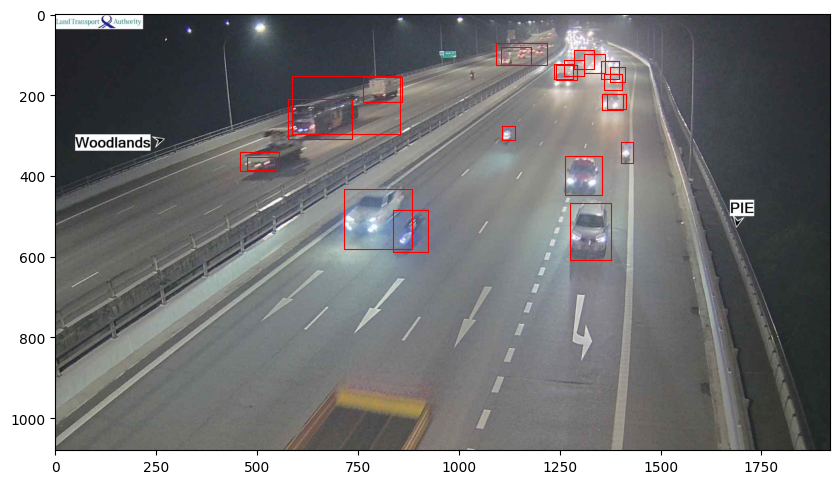

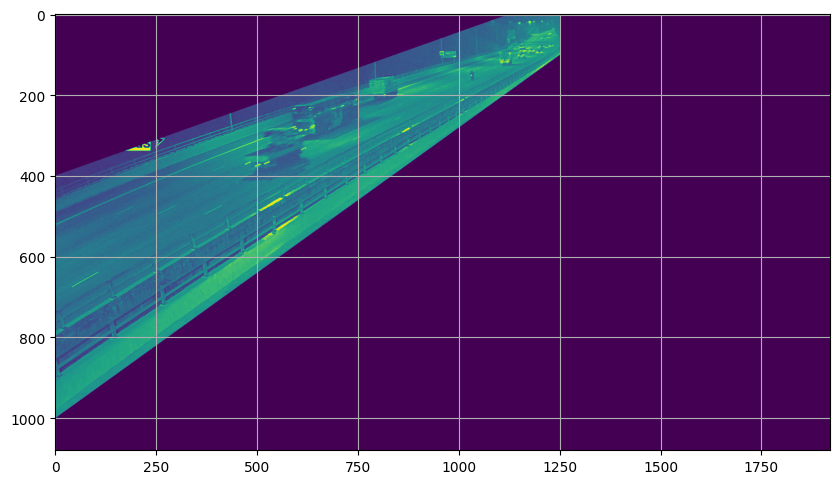

total_area =  3633691
maskedList ::  [False, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 04:50:00         3 2022-03-17 04:50:00
2022-03-17 04:55:00         2 2022-03-17 04:55:00
2022-03-17 05:00:00         2 2022-03-17 05:00:00
2022-03-17 05:05:00         1 2022-03-17 05:05:00
2022-03-17 05:10:00         4 2022-03-17 05:10:00
...                       ...                 ...
2022-03-17 23:10:00         5 2022-03-17 23:10:00
2022-03-17 23:15:00        11 2022-03-17 23:15:00
2022-03-17 23:20:00        11 2022-03-17 23:20:00
2022-03-17 23:25:00         8 2022-03-17 23:25:00
2022-03-17 23:30:00        12 2022-03-17 23:30:00

[225 rows x 2 columns]>


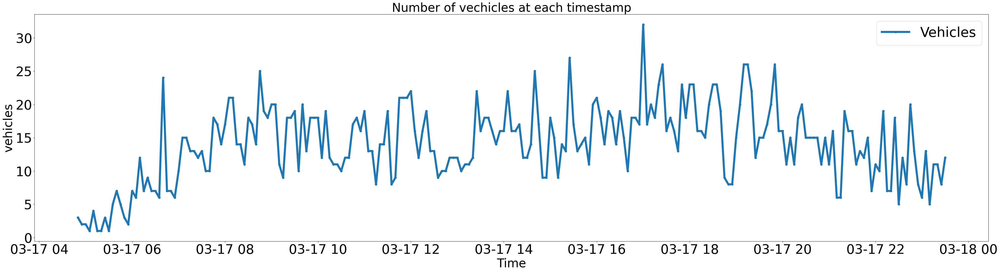

Min, Max speed ::  15.26 23.62


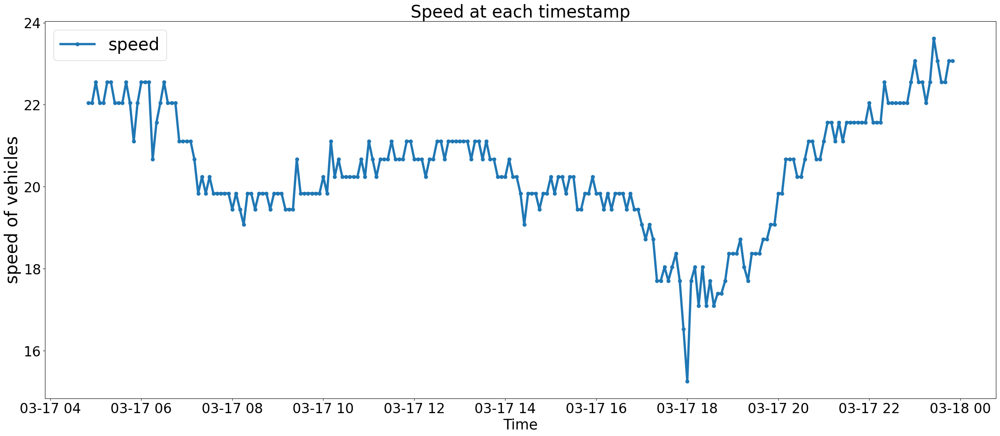

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2707_2022-03-18_Fullday.csv
Total of objects in the dataset: 7285
Total of objects that are vehicles in camera 2707 : 7074
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 04:50:00        10 2022-03-18 04:5

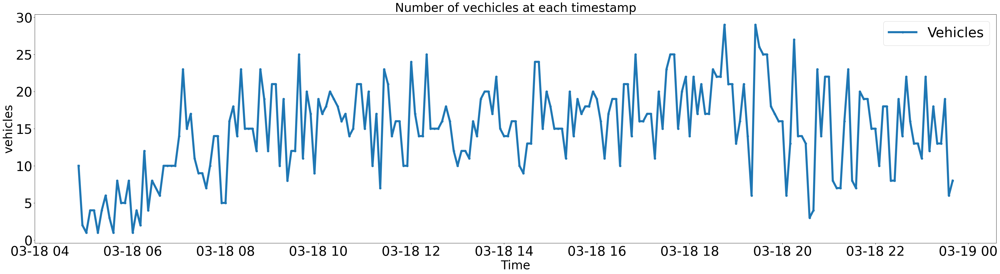

Min, Max speed ::  16.53 23.62


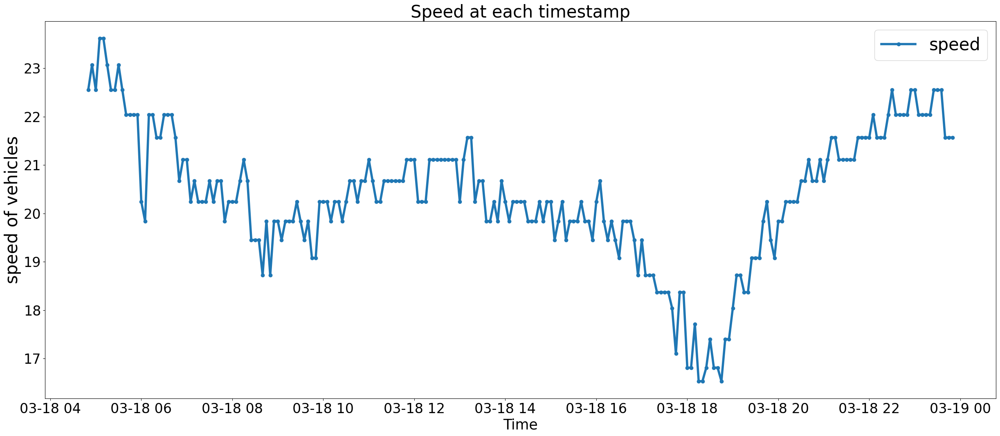

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2707_2022-03-19_Fullday.csv
Total of objects in the dataset: 7188
Total of objects that are vehicles in camera 2707 : 7027
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 04:50:00         2 2022-03-19 04

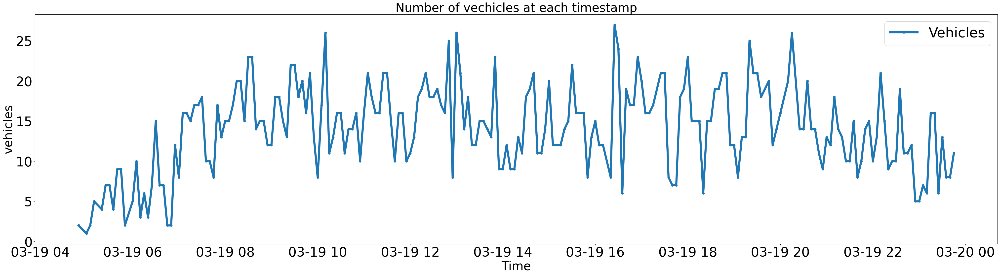

Min, Max speed ::  13.97 23.62


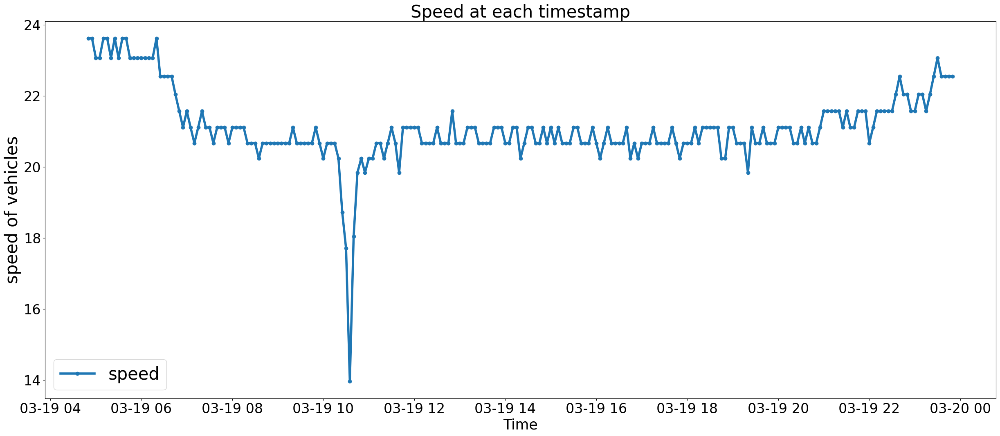

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2707_2022-03-20_Fullday.csv
Total of objects in the dataset: 6824
Total of objects that are vehicles in camera 2707 : 6674
maskedList ::  [True, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:50:00         1 2022-03-20 04:

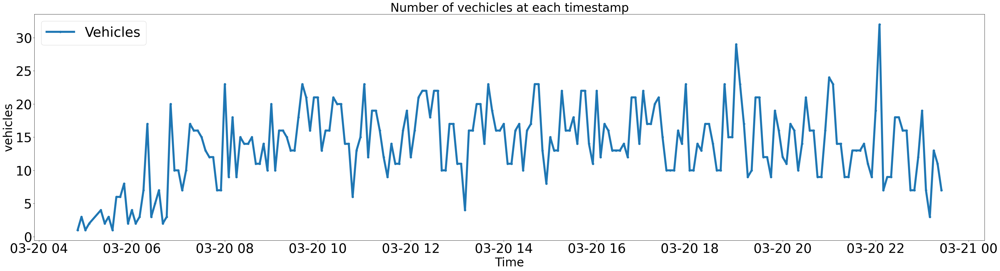

Min, Max speed ::  21.11 24.2


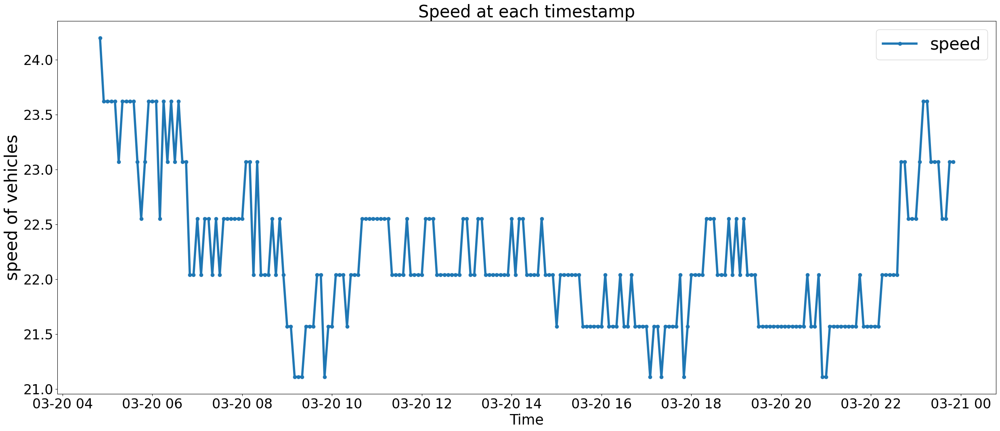

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2707\2707_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2707_2022-03-21_Fullday.csv
Total of objects in the dataset: 7223
Total of objects that are vehicles in camera 2707 : 7016
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 05:05:00         3 2022-03-21 05

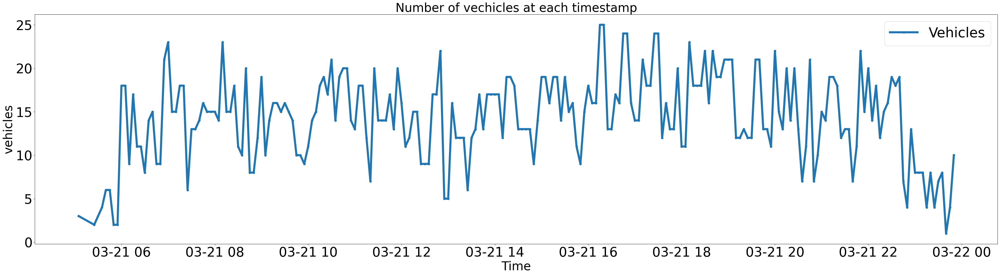

Min, Max speed ::  17.1 23.07


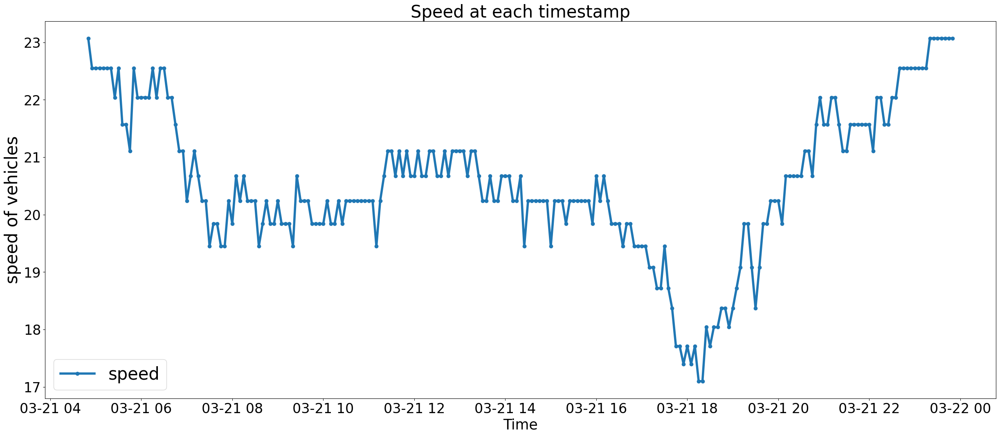

len(combined_df) ::  229
*****************************************************************
b_Woodlands 2708
[(850, 1200), (450, 0), (600, 0), (2000, 1200)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-dir

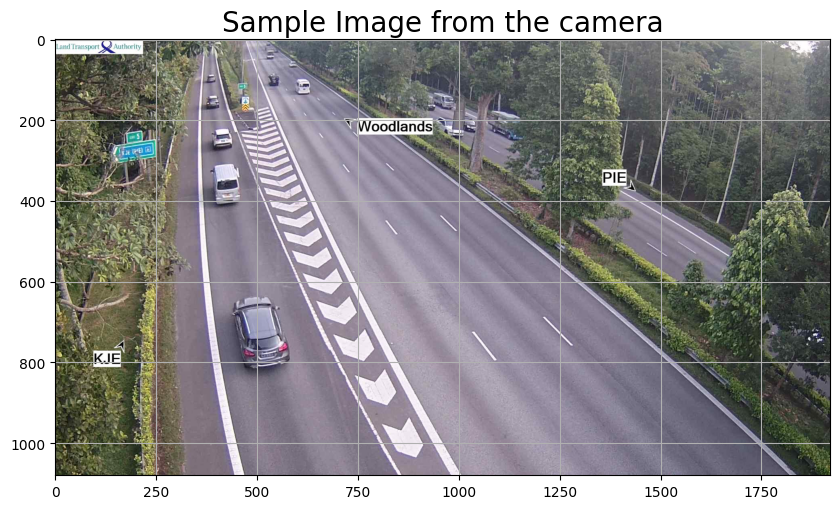

Camera 2708 at 2022-03-15 08:00:00


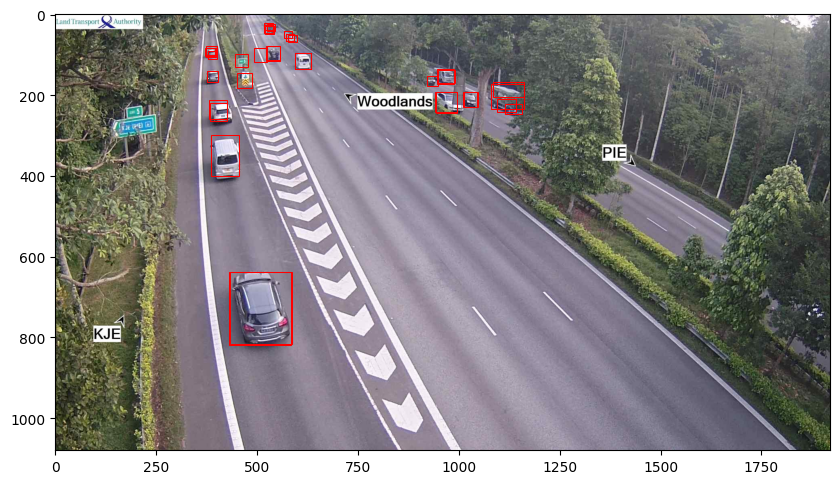

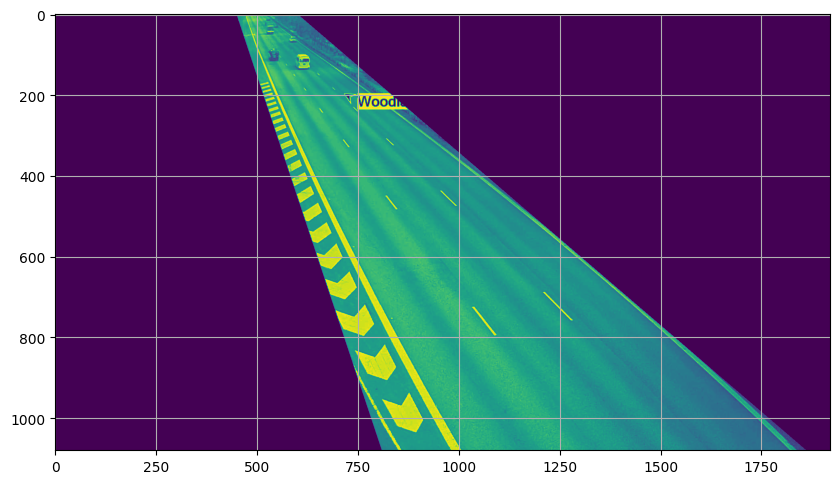

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-15 05:00:00         2 2022-03-15 05:00:00
2022-03-15 05:30:00         2 2022-03-15 05:30:00
2022-03-15 05:35:00         4 2022-03-15 05:35:00
2022-03-15 05:45:00         5 2022-03-15 05:45:00
2022-03-15 05:50:00         2 2022-03-15 05:50:00
...                       ...                 ...
2022-03-15 23:20:00         6 2022-03-15 23:20:00
2022-03-15 23:25:00         6 2022-03-15 23:25:00
2022-03-15 23:30:00        18 2022-03-15 23:30:00
2022-03-15 23:35:00        18 2022-03-15 23:35:00
2022-03-15 23:40:00         9 2022-03-15 23:40:00

[215 rows x 2 columns]>


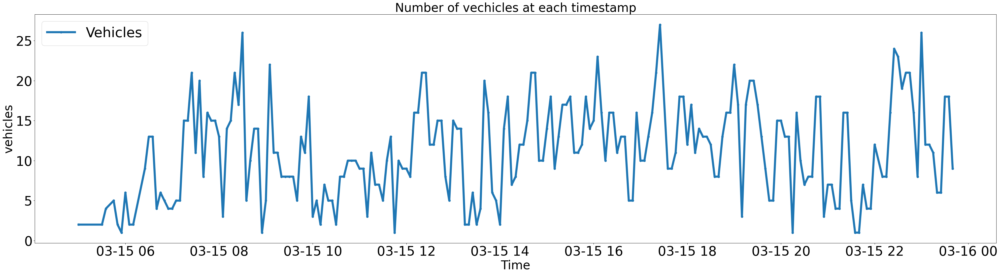

Min, Max speed ::  16.74 23.12


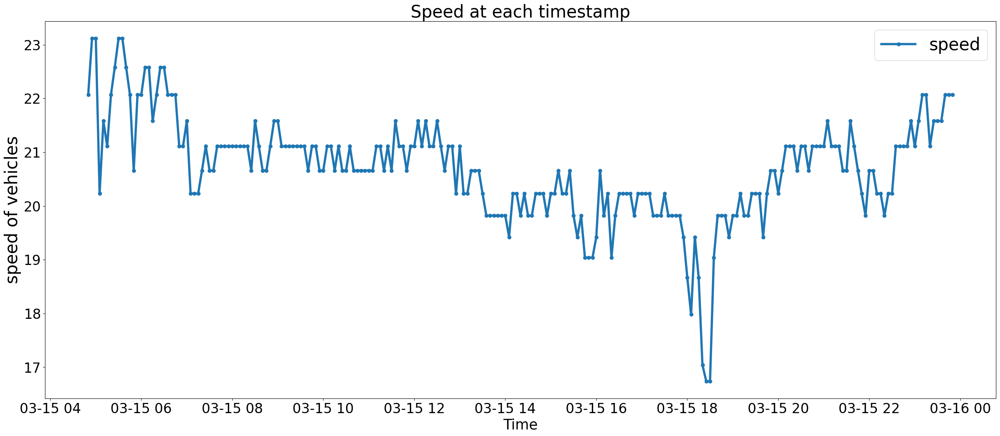

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2708\2708_2022-3-16_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-03-16_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2708_2022-03-16_Fullday.csv
Total of objects in the dataset: 4142
Total of objects that are vehicles in camera 2708 : 4116
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-16 04:50:00         1 2022-03-16 04:5

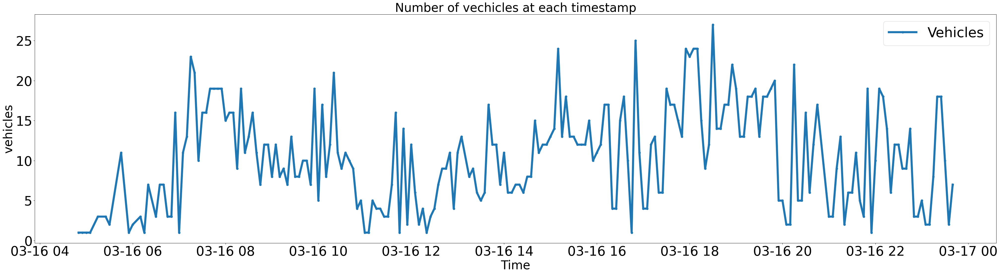

Min, Max speed ::  18.67 23.12


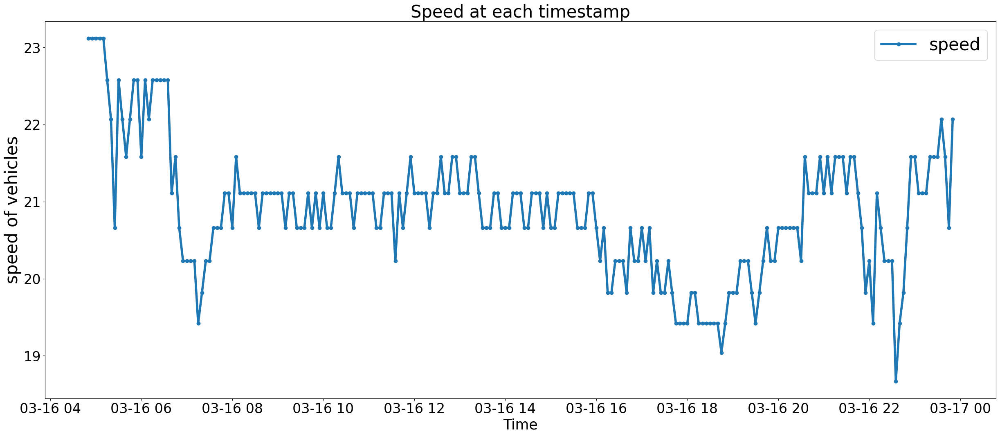

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2708\2708_2022-3-17_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-03-17_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2708_2022-03-17_Fullday.csv
Total of objects in the dataset: 4029
Total of objects that are vehicles in camera 2708 : 3969


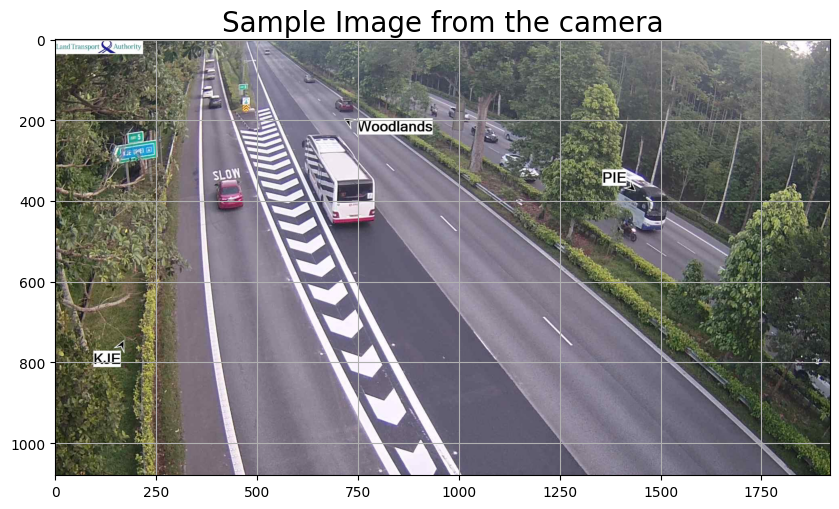

Camera 2708 at 2022-03-17 07:50:00


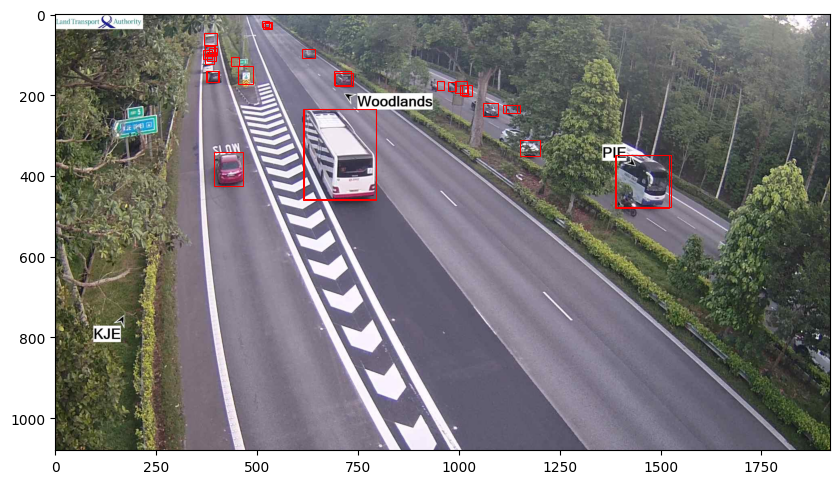

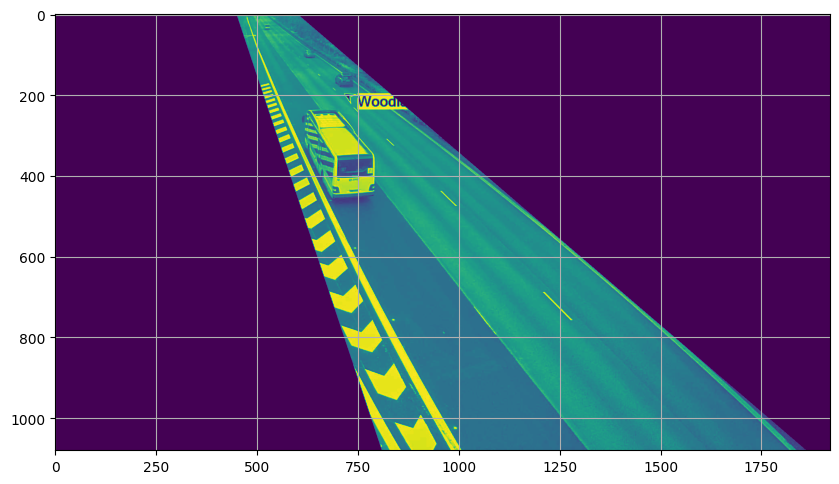

total_area =  3633691
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-17 04:50:00        14 2022-03-17 04:50:00
2022-03-17 04:55:00        11 2022-03-17 04:55:00
2022-03-17 05:00:00        11 2022-03-17 05:00:00
2022-03-17 05:05:00        13 2022-03-17 05:05:00
2022-03-17 05:10:00         1 2022-03-17 05:10:00
...                       ...                 ...
2022-03-17 23:30:00         2 2022-03-17 23:30:00
2022-03-17 23:35:00         5 2022-03-17 23:35:00
2022-03-17 23:40:00         5 2022-03-17 23:40:00
2022-03-17 23:45:00         5 2022-03-17 23:45:00
2022-03-17 23:50:00         3 2022-03-17 23:50:00

[215 rows x 2 columns]>


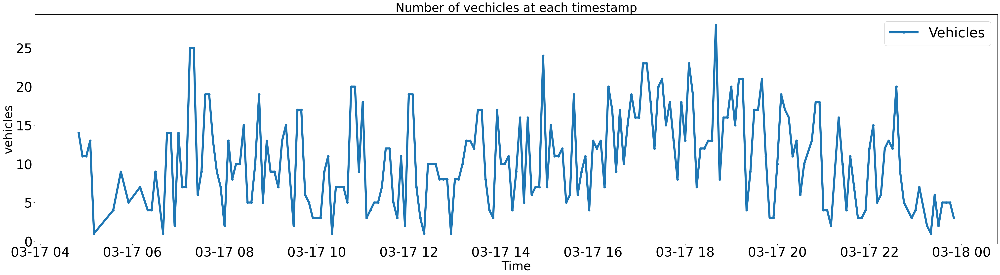

Min, Max speed ::  19.04 23.12


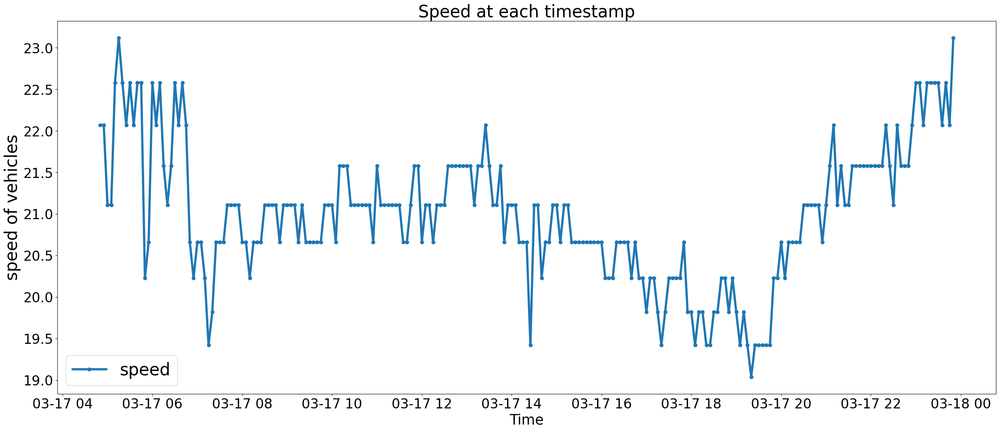

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2708\2708_2022-3-18_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-03-18_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2708_2022-03-18_Fullday.csv
Total of objects in the dataset: 4193
Total of objects that are vehicles in camera 2708 : 4153
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-18 05:00:00         2 2022-03-18 05:0

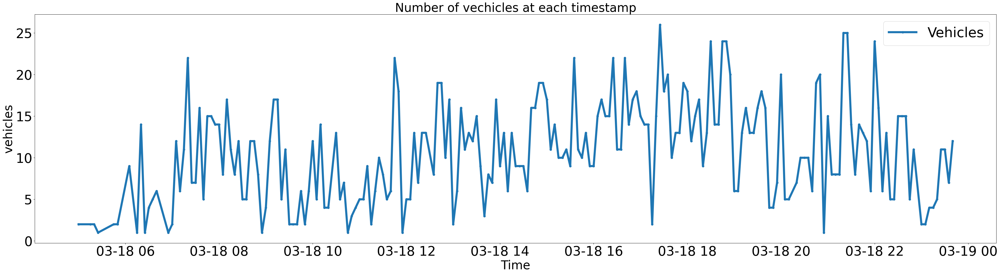

Min, Max speed ::  19.42 23.12


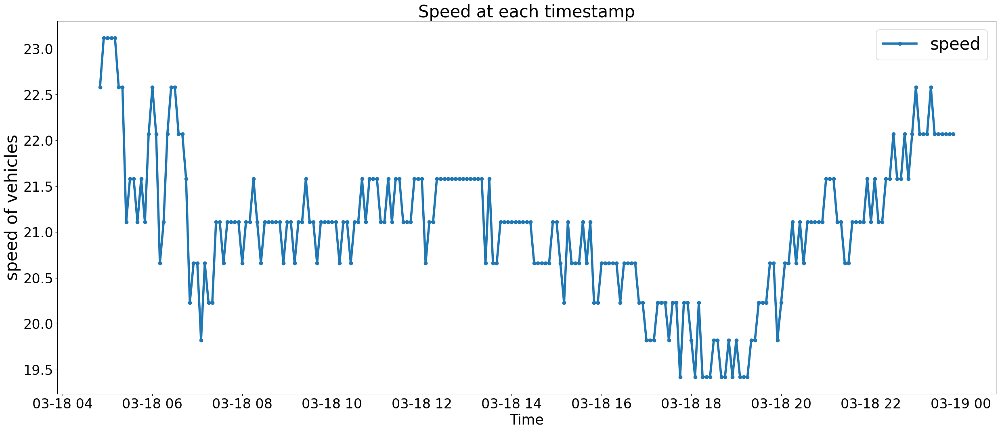

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2708\2708_2022-3-19_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-03-19_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2708_2022-03-19_Fullday.csv
Total of objects in the dataset: 3606
Total of objects that are vehicles in camera 2708 : 3589
maskedList ::  [False, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-19 05:00:00         2 2022-03-19 05:

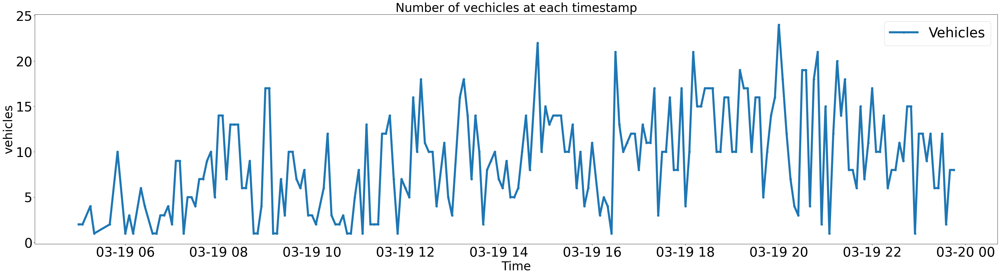

Min, Max speed ::  20.23 23.12


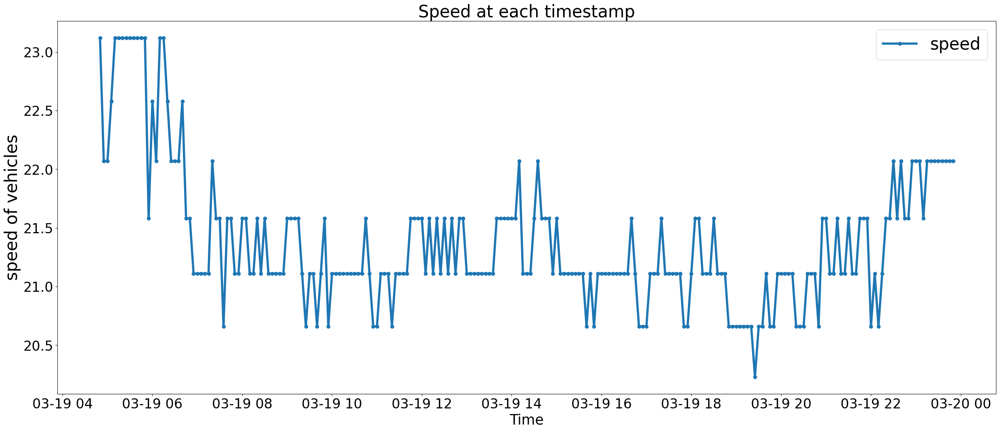

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2708\2708_2022-3-20_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-03-20_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2708_2022-03-20_Fullday.csv
Total of objects in the dataset: 3230
Total of objects that are vehicles in camera 2708 : 3193
maskedList ::  [True, True]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-20 04:50:00         2 2022-03-20 04:5

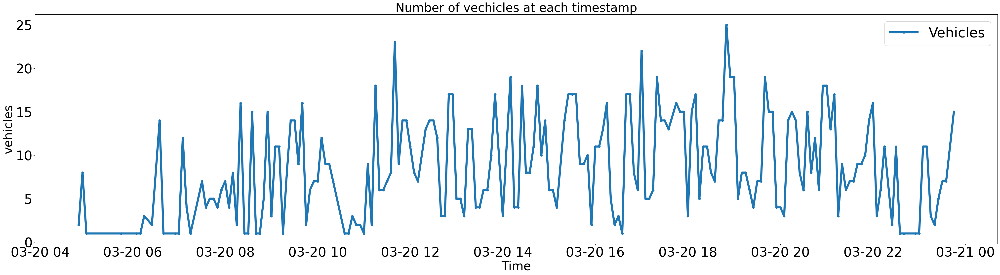

Min, Max speed ::  21.11 23.12


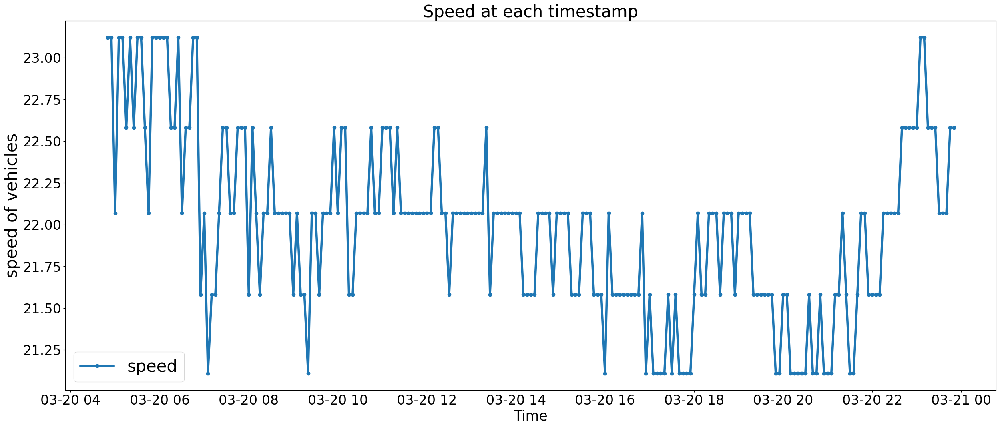

len(combined_df) ::  229
*****************************************************************
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_cnn_2022_transformer\2708\2708_2022-3-21_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\input\march_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-03-21_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\counting_vehicles_4jul_2023\Counting-vehicles-by-direction\output_csv_transformer_test\3\combined_b_Woodlands_2708_2022-03-21_Fullday.csv
Total of objects in the dataset: 4088
Total of objects that are vehicles in camera 2708 : 4055
maskedList ::  [False, False]
Vehicle count and Timestamp
<bound method NDFrame.head of                      vehicles   Timestamp_sg_time
Timestamp_sg_time                                
2022-03-21 05:35:00         1 2022-03-21 05

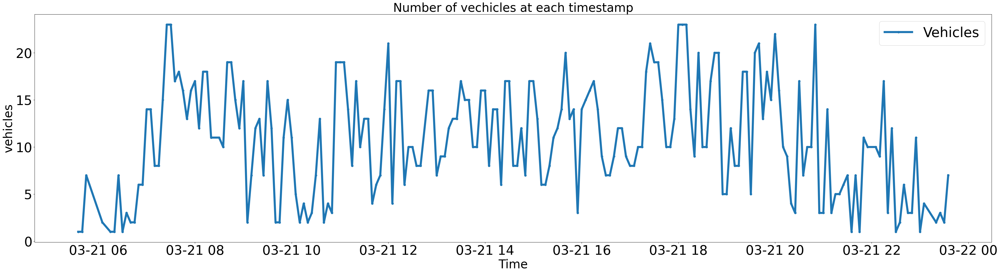

Min, Max speed ::  18.67 23.12


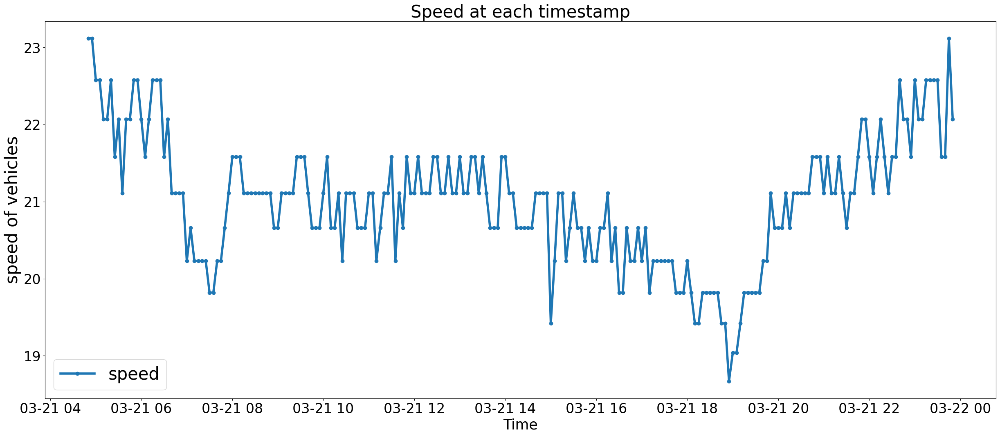

len(combined_df) ::  229
*****************************************************************


In [26]:
for ROUTE_DIR in unique_route:
    pdf  = coord_df.loc[(coord_df['Route']==ROUTE_DIR)]
    for CAMERA_ID in pdf['Cam_id']:
        print(ROUTE_DIR,CAMERA_ID)
        df  = pdf.loc[(pdf['Route']==ROUTE_DIR) & (pdf['Cam_id']==CAMERA_ID)] 
        xy = df['masking_xy_march 2022'].item()
        xy = list(eval(xy))
        print(xy)

        INPUT_DIR_PATH,GOOGLE_PATH,CNN_PATH,ROUTE_PATH,GOOGLE_CAMERA_PATH,CNN_CAMERA_PATH,OUTPUT_CSV_PATH, OUTPUT_IMG_PATH,MASKED_IMG,BB_IMG= define_path(ROUTE_DIR,CAMERA_ID,GOOGLE_DIR,CNN_DIR,MONTH)
        
        #Input
        google_file_list, cnn_file_list = get_google_cnn_file_list(GOOGLE_CAMERA_PATH)
        #xy = findMaskingCoordinates(coord_df,ROUTE_DIR,CAMERA_ID)

        for i in range(len(google_file_list)):
            cnn_csv_file = os.path.join(CNN_CAMERA_PATH , cnn_file_list[i])
            print("cnn_csv_file :: ", cnn_csv_file)

            google_csv_file = os.path.join(GOOGLE_CAMERA_PATH , google_file_list[i]) 
            print("google_csv_file :: ",google_csv_file)

            ## Yet to fix *************
            combined_csv=os.path.join(OUTPUT_CSV_PATH , "combined_"+google_file_list[i])
            print("combined_csv Name :: ",combined_csv)

            df = read_cnn_csv(cnn_csv_file)
            if(i==0 or i==2):
                img, url = check_img_size(df)
                plot_bounding_boxes(df, img,url,BB_IMG)
                masked_img = create_mask(df, img, xy,url,MASKED_IMG)
                total_area  = find_total_area(masked_img)
                
                maskedList = check_masked_List(df, xy)
                df2 = keep_desired_vehicles(df, maskedList)
                
            else:
                maskedList = check_masked_List(df, xy)
                df2 = keep_desired_vehicles(df, maskedList)
                
            #plot_hr_vs_totalvehicles(df2)
            df2_agg = plot_time_vs_totalvehicles(df2)
            df2_agg = aggregate_cnn_data(df2)
            google_df= read_google_csv(google_csv_file)
            speed_df = compute_speed(google_df)
            generate_time_vs_speed(speed_df)

            combined_df = combine_google_lta(df2_agg,speed_df)
            combined_df.to_csv(combined_csv, index=False)

In [ ]:
##https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
#https://www.geeksforgeeks.org/python-pandas-dataframe-corr/
combined_df.corr(method ='pearson')

In [ ]:
def generate_time_vs_speed(combined_df):
    plt.figure(figsize=(30,12))
    plt.plot(combined_df['Timestamp_sg_time'], combined_df['avg_speed'], "-o" , label = 'speed', linewidth=4)
    plt.title("Time and speed of vehicles", fontsize = 30)
    plt.xlabel("Time", fontsize = 25)
    plt.ylabel("speed of vehicles", fontsize =30)
    plt.legend(loc='best' , prop={'size': 30})
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    plt.show()

generate_time_vs_speed(combined_df)

### Time vs Speed vs Number of vehicles

In [ ]:
#https://moonbooks.org/Articles/How-to-change-the-size-of-axis-labels-in-matplotlib-/
#https://stackoverflow.com/questions/52309415/matplotlib-plot-24-hours-with-1-hour-intervals/52309969
#https://unidata.github.io/python-training/workshop/Time_Series/basic-time-series-plotting/
import matplotlib.dates as md
fig, ax = plt.subplots(figsize=(135,55))

ax.plot(combined_df['Timestamp_sg_time'], combined_df['avg_speed'], "-", color = 'blue', label = 'speed', linewidth=9)
ax.plot(combined_df['Timestamp_sg_time'], combined_df['vehicles'], "-o", color = 'green', label = 'Total vehicles', linewidth=9)
ax.legend(loc='best' , prop={'size': 95})
ax.set_xlabel('Time', fontsize = 95)
ax.grid(True)
plt.xticks(fontsize=78)
plt.yticks(fontsize=78)
ax.xaxis.set_major_locator(md.HourLocator(interval = 1))
plt.show()


In [ ]:
#https://stackoverflow.com/questions/61733727/how-to-set-minutes-time-as-x-axis-of-a-matplotlib-plot-in-python
# plot
fig, ax = plt.subplots(figsize=(135,55))
ax.plot(combined_df['Timestamp_sg_time'], combined_df['avg_speed'], "-o", color = 'blue', label = 'speed', linewidth=9)
ax.plot(combined_df['Timestamp_sg_time'], combined_df['vehicles'], "-o", color = 'green', label = 'Total vehicles', linewidth=9)

# From the SO:https://stackoverflow.com/questions/42398264/matplotlib-xticks-every-15-minutes-starting-on-the-hour
## Set time format and the interval of ticks (every 240 minutes)
xformatter = md.DateFormatter('%H:%M')
xlocator = md.MinuteLocator(interval = 60)

## Set xtick labels to appear every 240 minutes
ax.xaxis.set_major_locator(xlocator)
ax.set_xlabel('Time', fontsize = 95)
plt.xticks(fontsize=93)
plt.yticks(fontsize=98)
ax.legend(loc='best' , prop={'size': 95})
ax.set_xlabel('Time', fontsize = 95)

## Format xtick labels as HH:MM
plt.gcf().axes[0].xaxis.set_major_formatter(xformatter)
plt.show()

In [ ]:
#https://stackoverflow.com/questions/53065104/how-can-i-subtract-3-hours-from-a-datetime-in-a-pandas-dataframe-column/53065198#53065198
from datetime import timedelta 
td = pd.Timedelta(4, unit='h')
print(td)

print(combined_df['Timestamp_sg_time'].values[0])
print(combined_df['Timestamp_sg_time'].values[0] + td)
print(combined_df['Timestamp_sg_time'].values[len(combined_df)-1])

In [ ]:
#https://stackoverflow.com/questions/33742588/pandas-split-dataframe-by-column-value
start_time=combined_df['Timestamp_sg_time'].values[0]
end_time=combined_df['Timestamp_sg_time'].values[0] + td
last_time=combined_df['Timestamp_sg_time'].values[len(combined_df)-1]
            
while(end_time < last_time):
    print("Strart Time =",start_time)
    print("End Time =",end_time)
    split_1= combined_df[(combined_df['Timestamp_sg_time'] >= start_time)  & (combined_df['Timestamp_sg_time'] < end_time)]
    
    fig, ax = plt.subplots(figsize=(55,18))
    ax.plot(split_1['Timestamp_sg_time'], split_1['avg_speed'], "-o", color = 'blue', label = 'speed', linewidth=5)
    ax.plot(split_1['Timestamp_sg_time'], split_1['vehicles'], "-o", color = 'green', label = 'Total vehicles', linewidth=5)

    # From the SO:https://stackoverflow.com/questions/42398264/matplotlib-xticks-every-15-minutes-starting-on-the-hour
    ## Set time format and the interval of ticks (every 240 minutes)
    xformatter = md.DateFormatter('%H:%M')
    xlocator = md.MinuteLocator(interval = 20)

    ## Set xtick labels to appear every 240 minutes
    ax.xaxis.set_major_locator(xlocator)
    ax.set_xlabel('Time', fontsize = 45)
    plt.xticks(fontsize=33)
    plt.yticks(fontsize=38)
    ax.legend(loc='best' , prop={'size': 45})
    ax.set_xlabel('Time', fontsize = 45)

    ## Format xtick labels as HH:MM
    plt.gcf().axes[0].xaxis.set_major_formatter(xformatter)
    plt.show()
    
    start_time=end_time
    end_time=end_time+td
    
    if(end_time > last_time):
        end_time=last_time 
    
                         

### Time vs Speed vs Number of vehicles multiple subplots

### Time vs BoundingBox vs Speed

In [ ]:
fig, ax = plt.subplots(figsize=(135,55))
ax.plot(combined_df['Timestamp_sg_time'], combined_df['avg_speed'], "-o", color = 'blue', label = 'speed', linewidth=8)
ax.plot(combined_df['Timestamp_sg_time'], combined_df['bounding_box_area_ratio'], "-o", color = 'green', label = 'bb_area_ratio', linewidth=8)

# From the SO:https://stackoverflow.com/questions/42398264/matplotlib-xticks-every-15-minutes-starting-on-the-hour
## Set time format and the interval of ticks (every 240 minutes)
xformatter = md.DateFormatter('%H:%M')
xlocator = md.MinuteLocator(interval = 60)

## Set xtick labels to appear every 240 minutes
ax.xaxis.set_major_locator(xlocator)
ax.set_xlabel('Time', fontsize = 95)
plt.xticks(fontsize=93)
plt.yticks(fontsize=98)
ax.legend(loc='best' , prop={'size': 95})
ax.set_xlabel('Time', fontsize = 95)

## Format xtick labels as HH:MM
plt.gcf().axes[0].xaxis.set_major_formatter(xformatter)
plt.show()

### Time vs BoundingBox vs Total BoundingBox

In [ ]:

fig, ax = plt.subplots(figsize=(135,55))
ax.plot(combined_df['Timestamp_sg_time'], combined_df['bbratio_less_than_30'], "-o", color = 'green', label = 'bb_less_30', linewidth=9)
ax.plot(combined_df['Timestamp_sg_time'], combined_df['bounding_box_area_ratio'], "-o", color = 'blue', label = 'bb_area_ratio', linewidth=9)

# From the SO:https://stackoverflow.com/questions/42398264/matplotlib-xticks-every-15-minutes-starting-on-the-hour
## Set time format and the interval of ticks (every 240 minutes)
xformatter = md.DateFormatter('%H:%M')
xlocator = md.MinuteLocator(interval = 60)

## Set xtick labels to appear every 240 minutes
ax.xaxis.set_major_locator(xlocator)
ax.set_xlabel('Time', fontsize = 95)
plt.xticks(fontsize=93)
plt.yticks(fontsize=98)
ax.legend(loc='best' , prop={'size': 95})
ax.set_xlabel('Time', fontsize = 95)

## Format xtick labels as HH:MM
plt.gcf().axes[0].xaxis.set_major_formatter(xformatter)
plt.show()

### Time vs BoundingBox vs Total BoundingBox

In [ ]:
fig, ax = plt.subplots(figsize=(135,55))
ax.plot(combined_df['Timestamp_sg_time'], combined_df['bbratio_30_to_39'], "-o", color = 'green', label = 'bb_less_40', linewidth=9)
ax.plot(combined_df['Timestamp_sg_time'], combined_df['bounding_box_area_ratio'], "-o", color = 'blue', label = 'total_bb_area_ratio', linewidth=9)

# From the SO:https://stackoverflow.com/questions/42398264/matplotlib-xticks-every-15-minutes-starting-on-the-hour
## Set time format and the interval of ticks (every 240 minutes)
xformatter = md.DateFormatter('%H:%M')
xlocator = md.MinuteLocator(interval = 60)

## Set xtick labels to appear every 240 minutes
ax.xaxis.set_major_locator(xlocator)
ax.set_xlabel('Time', fontsize = 95)
plt.xticks(fontsize=93)
plt.yticks(fontsize=98)
ax.legend(loc='best' , prop={'size': 95})
ax.set_xlabel('Time', fontsize = 95)

## Format xtick labels as HH:MM
plt.gcf().axes[0].xaxis.set_major_formatter(xformatter)
plt.show()